# Default-Rate Driver Scan — Exploratory Data Analysis
### Flagship PD Model Project · Stage 1 (EDA)

> **Objective.** Identify and evidence the primary drivers of loan default in the Home Credit application data, and translate those findings into binning decisions (WOE / IV) that feed the downstream PD scorecard.

| Field | Detail |
|---|---|
| **Project** | Flagship PD Model — Project 1: Default-Rate Driver Scan |
| **Stage** | Stage 1 — Exploratory Data Analysis |
| **Dataset** | Home Credit Default Risk — `application_train` (primary table) |
| **Target** | `TARGET` (1 = default / serious delinquency, 0 = repaid) |
| **Author** | *&lt;your name&gt;* |
| **AI assistance** | Built with AI assistance (Claude): code cells marked "Written by AI", helper functions, explanations and editing of the write-ups. Predictions and final decisions reviewed by the author. |
| **Date started / last updated** | *&lt;YYYY-MM-DD&gt;* / *&lt;YYYY-MM-DD&gt;* |
| **Notebook version** | *&lt;v0.x — draft&gt;* |

**Reading guide — the E / O / D convention.** Each analysis block is written as three linked notes so a reviewer can follow the reasoning end to end:
- **Explanation** — the hypothesis / business rationale *before* looking at the data (what we expect and why).
- **Observation** — what the data actually showed, read straight off the output above.
- **Decision** — the action taken and its justification (binning strategy, keep / drop, treatment carried into Section 5).

**Reproducibility.** *(placeholder — record Python version, key library versions, random seed(s), the data snapshot/date, and any manual steps needed to re-run this notebook top-to-bottom.)*


## Contents

- **Project Setup** — environment & imports, display settings, style guide, data loading
- **1. First Look** — data shape, class imbalance, description lookup reference
- **2. Data Quality & Missingness** — statistical subsets · thematic subsets · missingness assessment · cardinality assessment
- **3. Feature Analysis** — per-family univariate + bivariate scan (External Scores · Loan Financials · Age & Employment · Demographics · Other Numericals)
- **4. Feature Engineering** — candidate credit ratios · bivariate sanity check
- **5. WOE / IV Computation** — split & binning inputs · learning optbinning · IV ranking · top drivers · WOE encoding
- **6. Findings Summary** — consolidated drivers and data-quality conclusions
- **7. Next Steps** — actions carried into modelling
- **8. Assumptions, Limitations & Data Lineage** — caveats and reproducibility record

*(placeholder — once section numbering is final, these can be converted to in-notebook anchor links.)*


# Project Setup

## Environment and Imports

Imports, repo paths and the project's own utilities (`python_style_util`, `evaluation_utils`, `credit_utils`). `credit_utils` is auto-reloaded, so edits to its modules show up without restarting the kernel.

In [1]:
# Standard library
import os
import sys
import warnings
import math


# Data
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker
from matplotlib import cm, colors

# Machine learning
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Jupyter
from IPython.core.interactiveshell import InteractiveShell
from IPython.display import display




# Repo paths
def find_repo_root(start, marker='lib'):
    path = os.path.abspath(start)
    while True:
        if os.path.isdir(os.path.join(path, marker)):
            return path
        parent = os.path.dirname(path)
        if parent == path:
            raise FileNotFoundError(f"No '{marker}' folder found above {start}")
        path = parent


repo_root = find_repo_root(os.getcwd())
sys.path.append(os.path.join(repo_root, 'lib'))

# Style utils
from python_style_util import (
    palette, fonts, sizes,
    p, f, s,
    C, Shade, Size,
    set_style,
    gradient, traffic_light, diverging, diverging_cmap, risk_cmap, RISK_LOW, RISK_HIGH,
    multi_series, binary_palette,
    chart_title, annotate, style_df,
    show_palette, show_fonts, show_tokens, show_colormaps, show_style_guide,
)
import evaluation_utils as eu
import missingno as msno        # missingness assessment functions

# Project toolkit (credit_utils)
%load_ext autoreload
%autoreload 2

from credit_utils import eda, quality, woe, stats, style

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Display Settings

Pandas, NumPy and Matplotlib display options, plus the project chart style.

In [2]:
# Pandas
pd.set_option('display.float_format', '{:.2f}'.format)  # 2 decimal places on floats
pd.set_option('display.max_columns', None)              # show all columns
pd.set_option('display.max_rows', 100)                  # show up to 100 rows
pd.set_option('display.width', None)                    # don't wrap wide dataframes
pd.set_option('display.colheader_justify', 'left')      # left-align column headers
pd.set_option('display.precision', 4)                   # decimal precision for describe()
pd.set_option('display.large_repr', 'truncate')         # truncate instead of summary for large dfs

# NumPy
np.set_printoptions(
    precision=4,        # decimal places
    suppress=True,      # no scientific notation
    linewidth=120,      # wrap width
    threshold=1000,     # show up to 1000 elements before summarising with ...
    edgeitems=5,        # show 5 items at each end when it does summarise
)

# Matplotlib
%matplotlib inline
plt.rcParams['figure.dpi'] = 120             # sharper figures
plt.rcParams['savefig.dpi'] = 150            # higher res when saving
plt.rcParams['savefig.bbox'] = 'tight'       # no clipped labels when saving
plt.rcParams['savefig.facecolor'] = 'white'  # white background on saved figures

# Jupyter
InteractiveShell.ast_node_interactivity = 'all'  # print every expression, not just the last

# Warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Style
set_style()

## Style Guide

Quick visual reference for the project's colour tokens and fonts.

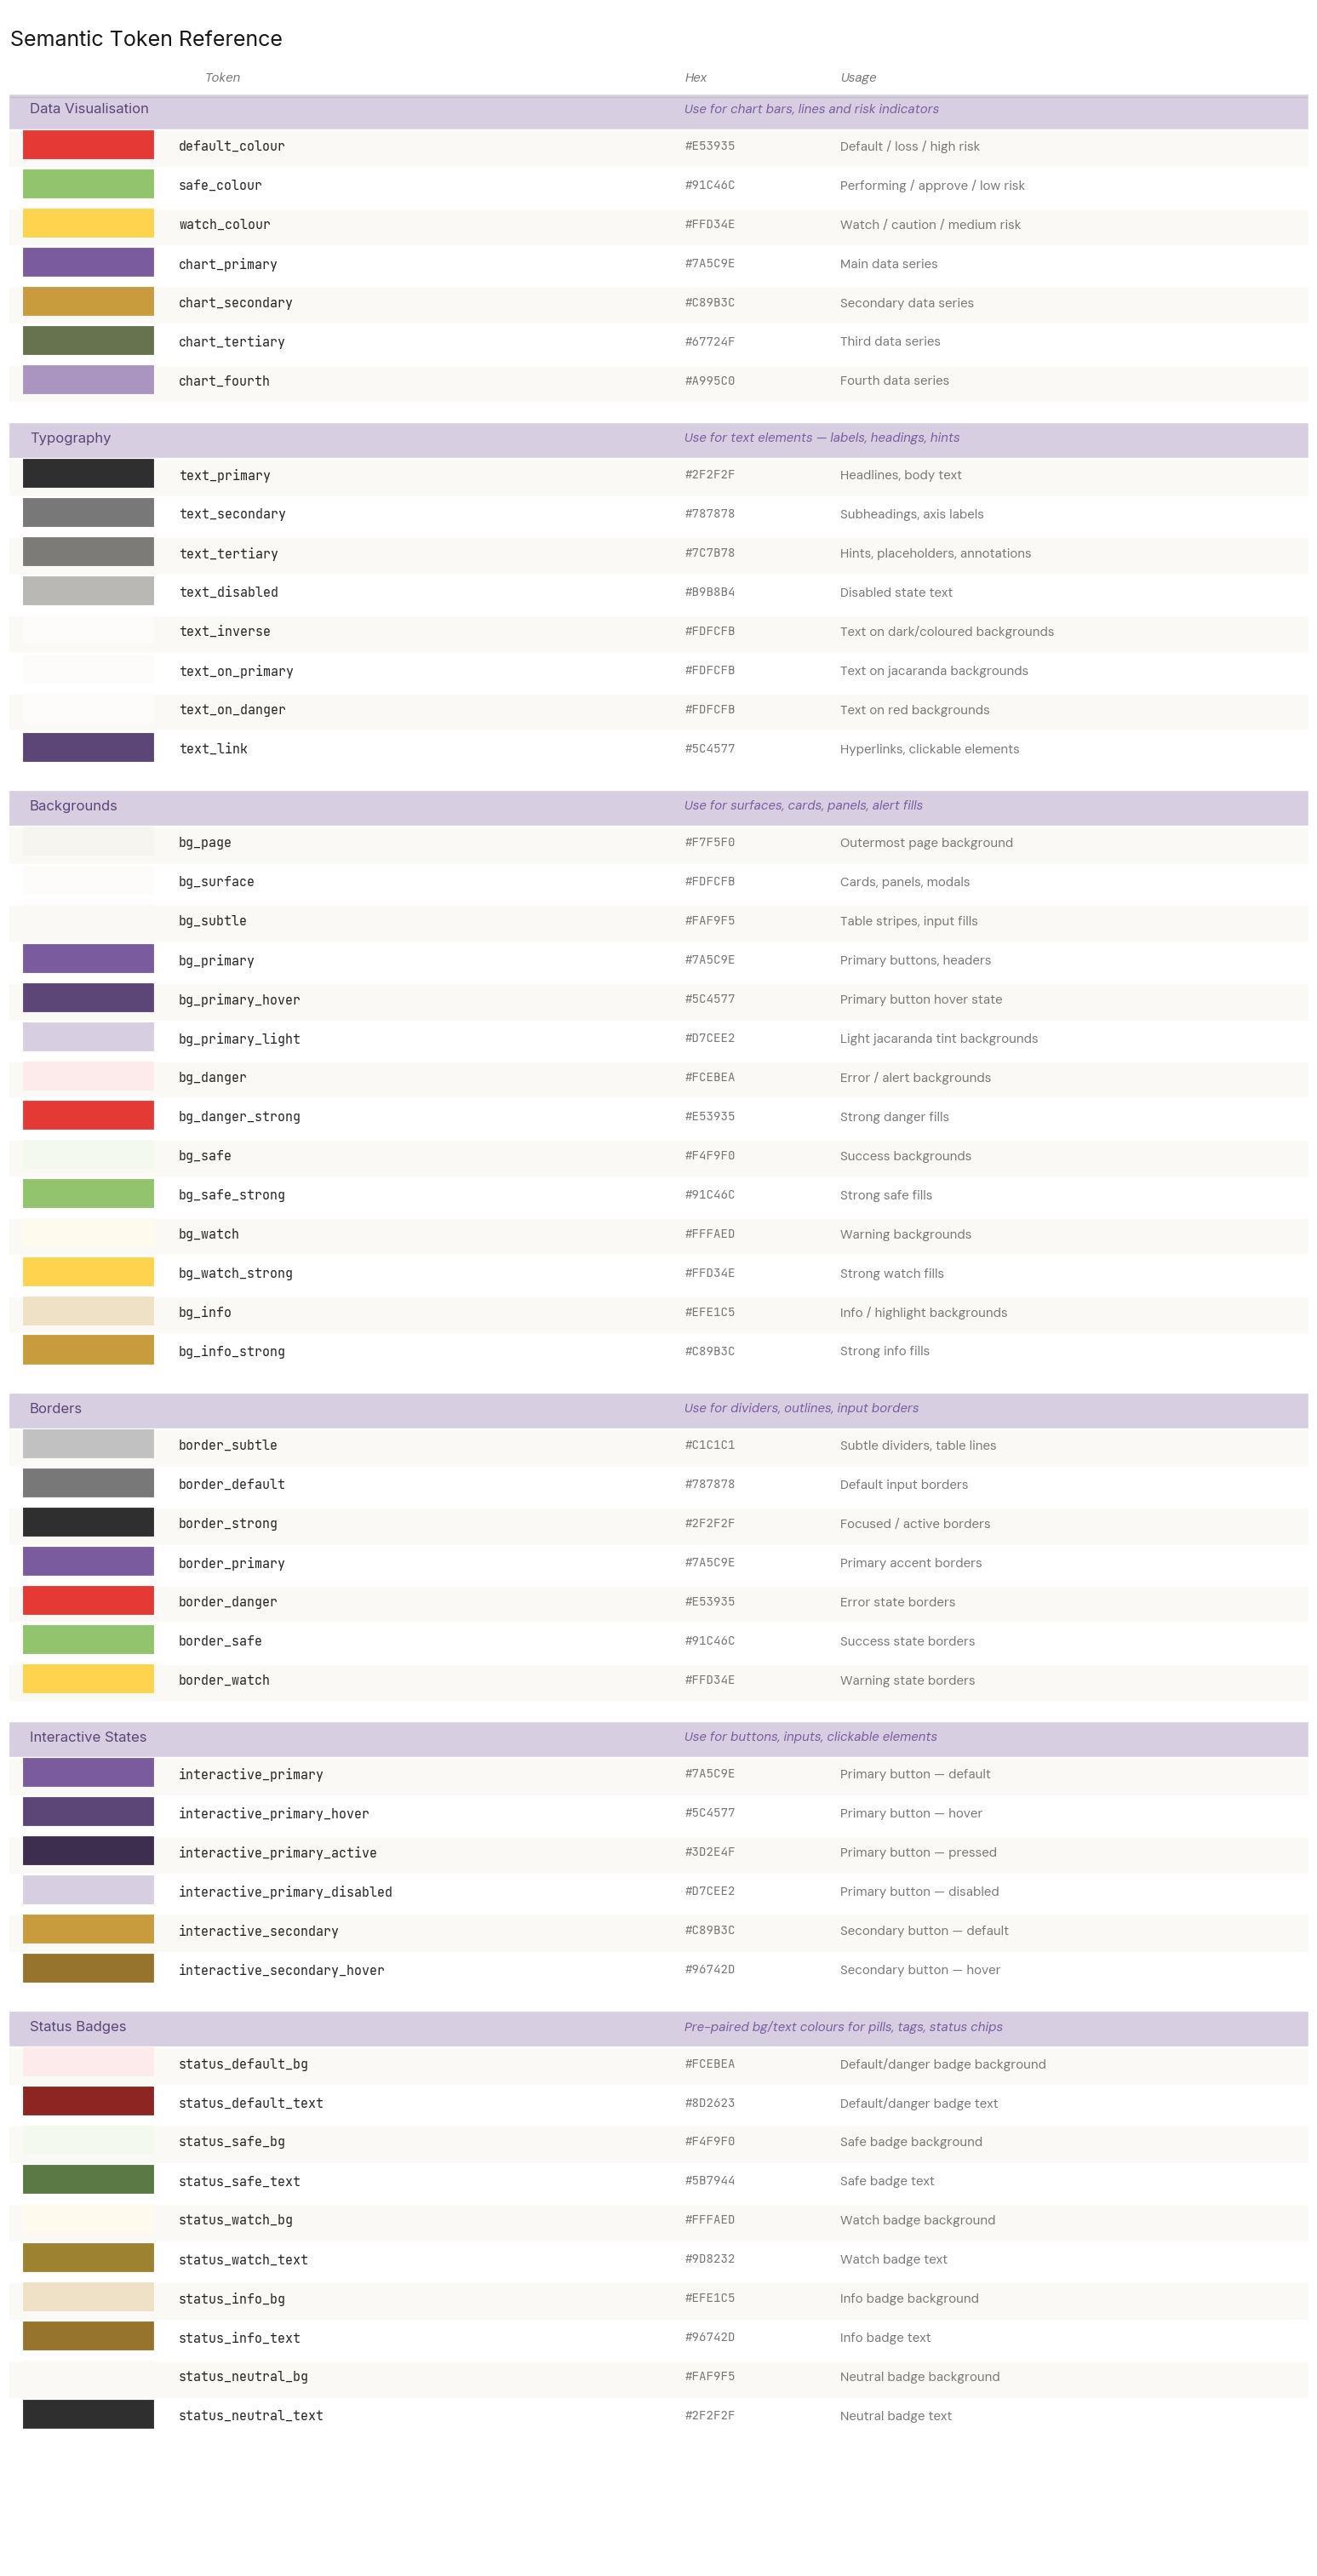

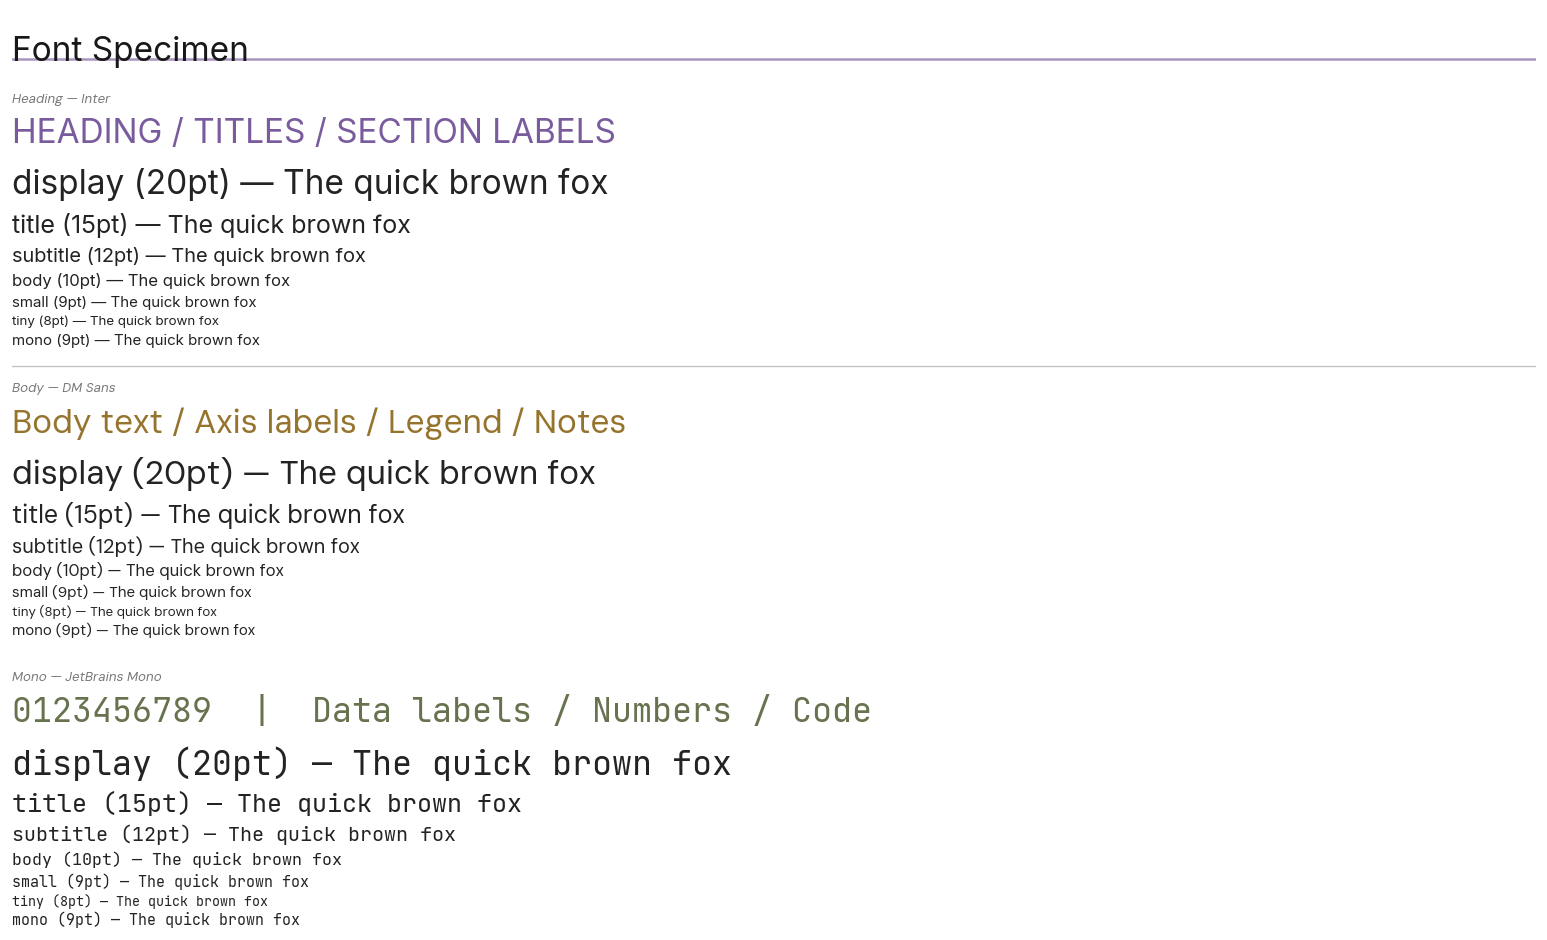

In [3]:
# Colour tokens and fonts
show_tokens()
show_fonts()

## Data Loading

Loads `application_train` and the column description file from the repo's Datasets folder.

In [4]:
# Application data
DATA_PATH = os.path.join(repo_root, 'Datasets', 'Home Credit Default Risk', 'application_train.csv')

df = pd.read_csv(DATA_PATH)
print(f"Loaded {df.shape[0]:,} rows × {df.shape[1]} columns from {DATA_PATH}")
df.head()

# Column descriptions
desc = pd.read_csv('../../../Datasets/Home Credit Default Risk/HomeCredit_columns_description.csv', sep=',', encoding='cp1252')

Loaded 307,511 rows × 122 columns from e:\Dev\CreditRiskLearning\Datasets\Home Credit Default Risk\application_train.csv


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.00,406597.50,24700.50,351000.00,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.02,-9461,-637,-3648.00,-2120,NaN,1,1,0,1,1,0,Laborers,1.00,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.08,0.26,0.14,0.02,0.04,0.97,0.62,0.01,0.00,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,0.03,0.04,0.97,0.63,0.01,0.00,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,0.03,0.04,0.97,0.62,0.01,0.00,0.07,0.08,0.12,0.04,0.02,0.02,0.00,0.00,reg oper account,block of flats,0.01,"Stone, brick",No,2.00,2.00,2.00,2.00,-1134.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,1.00
1,100003,0,Cash loans,F,N,N,0,270000.00,1293502.50,35698.50,1129500.00,Family,State servant,Higher education,Married,House / apartment,0.00,-16765,-1188,-1186.00,-291,NaN,1,1,0,1,1,0,Core staff,2.00,1,1,MONDAY,11,0,0,0,0,0,0,School,0.31,0.62,NaN,0.10,0.05,0.99,0.80,0.06,0.08,0.03,0.29,0.33,0.01,0.08,0.05,0.00,0.01,0.09,0.05,0.99,0.80,0.05,0.08,0.03,0.29,0.33,0.01,0.08,0.06,0.00,0.00,0.10,0.05,0.99,0.80,0.06,0.08,0.03,0.29,0.33,0.01,0.08,0.06,0.00,0.01,reg oper account,block of flats,0.07,Block,No,1.00,0.00,1.00,0.00,-828.00,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00
2,100004,0,Revolving loans,M,Y,Y,0,67500.00,135000.00,6750.00,135000.00,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.01,-19046,-225,-4260.00,-2531,26.00,1,1,1,1,1,0,Laborers,1.00,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.56,0.73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,-815.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.0

# Project Body

## 1. First Look

### Data Shape

**Explanation:** Expecting large dataset with significant breadth and volume 

In [5]:
df.shape

(307511, 122)

**Observation:** 300k+ Rows and 122 Columns. 

**Decision:** Will need to split into statistical categories and potentially similar buckets (i.e. applicant data, security data, social data) for further assessment as attempting look at this number of columns as a whole group will make it difficult to draw tangible conclusions.

### Class Imbalance

**Explanation:** Typically defaulters are a very small percentage of a mortgage loan book as the financial health of bank is reliant on this percentage staying low given the huge losses taken upon mortgage default.

In [6]:
# Percentage distribution

(df["TARGET"].value_counts(normalize=True) * 100).round(5)

# Raw value counts

df['TARGET'].value_counts(dropna=False) 

TARGET
0   91.93
1    8.07
Name: proportion, dtype: float64

TARGET
0    282686
1     24825
Name: count, dtype: int64

**Observation:** 92% Non Defaulters vs 8% Defaulters

**Decision:** Non-Defaulters make up a large portion of the loan book as expected. An 8% default rate is high relative to a prime mortgage book, but this is Home Credit — a consumer-finance lender serving thin-file / underbanked borrowers — so ~8% is roughly the expected base rate for this segment rather than a sign of distress. It reflects the lender deliberately pricing in a riskier target market through rates/fees, and there are likely addressable applicant segments driving the rate, which this driver scan aims to surface.

No resampling will occur as this is purely a screening exercise, not model training. WOE/IV are computed on the full distribution, so class imbalance is a constraint to respect.

### Description Lookup Reference

A quick reference lookup for the description of what each of the columns represent. Useful in initial stages when assessing business relevance of each feature for unviariate analysis and feature selection. Descriptions are filtered to the application table first, since the same column name can appear in more than one of the 7 source tables.

In [7]:
# Application table descriptions only
desc_app = desc[desc['Table'] == 'application_{train|test}.csv'].set_index('Row')

description_index = {}

for column in df.columns:
    if column in desc_app.index:
        description_index[column] = desc_app.loc[column, 'Description']
        
        
description_index['NAME_CONTRACT_TYPE']

'Identification if loan is cash or revolving'

## 2. Data Quality and Missingness

**Explanation:** Expecting large portion of data to be missing for various reasons, such as length of employment missing due to an applicant potentially being unemployed (MNAR). These types of missingness relationship will be established across variables by looking at cross-validation.

### 2.1 Statistical Subsets

Splitting data up into continuous, discrete, nominal, ordinal and binary subsets.

A first pass labels binary and continuous columns automatically from their number of unique values. The remaining columns are printed with their descriptions and typed manually. The lookup is then inverted so a whole type can be selected at once (e.g. `df[cols_by_type['discrete']]`), and a final check confirms every column has a valid type.

In [8]:
# First pass - binary and continuous by number of unique values
statistical_type_index = {}

nunique_counts = df.nunique()

for column in df.columns:
    
    n_unique = nunique_counts[column]
    
    dtype = df[column].dtype
    
    if n_unique == 2:
        statistical_type_index[column] = 'binary'
        
    elif n_unique > 50 and dtype in ['float64', 'int64']:
        statistical_type_index[column] = 'continuous'
    
    else:
        statistical_type_index[column] = 'needs review'
    
# Print the rest for manual review
review_cols = [col for col, label in statistical_type_index.items() if label == 'needs review']

for col in review_cols:
    print(col, df[col].unique()[:10], description_index.get(col))
    

CODE_GENDER <ArrowStringArray>
['M', 'F', 'XNA']
Length: 3, dtype: str Gender of the client
CNT_CHILDREN [0 1 2 3 4 7 5 6 8 9] Number of children the client has
NAME_TYPE_SUITE <ArrowStringArray>
[  'Unaccompanied',          'Family', 'Spouse, partner',        'Children',
         'Other_A',               nan,         'Other_B', 'Group of people']
Length: 8, dtype: str Who was accompanying client when he was applying for the loan
NAME_INCOME_TYPE <ArrowStringArray>
[             'Working',        'State servant', 'Commercial associate',
            'Pensioner',           'Unemployed',              'Student',
          'Businessman',      'Maternity leave']
Length: 8, dtype: str Clients income type (businessman, working, maternity leave,…)
NAME_EDUCATION_TYPE <ArrowStringArray>
['Secondary / secondary special',              'Higher education',
             'Incomplete higher',               'Lower secondary',
               'Academic degree']
Length: 5, dtype: str Level of highest educa

In [9]:
# Fix up SK_ID_CURR - add as an 'id' column

statistical_type_index.update(dict.fromkeys(['SK_ID_CURR'], 'id'))

# CODE_GENDER

statistical_type_index.update(dict.fromkeys(['CODE_GENDER'], 'binary'))

# CNT_CHILDREN

statistical_type_index.update(dict.fromkeys(['CNT_CHILDREN'], 'discrete'))

# NAME_TYPE_SUITE

statistical_type_index.update(dict.fromkeys(['NAME_TYPE_SUITE'], 'categorical'))

# NAME_INCOME_TYPE

statistical_type_index.update(dict.fromkeys(['NAME_INCOME_TYPE'], 'categorical'))

# NAME_EDUCATION_TYPE

statistical_type_index.update(dict.fromkeys(['NAME_EDUCATION_TYPE'], 'categorical'))

# NAME_FAMILY_STATUS

statistical_type_index.update(dict.fromkeys(['NAME_FAMILY_STATUS'], 'categorical'))

# NAME_HOUSING_TYPE

statistical_type_index.update(dict.fromkeys(['NAME_HOUSING_TYPE'], 'categorical'))

# OCCUPATION_TYPE

statistical_type_index.update(dict.fromkeys(['OCCUPATION_TYPE'], 'categorical'))

# CNT_FAM_MEMBERS

statistical_type_index.update(dict.fromkeys(['CNT_FAM_MEMBERS'], 'discrete'))

# REGION_RATING_CLIENT

statistical_type_index.update(dict.fromkeys(['REGION_RATING_CLIENT'], 'ordinal'))

# REGION_RATING_CLIENT_W_CITY

statistical_type_index.update(dict.fromkeys(['REGION_RATING_CLIENT_W_CITY'], 'ordinal'))

# WEEKDAY_APPR_PROCESS_START

statistical_type_index.update(dict.fromkeys(['WEEKDAY_APPR_PROCESS_START'], 'categorical'))

# HOUR_APPR_PROCESS_START

statistical_type_index.update(dict.fromkeys(['HOUR_APPR_PROCESS_START'], 'categorical'))

# ORGANIZATION_TYPE

statistical_type_index.update(dict.fromkeys(['ORGANIZATION_TYPE'], 'categorical'))

# ELEVATORS_MODE

statistical_type_index.update(dict.fromkeys(['ELEVATORS_MODE'], 'continuous'))

# ENTRANCES_MODE	

statistical_type_index.update(dict.fromkeys(['ENTRANCES_MODE'], 'continuous'))

# FLOORSMAX_MODE

statistical_type_index.update(dict.fromkeys(['FLOORSMAX_MODE'], 'continuous'))

# FLOORSMIN_MODE

statistical_type_index.update(dict.fromkeys(['FLOORSMIN_MODE'], 'continuous'))

# ELEVATORS_MEDI	

statistical_type_index.update(dict.fromkeys(['ELEVATORS_MEDI'], 'continuous'))

# ENTRANCES_MEDI

statistical_type_index.update(dict.fromkeys(['ENTRANCES_MEDI'], 'continuous'))

# FLOORSMAX_MEDI

statistical_type_index.update(dict.fromkeys(['FLOORSMAX_MEDI'], 'continuous'))

# FLOORSMIN_MEDI

statistical_type_index.update(dict.fromkeys(['FLOORSMIN_MEDI'], 'continuous'))

# FONDKAPREMONT_MODE

statistical_type_index.update(dict.fromkeys(['FONDKAPREMONT_MODE'], 'categorical'))

# HOUSETYPE_MODE

statistical_type_index.update(dict.fromkeys(['HOUSETYPE_MODE'], 'categorical'))

# WALLSMATERIAL_MODE

statistical_type_index.update(dict.fromkeys(['WALLSMATERIAL_MODE'], 'categorical'))

# OBS_30_CNT_SOCIAL_CIRCLE

statistical_type_index.update(dict.fromkeys(['OBS_30_CNT_SOCIAL_CIRCLE'], 'discrete'))

# DEF_30_CNT_SOCIAL_CIRCLE

statistical_type_index.update(dict.fromkeys(['DEF_30_CNT_SOCIAL_CIRCLE'], 'discrete'))

# OBS_60_CNT_SOCIAL_CIRCLE

statistical_type_index.update(dict.fromkeys(['OBS_60_CNT_SOCIAL_CIRCLE'], 'discrete'))

# DEF_60_CNT_SOCIAL_CIRCLE

statistical_type_index.update(dict.fromkeys(['DEF_60_CNT_SOCIAL_CIRCLE'], 'discrete'))

# AMT_REQ_CREDIT_BUREAU_HOUR

statistical_type_index.update(dict.fromkeys(['AMT_REQ_CREDIT_BUREAU_HOUR'], 'discrete'))

# AMT_REQ_CREDIT_BUREAU_DAY	

statistical_type_index.update(dict.fromkeys(['AMT_REQ_CREDIT_BUREAU_DAY'], 'discrete'))

# AMT_REQ_CREDIT_BUREAU_WEEK

statistical_type_index.update(dict.fromkeys(['AMT_REQ_CREDIT_BUREAU_WEEK'], 'discrete'))

# AMT_REQ_CREDIT_BUREAU_MON

statistical_type_index.update(dict.fromkeys(['AMT_REQ_CREDIT_BUREAU_MON'], 'discrete'))

# AMT_REQ_CREDIT_BUREAU_QRT

statistical_type_index.update(dict.fromkeys(['AMT_REQ_CREDIT_BUREAU_QRT'], 'discrete'))

# AMT_REQ_CREDIT_BUREAU_YEAR

statistical_type_index.update(dict.fromkeys(['AMT_REQ_CREDIT_BUREAU_YEAR'], 'discrete'))


In [10]:
# Inverting statistical reference lookup so that columns can be called easier - e.g. df[cols_by_type['discrete']]

from collections import defaultdict

cols_by_type = defaultdict(list)
for col, t in statistical_type_index.items():
    cols_by_type[t].append(col)

In [11]:
# Statistical Type Dictionary Lookup

df[cols_by_type['discrete']]

,CNT_CHILDREN,CNT_FAM_MEMBERS,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,0,1.00,2.00,2.00,2.00,2.00,0.00,0.00,0.00,0.00,0.00,1.00
1,0,2.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,0,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,0,2.00,2.00,0.00,2.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...
307506,0,1.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN
307507,0,1.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN
307508,0,1.00,6.00,0.00,6.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00
307509,0,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [12]:
# Sanity check that all the columns have been assigned statistical types
# Written by AI

assert set(df.columns) == set(statistical_type_index), \
    set(df.columns) ^ set(statistical_type_index)

valid = {'binary','discrete','continuous','categorical','ordinal', 'id'}
bad = {c: t for c, t in statistical_type_index.items() if t not in valid}
assert not bad, bad          # this would have caught 'cateogrical'

df.shape
len(statistical_type_index)

(307511, 122)

122

### 2.2 Thematic Subsets

Due to the width of the dataset and the size of some of the statistical subsets the data will also be split into thematic subsets. These are based on the qualitative nature of the data (i.e. loan data, credit bureau data, security data etc..)

Core columns are assigned to themes explicitly. The large regular families (building stats, document flags, bureau enquiries, social circle, region) are matched by name pattern, and a coverage check prints any column left unassigned so nothing drops out silently.

In [13]:
# Written by AI

import re

thematic_type_index = {}

# Explicit themes for core columns
explicit_themes = {
    'id_target':          ['SK_ID_CURR', 'TARGET'],
    'external_scores':    ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'],
    'loan_financials':    ['NAME_CONTRACT_TYPE', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
                           'AMT_ANNUITY', 'AMT_GOODS_PRICE'],
    'demographics':       ['CODE_GENDER', 'DAYS_BIRTH', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS',
                           'NAME_FAMILY_STATUS', 'NAME_EDUCATION_TYPE', 'NAME_HOUSING_TYPE',
                           'NAME_TYPE_SUITE'],
    'employment':         ['NAME_INCOME_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE',
                           'DAYS_EMPLOYED'],
    'assets':             ['FLAG_OWN_CAR', 'OWN_CAR_AGE', 'FLAG_OWN_REALTY'],
    'contact':            ['FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE',
                           'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL'],
    'client_timeline':    ['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE'],
    'application_timing': ['WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START'],
}
for theme, cols in explicit_themes.items():
    for c in cols:
        if c in df.columns:
            thematic_type_index[c] = theme

# Pattern rules for large families (first match wins)
pattern_rules = [
    ('document_flags',   r'^FLAG_DOCUMENT_\d+$'),
    ('bureau_enquiries', r'^AMT_REQ_CREDIT_BUREAU_'),
    ('social_circle',    r'_CNT_SOCIAL_CIRCLE$'),
    ('region',           r'^(REGION_|REG_|LIVE_)'),
    ('building_stats',   r'(_AVG|_MODE|_MEDI)$'),
]
for col in df.columns:
    if col in thematic_type_index:
        continue
    for theme, pattern in pattern_rules:
        if re.search(pattern, col):
            thematic_type_index[col] = theme
            break

# Coverage check
unassigned = [c for c in df.columns if c not in thematic_type_index]
print(f"Assigned {len(thematic_type_index)}/{len(df.columns)} columns across "
      f"{len(set(thematic_type_index.values()))} themes")
if unassigned:
    print("\nUNASSIGNED (add to explicit_themes above):")
    for c in unassigned:
        print(f"  {c:32s} nunique={df[c].nunique():>4}  {description_index.get(c, '')}")


Assigned 122/122 columns across 14 themes


In [14]:
# Written by AI

# Invert to theme -> columns
from collections import defaultdict

cols_by_theme = defaultdict(list)
for col, theme in thematic_type_index.items():
    cols_by_theme[theme].append(col)

# Theme sizes, largest first
for theme in sorted(cols_by_theme, key=lambda t: -len(cols_by_theme[t])):
    members = cols_by_theme[theme]
    print(f"{theme:20s} {len(members):3d}   e.g. {members[:3]}")


building_stats        47   e.g. ['APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG']
document_flags        20   e.g. ['FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_4']
region                 9   e.g. ['REGION_POPULATION_RELATIVE', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY']
demographics           8   e.g. ['CODE_GENDER', 'DAYS_BIRTH', 'CNT_CHILDREN']
contact                6   e.g. ['FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE']
bureau_enquiries       6   e.g. ['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK']
loan_financials        5   e.g. ['NAME_CONTRACT_TYPE', 'AMT_INCOME_TOTAL', 'AMT_CREDIT']
employment             4   e.g. ['NAME_INCOME_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
social_circle          4   e.g. ['OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE']
external_scores        3   e.g. ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
assets                 3  

These subsets can now be called via the inverse dictionary created here via: 

<span style="font-size:20px"> **df[cols_by_theme['subset_name']]**</span>

### 2.3 Missingness Assessment

#### Data Flagging (DAYS_EMPLOYED)

**DAYS_EMPLOYED**

The value '365243' within the DAYS_EMPLOYED column is technically a null value disguised as real entry. This value must be flagged and replaced with 'NaN' before proceeding with the missingness assessment.

**CODE_GENDER**

The value 'XNA' functions in the same way as the '365243' value in DAYS_EMPLOYED and must be handled the same way.

In [15]:
# DAYS_EMPLOYED

df['DAYS_EMPLOYED_SENTINEL'] = df['DAYS_EMPLOYED'] == 365243

df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)

df['DAYS_EMPLOYED'].value_counts(dropna=False)

# CODE_GENDER

df = df[df['CODE_GENDER'] != 'XNA']

df['CODE_GENDER'].value_counts(dropna=False)

DAYS_EMPLOYED
NaN          55374
-200.00        156
-224.00        152
-199.00        151
-230.00        151
             ...  
-12316.00        1
-11100.00        1
-12971.00        1
-11084.00        1
-8694.00         1
Name: count, Length: 12574, dtype: int64

CODE_GENDER
F    202448
M    105059
Name: count, dtype: int64

**Decision**: Flagged with a sentinel/boolean mask for the DAYS_EMPLOYED column and replaced with 'NaN'.

For the CODE_GENDER columns there were only 4 XNA values so ultimately decided to drop the rows and forgo a sentinel column.

#### Overall Missingness Percentage (Ranked)

Visualisation of Missingness for Columns with > 5% of data missing. Does not account for incorrect missing entries. 

**Explanation:** There are columns with a majority of data missing that require further analysis to determine nature of their missingness and whether they can still be used as features for training various models.

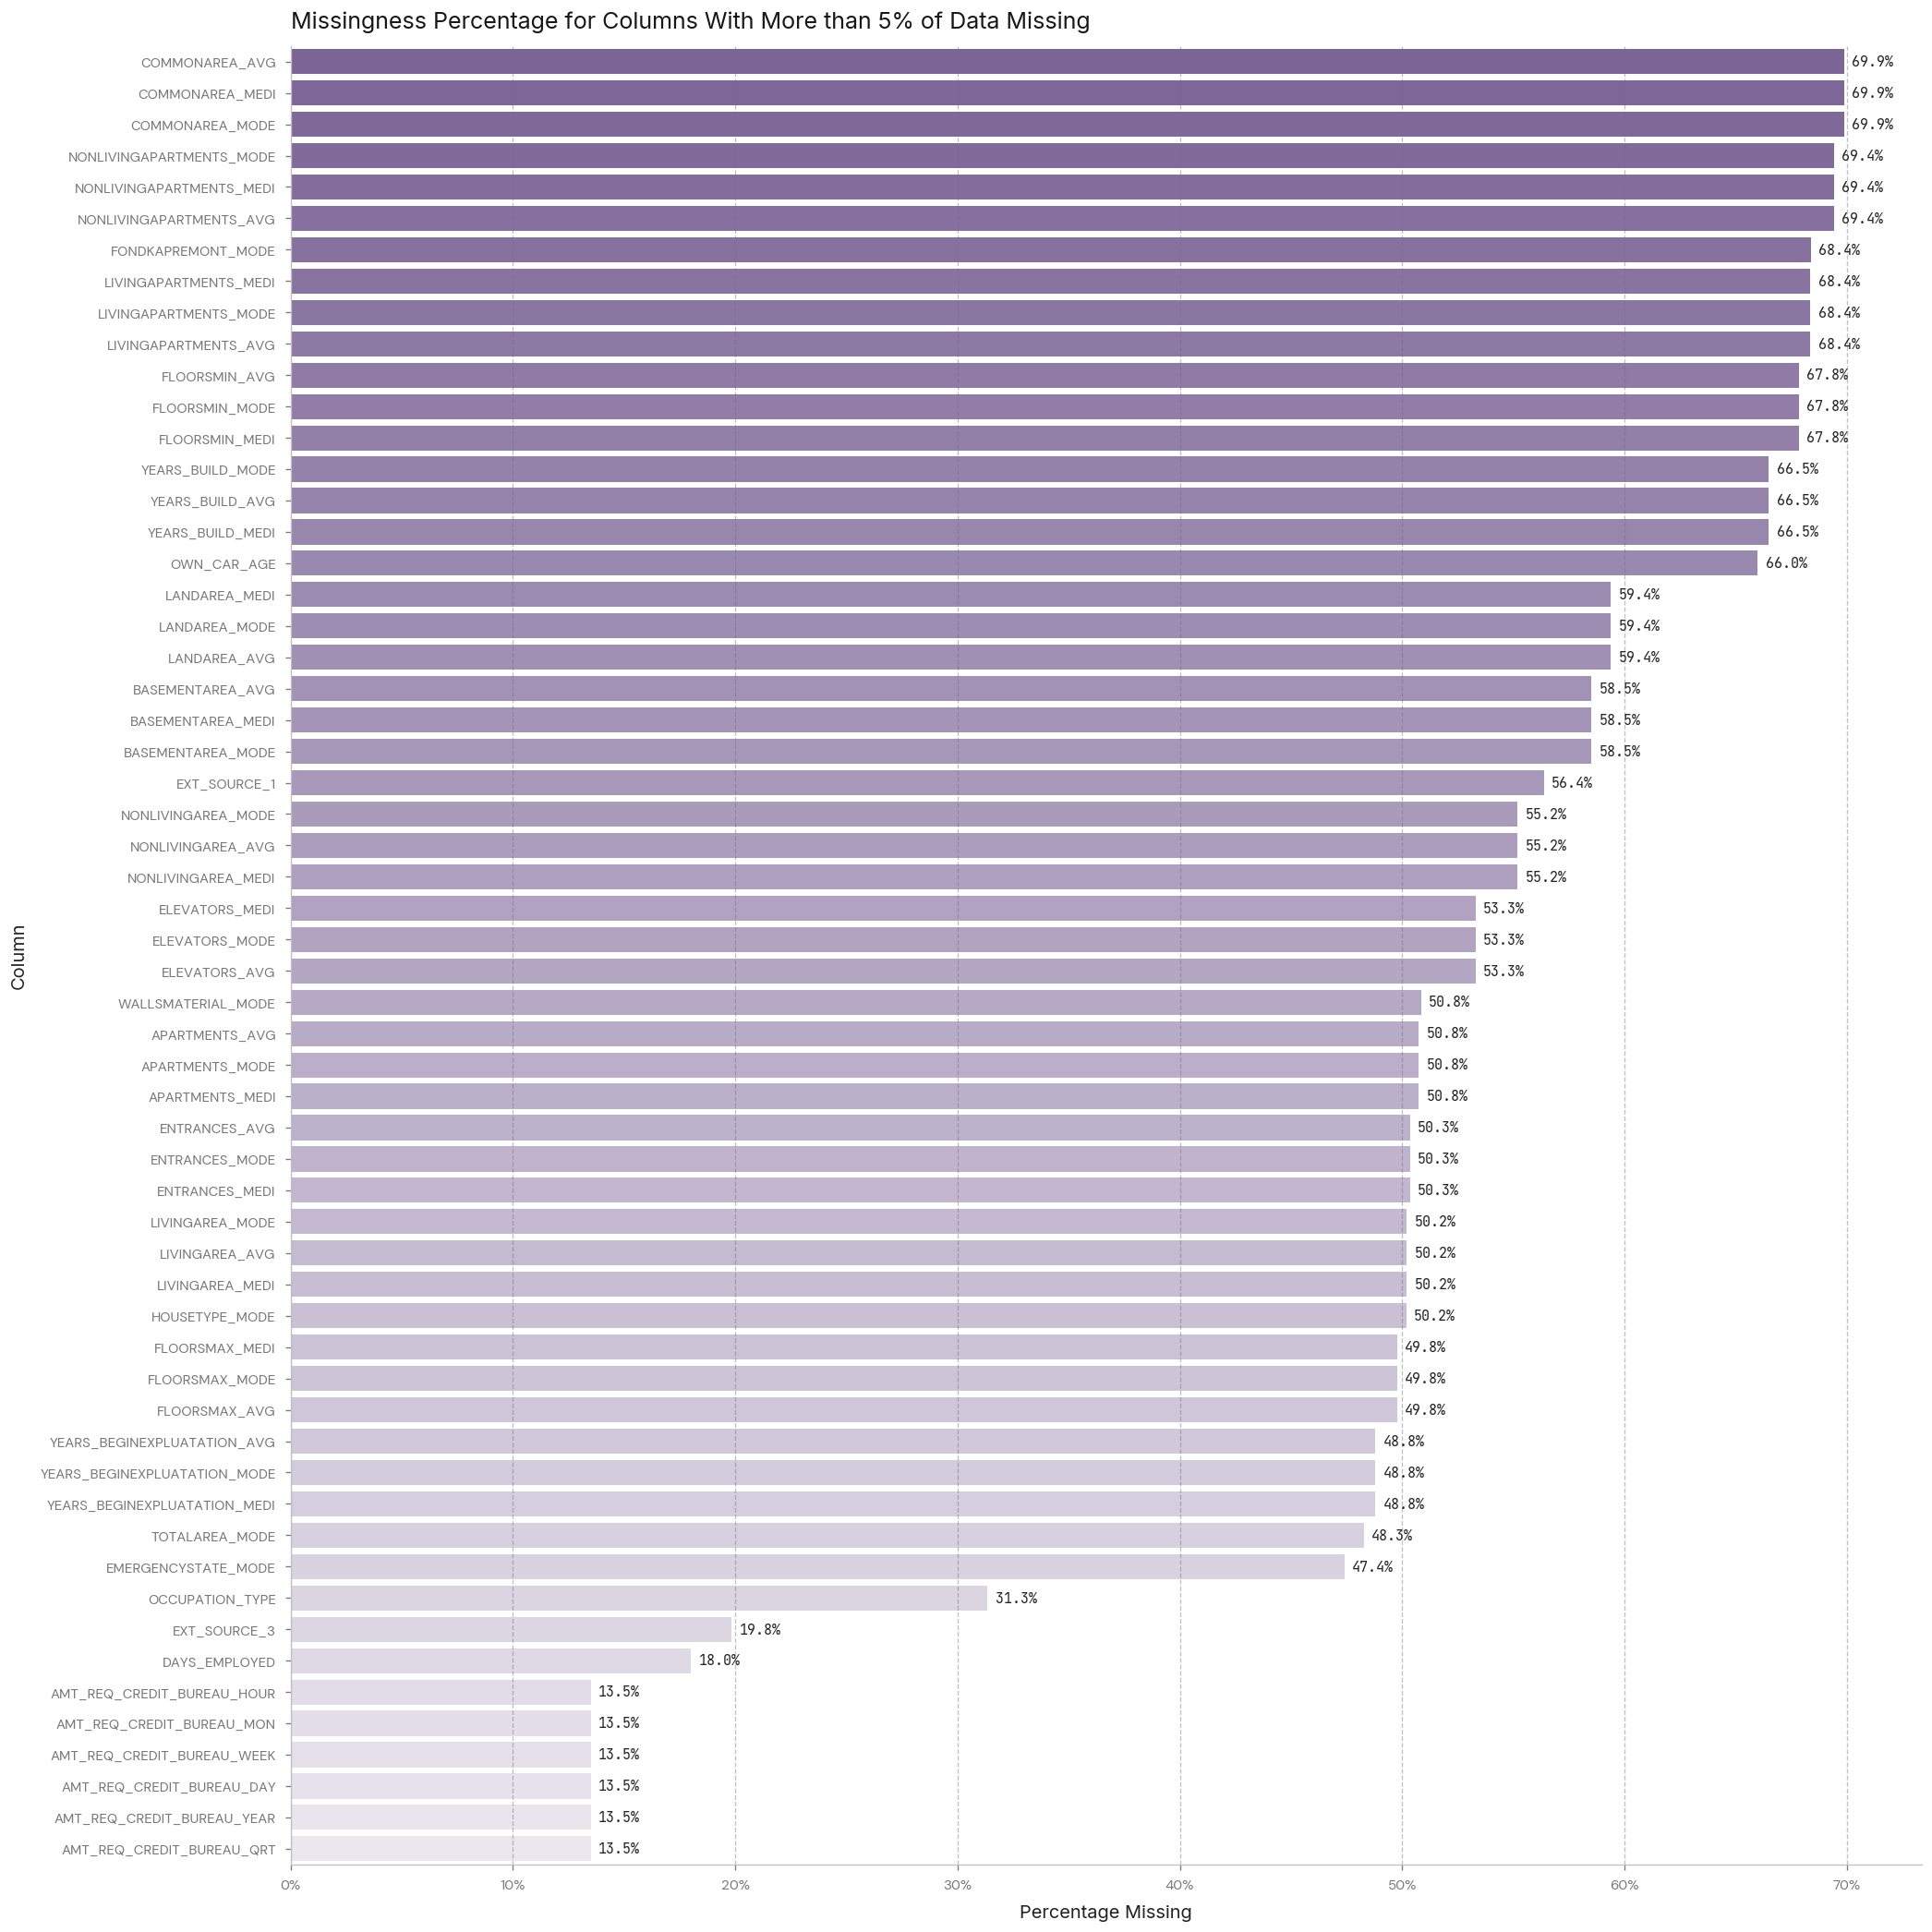

In [16]:
# Missingness by Column (>5% Missing)

missingness_pct = (df.isnull().sum()/len(df)).reset_index()

missingness_pct = missingness_pct.rename(columns={'index': 'column', 0 : 'pct'})

missingness_pct = missingness_pct.sort_values('pct', ascending=False)

missingness_pct = missingness_pct[missingness_pct['pct'] >= 0.05]

# Setting up gradient across bars
n_bars = len(missingness_pct)
alphas = np.linspace(1.0, 0.15, n_bars)

# Set Figure size with y
plt.figure(figsize=(len(missingness_pct)*0.3,len(missingness_pct)*0.3 ))

# Assigning Columns to axes and call SNS
ax = sns.barplot(missingness_pct, x='pct', y='column')

# Assigning gradient to bar chart
for bar, alpha in zip(ax.patches, alphas):
    bar.set_alpha(alpha)

# Setting chart labels and titles
ax.set_title('Missingness Percentage for Columns With More than 5% of Data Missing', fontfamily=f('heading'), fontsize= s('title'))
ax.set_xlabel("Percentage Missing", fontfamily=f('heading'), fontsize=s('subtitle'))
ax.set_ylabel("Column", fontfamily=f('heading'), fontsize=s('subtitle'))

# Formatting X-Axis

ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

# Setting bar labels
ax.bar_label(ax.containers[0], padding= 5, labels=[f'{pct*100:.1f}%' for pct in missingness_pct['pct']], fontsize=s('small'), fontfamily=f('mono'), label_type='edge')

# Rendering chart
plt.show()


**Observation:** All of the columns with >= 50% of data missing belong to the same thematic subset - 'building_stats' - except for 'OWN_CAR_AGE' and 'EXT_SOURCE_1'. 

'OCCUPATION_TYPE', 'DAYS_EMPLOYED' and 'EXT_SOURCE_3' are also noteworthy as they come from categories that would typically be key criteria when assessing an application for a mortgage.

**Decision:** The 'building_stats' subset require a separate assessment of its missingness for a better understanding of its relevance for predicting default. The other two columns with high missingness percentage (>=50%) require a more granular assessment when looking at their correlation with default.

#### Fully Populated Thematic Groups

**Explanation:** There are some subsets that have zero missing values and should be excluded to provide a focused assessment of the missingness of the data set.

In [17]:
# Get groups that dont have any missing data to exclude from missingness assessment

fully_populated_thematic_groups = set()

for key in cols_by_theme:
    
    missing_per_group = df[cols_by_theme[key]].isnull().sum()
    
    
    print(key + '\n')
    print(missing_per_group)
    print('\n')
    
    if (missing_per_group == 0).all():
        fully_populated_thematic_groups.add(key)    

print(fully_populated_thematic_groups)

id_target

SK_ID_CURR    0
TARGET        0
dtype: int64


external_scores

EXT_SOURCE_1    173376
EXT_SOURCE_2       660
EXT_SOURCE_3     60965
dtype: int64


loan_financials

NAME_CONTRACT_TYPE      0
AMT_INCOME_TOTAL        0
AMT_CREDIT              0
AMT_ANNUITY            12
AMT_GOODS_PRICE       278
dtype: int64


demographics

CODE_GENDER               0
DAYS_BIRTH                0
CNT_CHILDREN              0
CNT_FAM_MEMBERS           2
NAME_FAMILY_STATUS        0
NAME_EDUCATION_TYPE       0
NAME_HOUSING_TYPE         0
NAME_TYPE_SUITE        1292
dtype: int64


employment

NAME_INCOME_TYPE         0
OCCUPATION_TYPE      96389
ORGANIZATION_TYPE        0
DAYS_EMPLOYED        55374
dtype: int64


assets

FLAG_OWN_CAR            0
OWN_CAR_AGE        202927
FLAG_OWN_REALTY         0
dtype: int64


contact

FLAG_MOBIL          0
FLAG_EMP_PHONE      0
FLAG_WORK_PHONE     0
FLAG_CONT_MOBILE    0
FLAG_PHONE          0
FLAG_EMAIL          0
dtype: int64


client_timeline

DAYS_REGISTRATION

**Observation:** The following thematic subsets - 'region', 'id_target', 'document_flags', 'application_timing' and 'contact' - all have zero missing values.

**Decision:** These subsets can be excluded from the missingness assessment that follows for a cleaner view of the data's missingness.

#### Missingness by Thematic Group

##### Missingness Bar Charts

Assessing missingness per thematic subset that have been shown to have missing data - excluding 'building_stats', as noted previously.

**Explanation:** The thematic subset assessment will show there is block-wise missingness within these subsets.

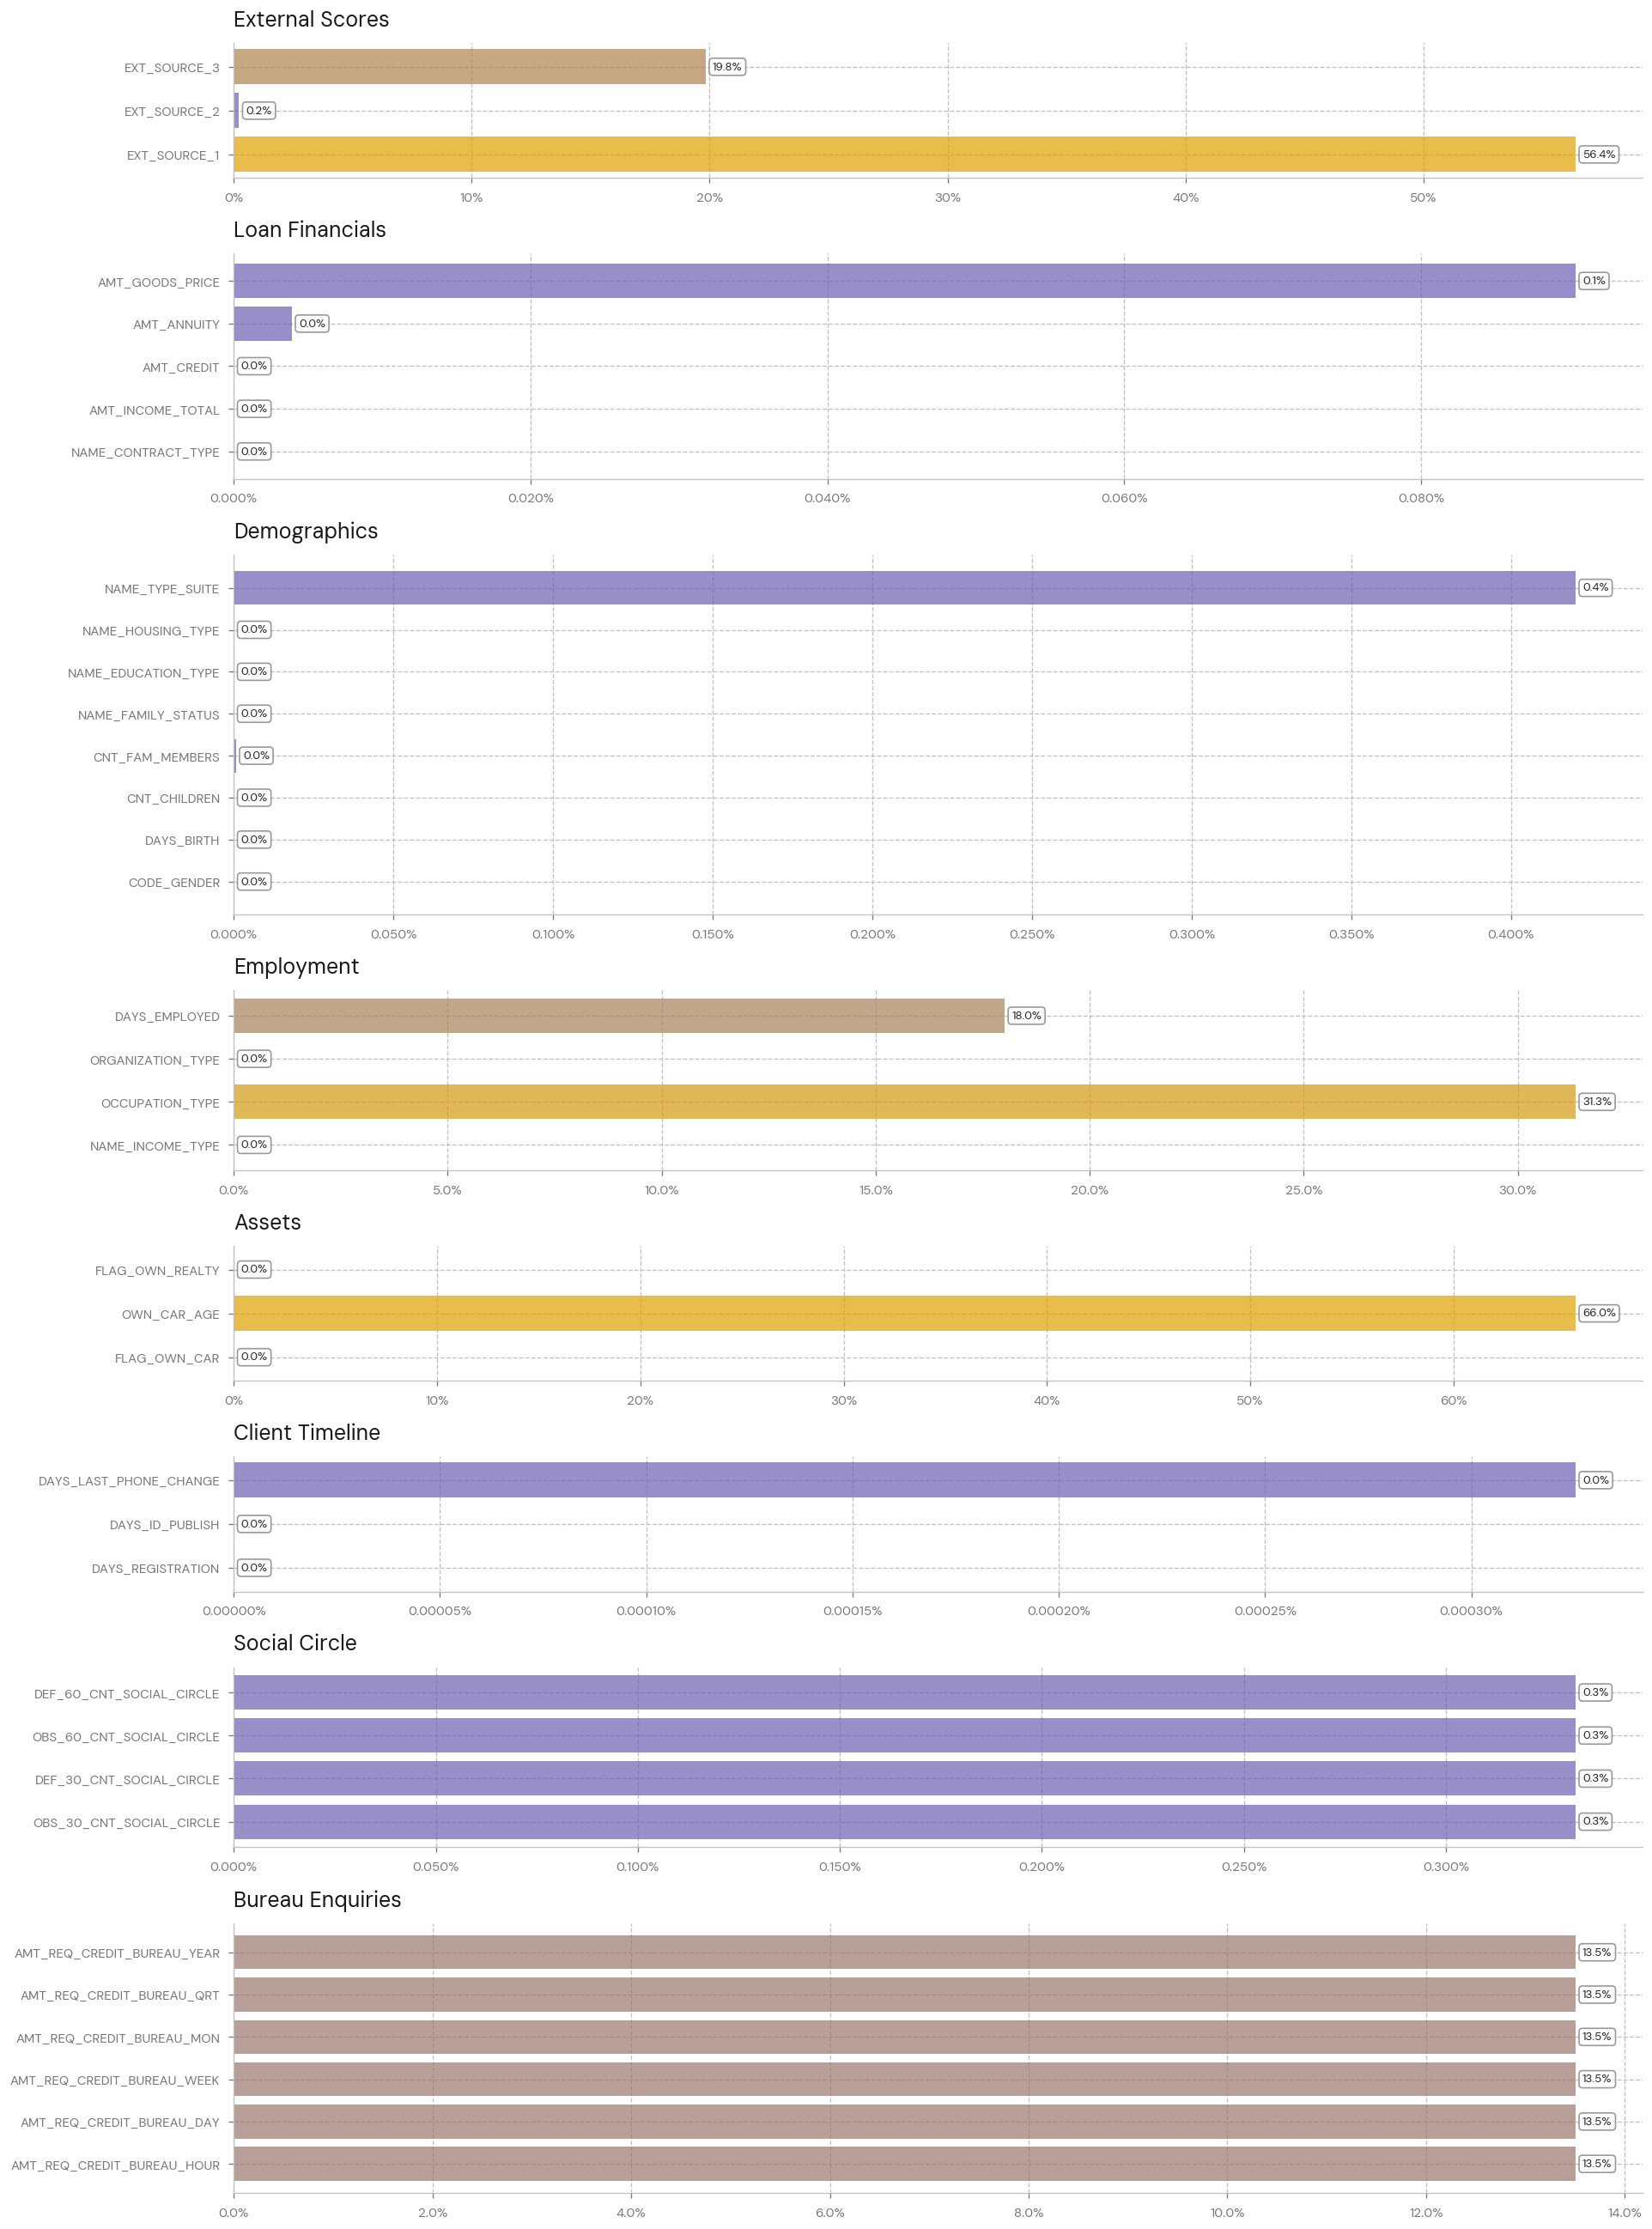

In [18]:

# Exclusion of groups with no missing values + building_stats due to size of group

exclude_thematic_groups = fully_populated_thematic_groups | {'building_stats'}

groups_to_plot = [k for k in cols_by_theme if k not in exclude_thematic_groups] 
num_figs = len(groups_to_plot)

# Setting figure count + render dimensions

bar_counts = [len(cols_by_theme[k]) for k in groups_to_plot]

n_cols = 1
n_rows = math.ceil(num_figs / n_cols)

# Setting color scheme for bar charts

cmap = risk_cmap()

# Setting up chart variables

n = len(df)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 0.6 * sum(bar_counts)), gridspec_kw={'height_ratios': bar_counts})
axes = axes.flatten()

# Loop to iterate through column groups for missingness percentages

for i, key in enumerate(groups_to_plot):
    
    # To drop zero values
    
    # frac = df[cols_by_theme[key]].isnull().sum() / n 
    # missing = frac[frac != 0]# missing per column
    
    # Keep zero values
    
    missing = df[cols_by_theme[key]].isnull().sum() / n 

    norm = colors.Normalize(vmin=0, vmax=0.35)

    bars = axes[i].barh(missing.index, missing.values,
                 color=cmap(norm(missing.values)),
                 alpha = 0.7)
    axes[i].set_title(key.replace('_', ' ').title())
    axes[i].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    axes[i].bar_label(bars, labels=[f"{w:.1%}" for w in missing.values],
                  padding=5, fontsize=8,
                  bbox=dict(boxstyle='round', facecolor='white',
                            edgecolor='grey', alpha=0.8))
    
plt.show()


**Observation:** The "social_circle" and "bureau_enquiries" subsets show block-wise missingness.

**Decision:** These thematic subsets will also be assessed further.

##### Building Stats Missingness

Checks whether the AVG, MEDI and MODE versions of each building measure are missing on the same rows: first by comparing missing counts side by side, then with a nullity correlation heatmap (1 = always missing together).

In [19]:
# Missing counts by measure and suffix

cols = cols_by_theme['building_stats']
miss = df[cols].isnull().sum()

# Split names into base + suffix
tbl = miss.rename_axis('col').reset_index(name='n_missing')
tbl['suffix'] = tbl['col'].str.rsplit('_', n=1).str[1]
tbl['base']   = tbl['col'].str.rsplit('_', n=1).str[0]

pivot = tbl.pivot(index='base', columns='suffix', values='n_missing')
print(pivot)


suffix                   AVG       MEDI      MODE    
base                                                 
APARTMENTS              156060.00 156060.00 156060.00
BASEMENTAREA            179942.00 179942.00 179942.00
COMMONAREA              214862.00 214862.00 214862.00
ELEVATORS               163890.00 163890.00 163890.00
EMERGENCYSTATE                NaN       NaN 145754.00
ENTRANCES               154827.00 154827.00 154827.00
FLOORSMAX               153019.00 153019.00 153019.00
FLOORSMIN               208640.00 208640.00 208640.00
FONDKAPREMONT                 NaN       NaN 210293.00
HOUSETYPE                     NaN       NaN 154296.00
LANDAREA                182588.00 182588.00 182588.00
LIVINGAPARTMENTS        210197.00 210197.00 210197.00
LIVINGAREA              154349.00 154349.00 154349.00
NONLIVINGAPARTMENTS     213512.00 213512.00 213512.00
NONLIVINGAREA           169680.00 169680.00 169680.00
TOTALAREA                     NaN       NaN 148430.00
WALLSMATERIAL               

0.6233260177847602


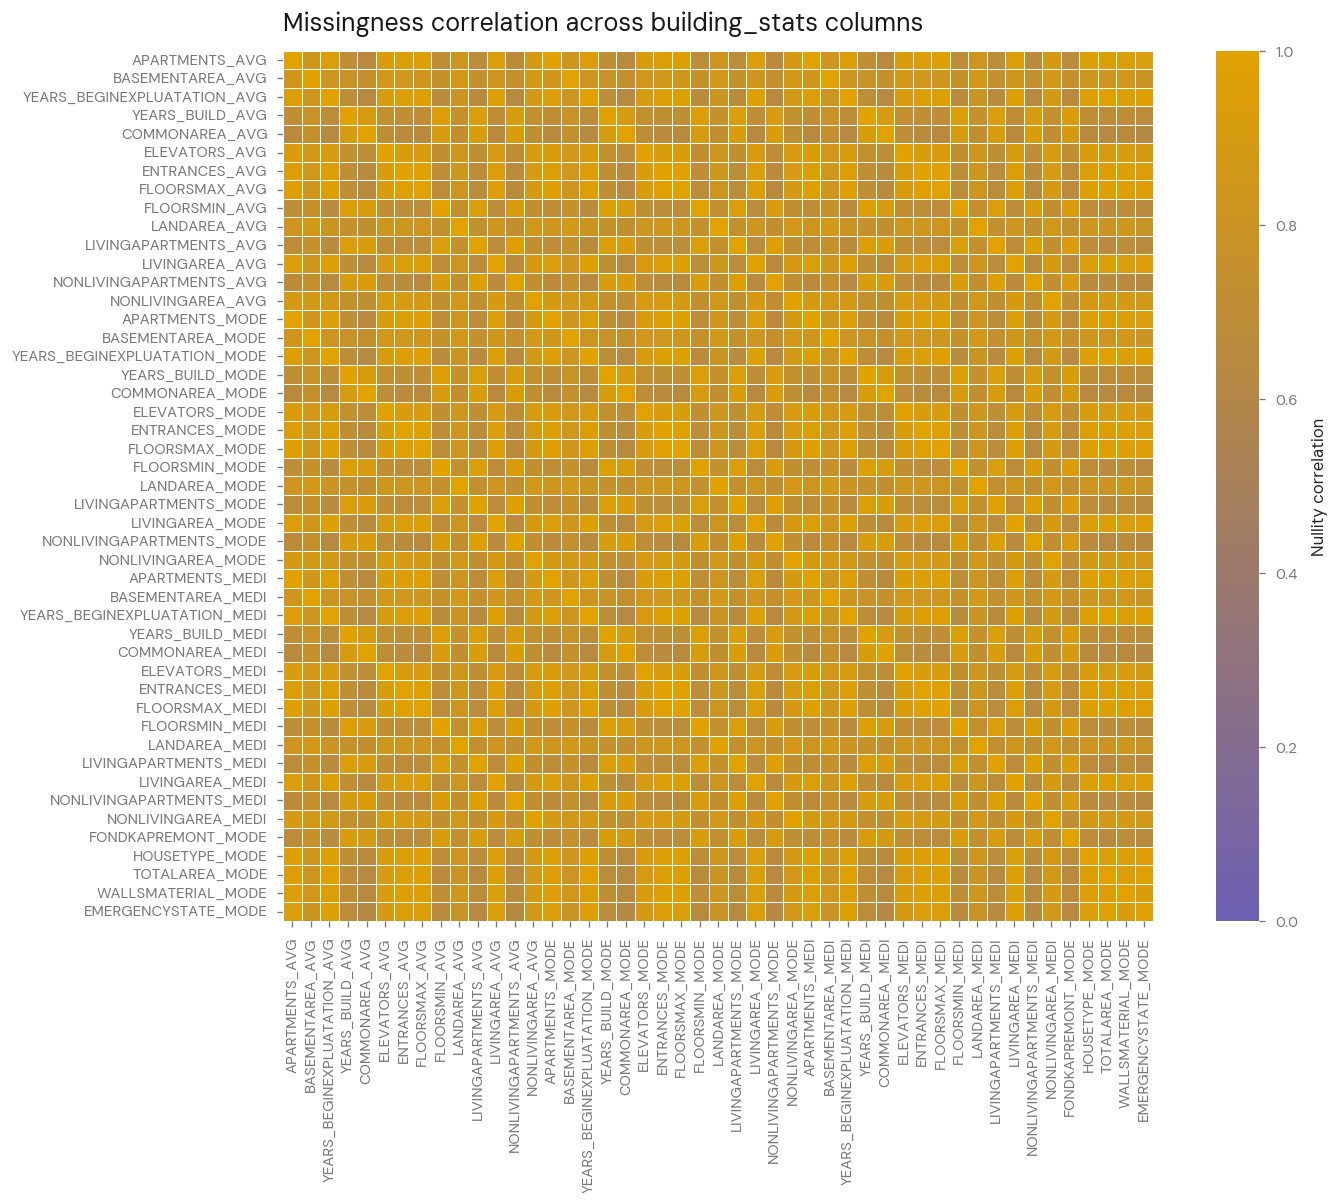

In [20]:
# Nullity correlation
corr = df[cols].isnull().corr()

off_diag = corr.where(~np.eye(len(corr), dtype=bool))
print(off_diag.min().min())

# Visualisation to confirm

plt.figure(figsize=(12, 10))
sns.heatmap(corr,
            cmap=risk_cmap(),
            vmin=0, vmax=1,      # lock scale so 1.0 = full color
            square=True,
            linewidths=0.5,
            cbar_kws={'label': 'Nullity correlation'})
plt.title('Missingness correlation across building_stats columns')
plt.show()

**Observation**: Missingness across the average, median and mode for the building_stats thematic subgroup are equivalent. Nullity correlation is 1 within each AVG / MEDI / MODE triplet (identical rows missing), so each triplet can safely collapse to its AVG version. The lowest correlation between different measures is ~0.62.

                              APARTMENTS_AVG  BASEMENTAREA_AVG  \
APARTMENTS_AVG               1.00            0.84                
BASEMENTAREA_AVG             0.84            1.00                
YEARS_BEGINEXPLUATATION_AVG  0.95            0.82                
YEARS_BUILD_AVG              0.71            0.78                
COMMONAREA_AVG               0.66            0.75                
ELEVATORS_AVG                0.92            0.85                
ENTRANCES_AVG                0.96            0.84                
FLOORSMAX_AVG                0.97            0.84                
FLOORSMIN_AVG                0.69            0.76                
LANDAREA_AVG                 0.82            0.86                
LIVINGAPARTMENTS_AVG         0.68            0.76                
LIVINGAREA_AVG               0.93            0.83                
NONLIVINGAPARTMENTS_AVG      0.67            0.75                
NONLIVINGAREA_AVG            0.89            0.87                
APARTMENTS

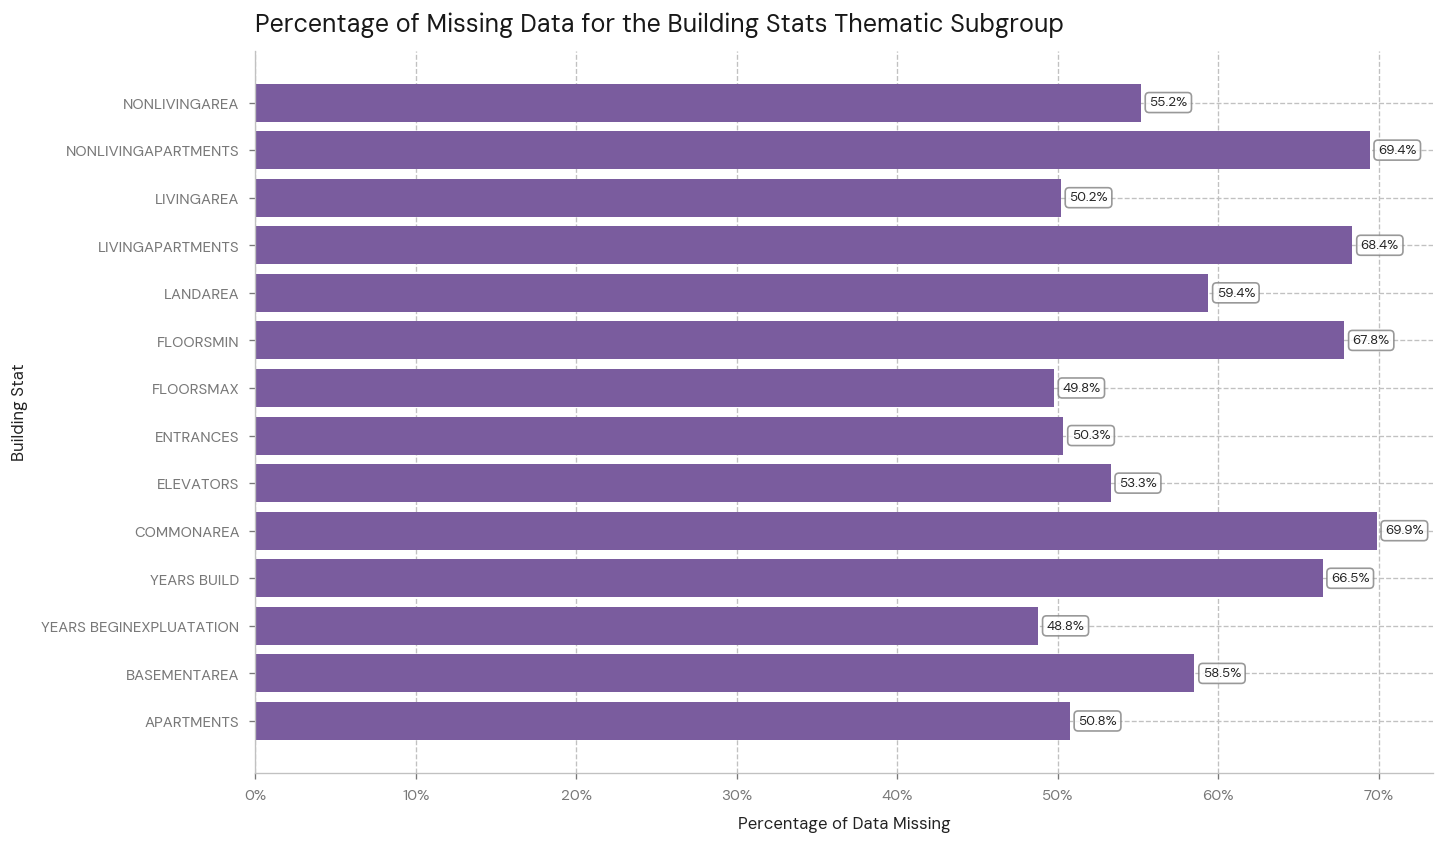

In [21]:
# Excluding median and mode columns and only using average as the missingness is shared between them 

avg_cols = [c for c in cols_by_theme['building_stats'] if 'AVG' in c]

missingness_avg_build = df[avg_cols].isnull().sum()

missingness_avg_build_cols_percentage = missingness_avg_build / n

labels = [c.replace('_AVG', '').replace('_',' ') for c in missingness_avg_build_cols_percentage.index]

print(corr)

print(missingness_avg_build_cols_percentage)

fig, ax = plt.subplots(figsize = (12, 0.5 * len(missingness_avg_build_cols_percentage)))

bars_2 = ax.barh(labels, missingness_avg_build_cols_percentage.values)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title('Percentage of Missing Data for the Building Stats Thematic Subgroup')
ax.set_ylabel('Building Stat')
ax.set_xlabel('Percentage of Data Missing')
ax.bar_label(bars_2, labels=[f'{w:.1%}' for w in missingness_avg_build_cols_percentage.values],
            padding=5, fontsize=8,
            bbox=dict(boxstyle='round', facecolor='white',
                            edgecolor='grey', alpha=0.8))
plt.show()


**Decision:** Leave this subset as is for now. Upon completing univariate analysis for this subset and before feature selection it can be determined whether the 15 triplet columns (AVG, MED, MODE) are collapsed into one with a 'building_missing_info' sentinel column.  

##### Car Data Missingness

Tests whether `OWN_CAR_AGE` is missing simply because the applicant doesn't own a car: the share of missing car ages where `FLAG_OWN_CAR` = N.

In [22]:
# Check whether missingness of Car Ages for each borrower corresponds with them owning a car or not

car_age_missing = df['OWN_CAR_AGE'].isnull()

(df.loc[car_age_missing, 'FLAG_OWN_CAR'] =='N').mean().round(4)

np.float64(1.0)

**Observation/Decision:** almost a complete match of the missingness for 'OWN_CAR_AGE' to borrowers that do not own a car. Therefore this is MAR missingness and requires no action at this stage.

##### Bureau Enquiries Missingness

Same check as building stats: missing counts per enquiry window, then nullity correlation to confirm the six columns are missing on the same rows.

In [23]:
# Missingness check across bureau enquiries subset

cols_be = cols_by_theme['bureau_enquiries']
miss = df[cols_be].isnull().sum()

# Split names into base + suffix
tbl = miss.rename_axis('col').reset_index(name='n_missing')
tbl['suffix'] = tbl['col'].str.rsplit('_', n=1).str[1]
tbl['base']   = tbl['col'].str.rsplit('_', n=1).str[0]

pivot = tbl.pivot(index='base', columns='suffix', values='n_missing')
print(pivot)


suffix                 DAY    HOUR   MON    QRT    WEEK   YEAR 
base                                                           
AMT_REQ_CREDIT_BUREAU  41519  41519  41519  41519  41519  41519


1.0


(array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5]),
 [Text(0.5, 0, 'AMT_REQ_CREDIT_BUREAU_HOUR'),
  Text(1.5, 0, 'AMT_REQ_CREDIT_BUREAU_DAY'),
  Text(2.5, 0, 'AMT_REQ_CREDIT_BUREAU_WEEK'),
  Text(3.5, 0, 'AMT_REQ_CREDIT_BUREAU_MON'),
  Text(4.5, 0, 'AMT_REQ_CREDIT_BUREAU_QRT'),
  Text(5.5, 0, 'AMT_REQ_CREDIT_BUREAU_YEAR')])

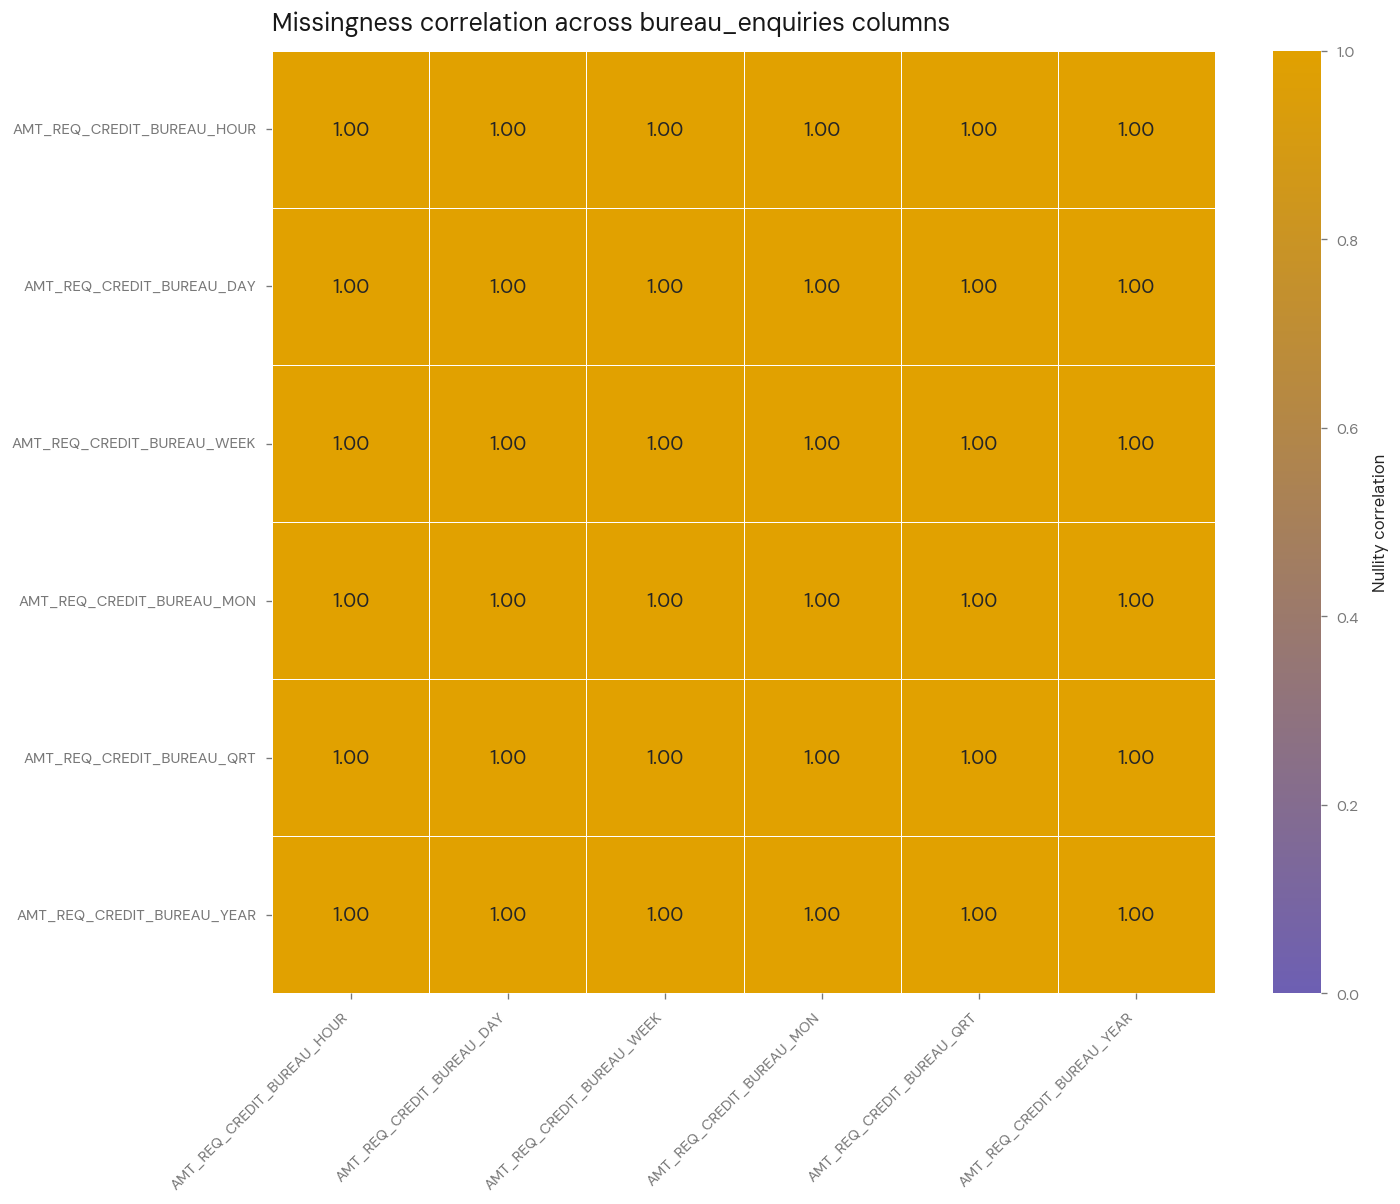

In [24]:
# Nullity correlation
corr = df[cols_be].isnull().corr()

off_diag = corr.where(~np.eye(len(corr), dtype=bool))
print(off_diag.min().min())

# Visualisation to confirm

plt.figure(figsize=(12, 10))
sns.heatmap(corr,
            cmap=risk_cmap(),
            vmin=0, vmax=1,
            square=True,
            linewidths=0.5,
            annot=True,          # write the value in each square
            fmt='.2f',           # 2 decimal places
            annot_kws={'size': 12},
            cbar_kws={'label': 'Nullity correlation'})
plt.title('Missingness correlation across bureau_enquiries columns')

plt.xticks(rotation=45, ha='right')

plt.show()


##### Social Circles Missingness

Same check for the four social circle columns, followed by a crosstab to see whether the bureau and social circle missing blocks overlap.

In [25]:
# Missingness check across social circles subset

cols_sc = cols_by_theme['social_circle']
miss = df[cols_sc].isnull().sum()

# Split names into base + suffix
tbl = miss.rename_axis('col').reset_index(name='n_missing')
tbl['suffix'] = tbl['col'].str.rsplit('_', n=1).str[1]
tbl['base']   = tbl['col'].str.rsplit('_', n=1).str[0]

pivot = tbl.pivot(index='base', columns='suffix', values='n_missing')
print(pivot)


suffix             CIRCLE
base                     
DEF_30_CNT_SOCIAL  1021  
DEF_60_CNT_SOCIAL  1021  
OBS_30_CNT_SOCIAL  1021  
OBS_60_CNT_SOCIAL  1021  


1.0


(array([0.5, 1.5, 2.5, 3.5]),
 [Text(0, 0.5, 'OBS_30_CNT_SOCIAL_CIRCLE'),
  Text(0, 1.5, 'DEF_30_CNT_SOCIAL_CIRCLE'),
  Text(0, 2.5, 'OBS_60_CNT_SOCIAL_CIRCLE'),
  Text(0, 3.5, 'DEF_60_CNT_SOCIAL_CIRCLE')])

(array([0.5, 1.5, 2.5, 3.5]),
 [Text(0.5, 0, 'OBS_30_CNT_SOCIAL_CIRCLE'),
  Text(1.5, 0, 'DEF_30_CNT_SOCIAL_CIRCLE'),
  Text(2.5, 0, 'OBS_60_CNT_SOCIAL_CIRCLE'),
  Text(3.5, 0, 'DEF_60_CNT_SOCIAL_CIRCLE')])

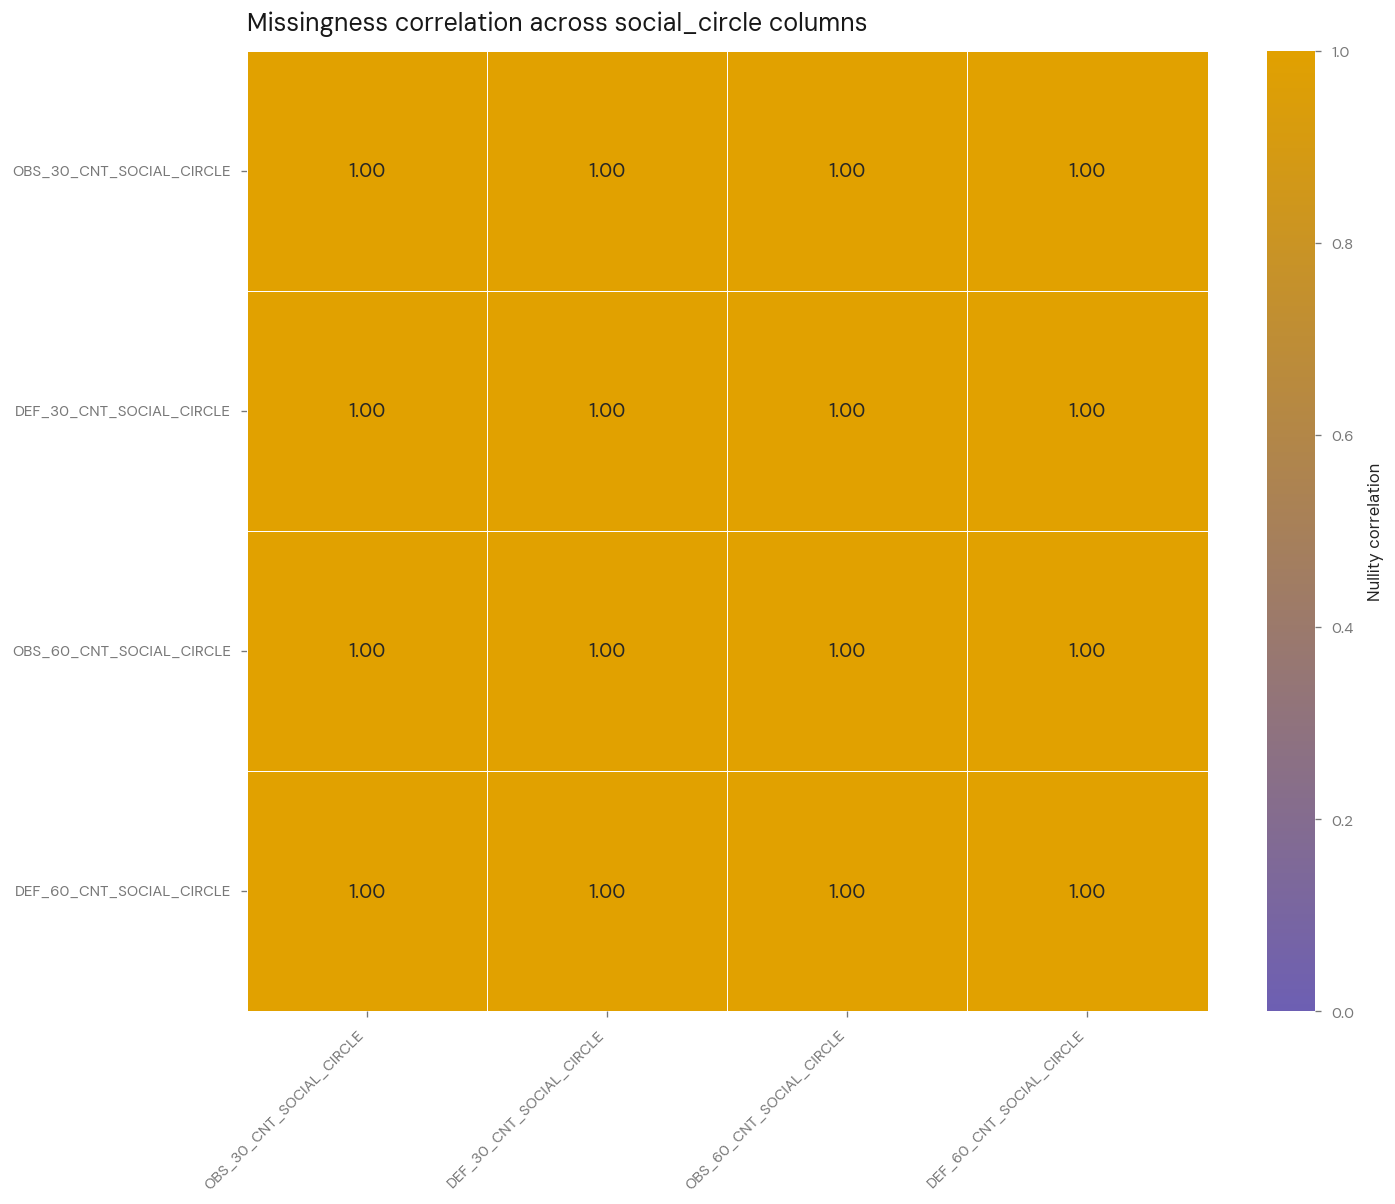

In [26]:
# Nullity correlation
corr = df[cols_sc].isnull().corr()

off_diag = corr.where(~np.eye(len(corr), dtype=bool))
print(off_diag.min().min())

# Visualisation to confirm

plt.figure(figsize=(12, 10))
sns.heatmap(corr,
            cmap=risk_cmap(),
            vmin=0, vmax=1,
            square=True,
            linewidths=0.5,
            annot=True,          # write the value in each square
            fmt='.2f',           # 2 decimal places
            annot_kws={'size': 12},
            cbar_kws={'label': 'Nullity correlation'})
plt.title('Missingness correlation across social_circle columns')

plt.yticks(rotation=0, ha='right')
plt.xticks(rotation=45, ha='right')

plt.show()

In [27]:
# Overlap between the bureau and social circle missing blocks

bureau_missing = df[cols_by_theme['bureau_enquiries'][0]].isnull()
social_missing = df[cols_by_theme['social_circle'][0]].isnull()

pd.crosstab(bureau_missing, social_missing)

OBS_30_CNT_SOCIAL_CIRCLE,False,True
AMT_REQ_CREDIT_BUREAU_HOUR,,
False,265137,851
True,41349,170


**Observation/Decision:** Both subsets show block-wise missingness, and the crosstab confirms they are independent of each other (minimal row overlap) - so they have separate origins. Mechanism (informative vs not) to be tested against TARGET in Section 5.

### 2.4 Cardinality Assessment

Cardinality Assessment of Categorical Ordinal Columns. The columns 'HOUR_APPR_PROCESS_START', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY' are being dropped from this assessment as they are defined by internal ratings and the hours of the day. There are no benefits to assessing these columns in this context as no actions will be taken to; merge sparse columns, establish supervised grouping or domain grouping.

**Explanation:** A few categorical features (notably occupation and organization type) are expected to have high cardinality with many sparse levels. Sparse levels produce unstable WOE (too few bads per bin), so they'll need pooling (rare levels merged) or supervised grouping by default rate before IV/WOE binning; low-cardinality categoricals should need no treatment.

['NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE']


14

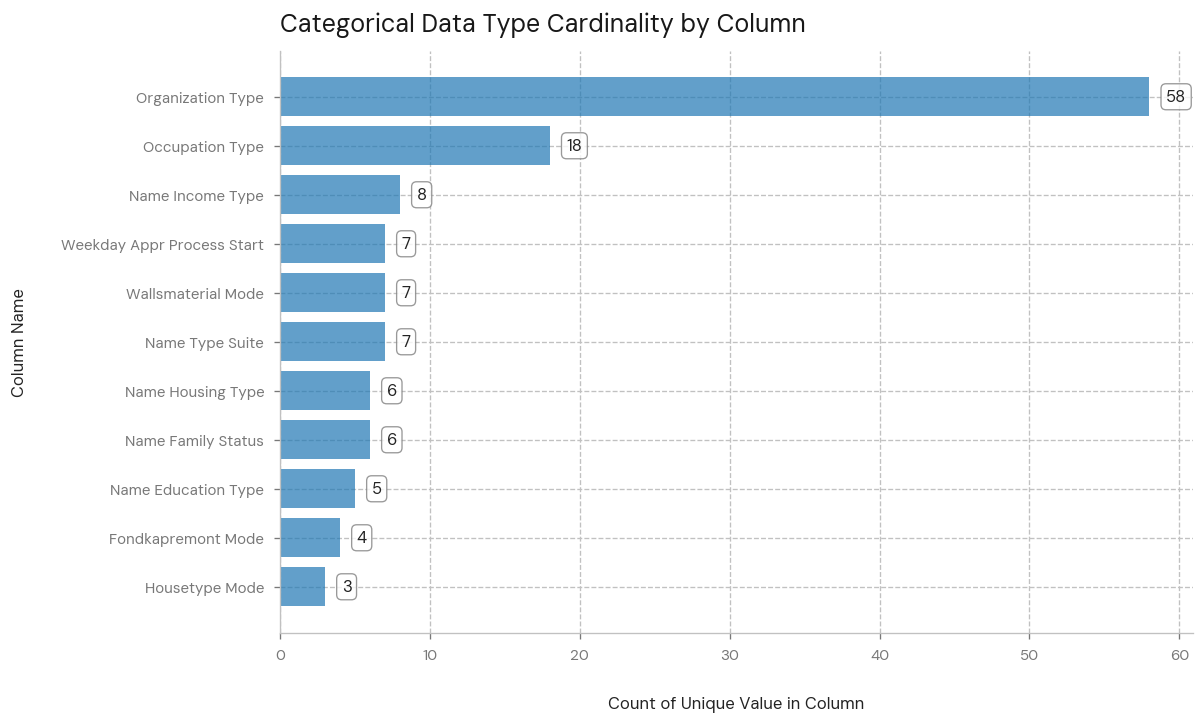

In [28]:
# Categorical Cardinality by Column

print(cols_by_type['categorical'])
    
cols = cols_by_type['categorical'] + cols_by_type['ordinal']

len(cols)

cardinality = df[cols].nunique().sort_values(ascending=True)

cardinality = cardinality.drop(['HOUR_APPR_PROCESS_START', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY'])

labels = cardinality.index.str.replace('_', ' ').str.title()


fig, ax = plt.subplots(figsize=(10,6))

bars = ax.barh(labels, cardinality.values,
        color="tab:blue",
        alpha=0.7)

ax.set_xlabel('Count of Unique Value in Column', labelpad=20)
ax.set_ylabel('Column Name', labelpad=20)
ax.set_title('Categorical Data Type Cardinality by Column')

ax.bar_label(bars,
             padding=10,
             bbox=dict(
                 boxstyle='round',
                 facecolor='white',
                 edgecolor='grey',
                 alpha = 0.8,
                 linewidth=0.8
             ))
plt.show()


**Observation/Decision**: The two highest cardinality columns 'OCCUPATION_TYPE' and 'ORGANIZATION_TYPE' exceed more than 10 unique entries and must have a specified treatment plan for IV/WOE binning and the following ranking of feature importance.

In [29]:
# Assess columns with < 5% of the data for merging into an other column

bins = df['OCCUPATION_TYPE'].value_counts(normalize=True, ascending=True, dropna=False)

print((bins.values < 0.05).sum())

13


In [30]:
# Assess columns with < 5% of the data for merging into an other column

bins = df['ORGANIZATION_TYPE'].value_counts(normalize=True, ascending=True, dropna=False)

print((bins.values < 0.05).sum())

# Many levels contain < 5% of the data - will look at default rate per level instead

defaulters = df['ORGANIZATION_TYPE'][df['TARGET'] == 1]

organization_type_counts = df['ORGANIZATION_TYPE'].value_counts(dropna=False)

defaulters = defaulters.value_counts(dropna=False) / organization_type_counts

defaulters.sort_values(ascending=False).map('{:.2%}'.format)

# Sanity Check

# len(df[df['ORGANIZATION_TYPE'] == 'Transport: type 3'] )

# len(df[(df['ORGANIZATION_TYPE'] == 'Transport: type 3') & (df['TARGET'] == 1)]  )

# 187 / 1187

54


ORGANIZATION_TYPE
Transport: type 3         15.75%
Industry: type 13         13.43%
Industry: type 8          12.50%
Restaurant                11.71%
Construction              11.68%
Cleaning                  11.15%
Industry: type 1          11.07%
Industry: type 3          10.62%
Realtor                   10.61%
Agriculture               10.47%
Trade: type 3             10.34%
Self-employed             10.17%
Industry: type 4          10.15%
Security                   9.98%
Trade: type 7              9.45%
Business Entity Type 3     9.30%
Transport: type 4          9.28%
Mobile                     9.15%
Trade: type 1              8.91%
Industry: type 11          8.65%
Business Entity Type 2     8.53%
Postal                     8.44%
Advertising                8.16%
Business Entity Type 1     8.14%
Industry: type 7           8.03%
Housing                    7.94%
Legal Services             7.87%
Transport: type 2          7.80%
Other                      7.64%
Telecom                  

**Observation:** Both are high-cardinality categoricals whose sparse levels would produce unstable WOE. ORGANIZATION_TYPE (~58 levels) will be grouped by similar default rate (see band mapping below); OCCUPATION_TYPE (~18 levels) will have levels below 5% pooled, with NaN kept as its own category.

**Note (leakage):** The ORG_BAND mapping below is defined using TARGET (default rate) on the full dataset, so its IV here would be optimistic. This supervised binning will be refit on the TRAIN split only in Section 5.1, alongside the other WOE binning decisions.

#### Band Mapping for 'ORGANIZATION TYPE'

Preview of the grouping: organisation types are banded by default rate (<6%, 6-8%, 8-10%, >10%), and large high-risk types (over 10% default and at least 500 applicants) keep their own level. Computed on the full data for viewing only; the modelling version is fit on the train split in 5.1.

In [31]:
# EDA preview only - the ORG_BAND feature is fit on train in 5.1

rate = df.groupby('ORGANIZATION_TYPE')['TARGET'].mean()
counts = df['ORGANIZATION_TYPE'].value_counts()

band = pd.cut(rate, bins=[0, 0.06, 0.08, 0.10, 1.0],
              labels=['<6%', '6-8%', '8-10%', '>10%']).astype('object')
# Large high-rate levels stay on their own
hi = (rate > 0.10) & (counts >= 500)
band[hi] = rate.index[hi]

preview = (pd.DataFrame({'default_rate': rate, 'n': counts, 'band': band})
             .sort_values('default_rate', ascending=False))
print(f"Organisation types: {rate.size}  ->  bands: {band.nunique()}  (EDA preview only)")
preview

Organisation types: 58  ->  bands: 13  (EDA preview only)


,default_rate,n,band
ORGANIZATION_TYPE,,,
Transport: type 3,0.16,1187,Transport: type 3
Industry: type 13,0.13,67,>10%
Industry: type 8,0.12,24,>10%
Restaurant,0.12,1811,Restaurant
Construction,0.12,6721,Construction
Cleaning,0.11,260,>10%
Industry: type 1,0.11,1039,Industry: type 1
Industry: type 3,0.11,3277,Industry: type 3
Realtor,0.11,396,>10%


**Observation:** We now have only bins for computing IV/WOE. Low default count over 10% default have been grouped into the  >10% bin.

## 3. Feature Analysis

**Purpose.** Work through each feature family in two steps: its distribution (**Univariate**), then how it moves with default (**Bivariate**). The aim is for the Section 5 binning decisions to be informed rather than arbitrary. Along the way, flag skew, outliers, sparse categories and missing values, and close each family with a Decision on the transform or binning to use.

**Approach.** Work by theme using the `cols_by_theme` groups from Section 2, highest-value families first. Keep the **Predict, Task, Decision** rhythm, with each Decision pointing forward to Section 5.

**Planned order:**

| # | Family | Columns | What to look for |
|---|---|---|---|
| 3.1 | External scores | `EXT_SOURCE_1/2/3` | Strongest expected drivers. Shape and missing values (EXT_SOURCE_1 ~56% missing). Quantile bins, with missing as its own bin? |
| 3.2 | Loan financials | `AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE` | Heavy right skew and outliers. Log transform or quantile bins? |
| 3.3 | Age & employment | `DAYS_BIRTH`, `DAYS_EMPLOYED` | Convert to positive years (`/-365`). DAYS_EMPLOYED carries the sentinel NaN, so bins plus a missing flag |
| 3.4 | Key categoricals | education, family status, income type, contract type | Frequency and default rate per level. Note sparse levels (links back to 2.4) |
| 3.5 | Other numeric families | `client_timeline`, `social_circle`, `bureau_enquiries` | Lighter touch. Confirm shape and flag anything odd |

**Scope.** Distributions, target relationships and binning intent only. The cross-feature IV ranking and the WOE encoding happen in Section 5.

### 3.1 External Scores

**Explanation.** The external credit scores (`EXT_SOURCE_1/2/3`) should be the strongest drivers. They are third-party risk scores on a 0-1 scale. This section looks at their distribution and coverage (EXT_SOURCE_1 is ~56% missing) to decide how to bin them and how to treat missing values.

#### Univariate Analysis

Histograms of each score on the 0-1 scale, then the share of missing values per score.

In [32]:
cols_by_theme.keys()

dict_keys(['id_target', 'external_scores', 'loan_financials', 'demographics', 'employment', 'assets', 'contact', 'client_timeline', 'application_timing', 'region', 'building_stats', 'social_circle', 'document_flags', 'bureau_enquiries'])

(0.0, 1.0)

(0.0, 1.0)

(0.0, 1.0)

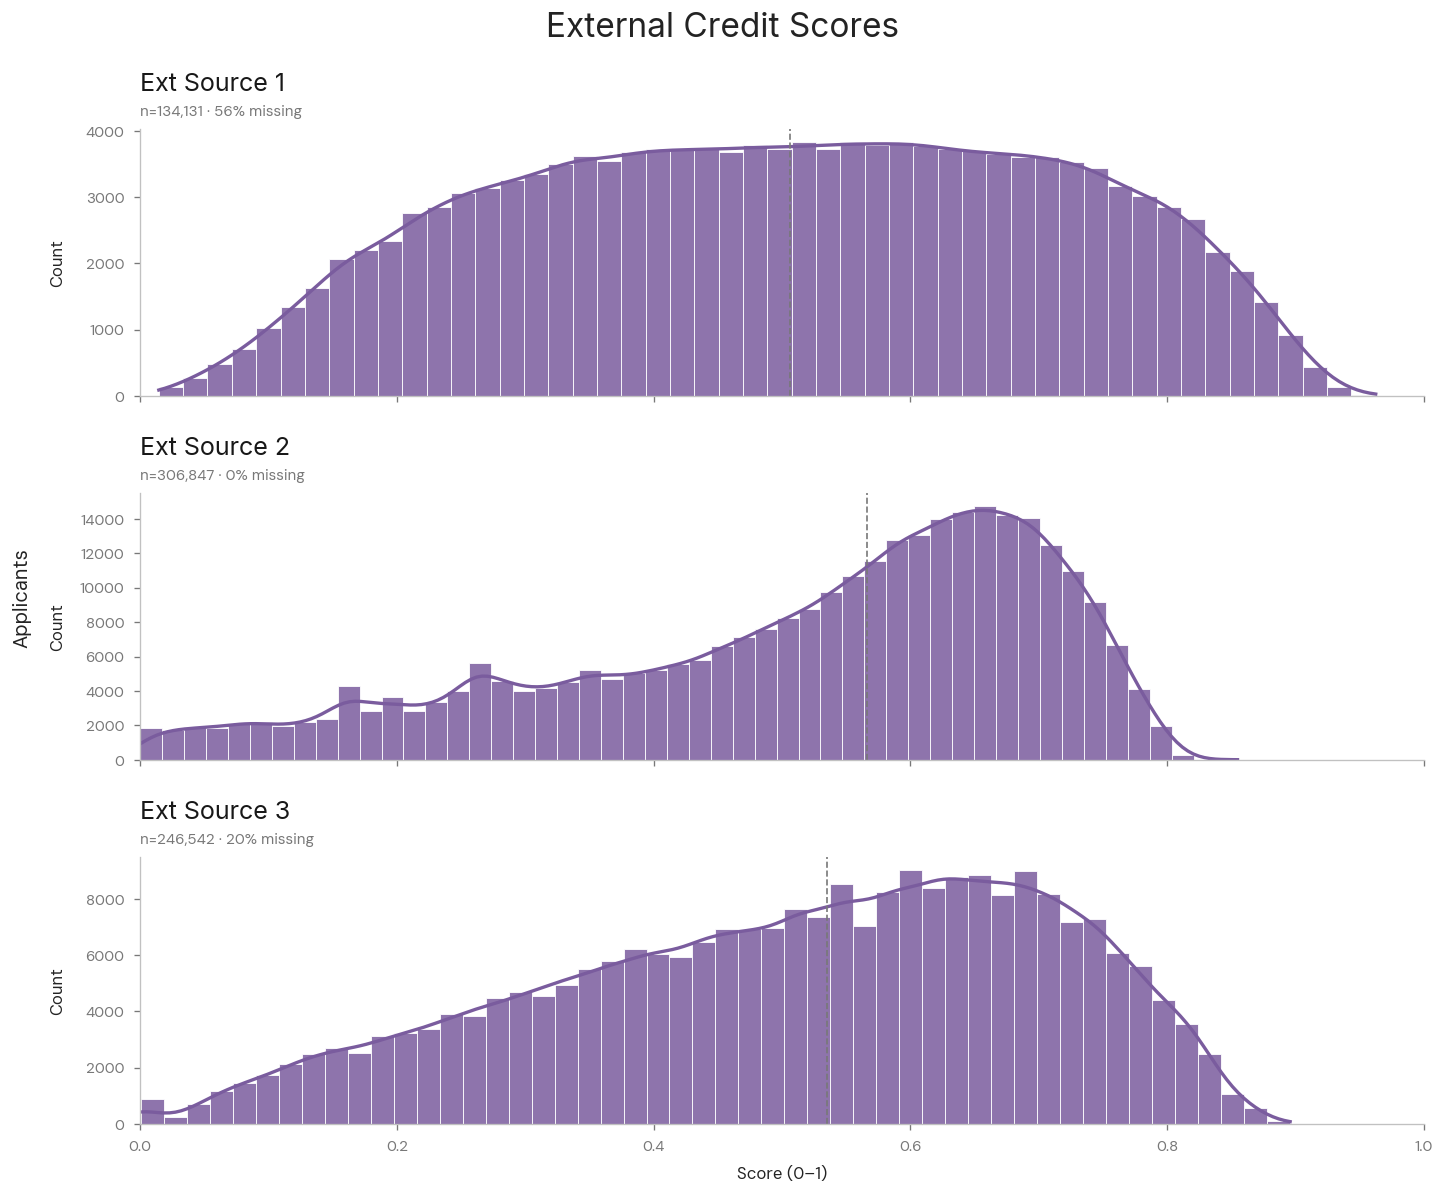

In [33]:
# External Scores Histograms

fig, axes = eda.histogram_per_group(
    df, cols_by_theme['external_scores'],
    ncols=1,                 # stacked vertically
    panel_w=11, panel_h=3, # wider + taller per panel
    xlabel='Score (0–1)', sharex=True, kde=True,
)

# Axes Level Edits

for ax in axes:
    ax.set_xlim(0, 1)
    
# Figure Level Edits

fig.set_size_inches(12, 10)          # resize the whole figure
fig.suptitle('External Credit Scores', fontfamily=f('heading'), fontsize=s('display'))
# fig.supxlabel('Score (0–1)')         # one shared x-label for all panels
fig.supylabel('Applicants')          # one shared y-label
fig.subplots_adjust(hspace=0.4)      # gap between stacked panels
fig.align_ylabels()                  # line up y-labels across panels
fig.savefig('ext_scores.png', dpi=150, bbox_inches='tight')  # export

plt.show()

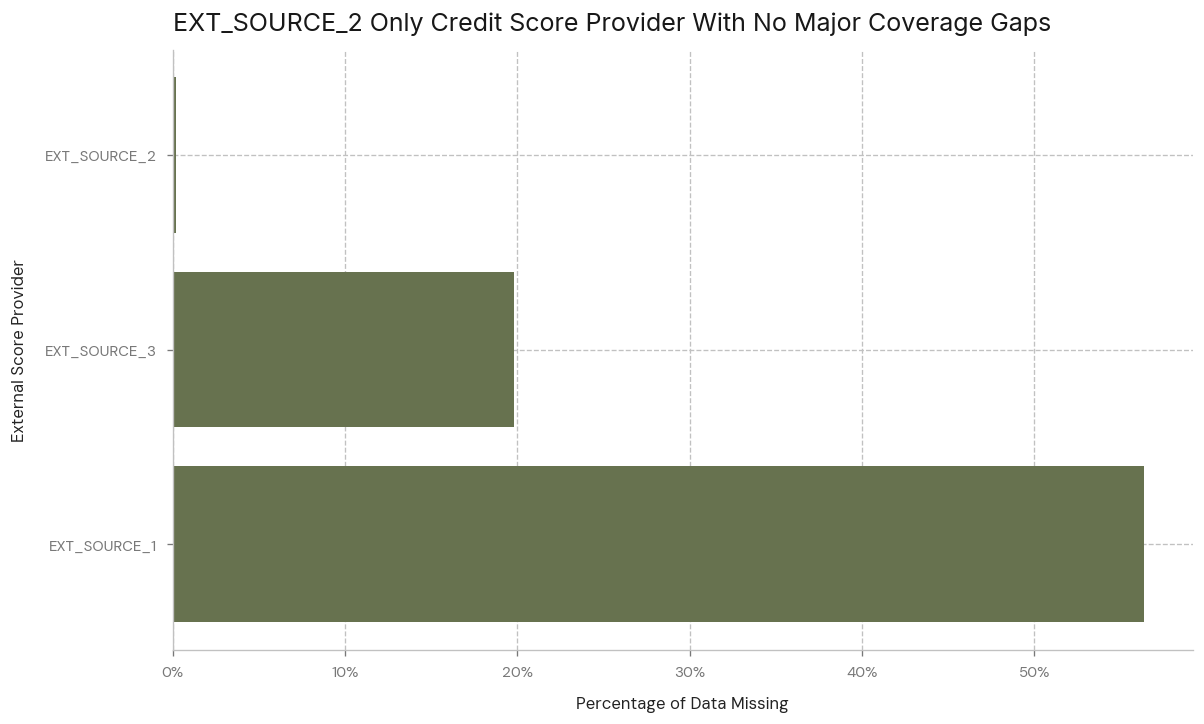

In [34]:
# External Scores Missingness

external_scores_missing = df[cols_by_theme['external_scores']].isnull().sum() / len(df)

external_scores_missing = external_scores_missing.sort_values(ascending=False)

fig, ax = plt.subplots(figsize = (10,6))

ax.barh(external_scores_missing.index, 
        external_scores_missing.values,
        color = C.tertiary,
        )

ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_ylabel('External Score Provider', labelpad=10)
ax.set_xlabel('Percentage of Data Missing', labelpad=10)
ax.set_title('EXT_SOURCE_2 Only Credit Score Provider With No Major Coverage Gaps', fontsize=s('title'), fontfamily=f('heading'))
plt.show()


**Observation.** All three scores sit on a 0-1 scale with no extreme outliers, so they can be binned directly without trimming. Their shapes differ, which suggests each provider scores differently:
- EXT_SOURCE_1: roughly symmetric around 0.5, but only 44% populated (56% missing).
- EXT_SOURCE_2: left-skewed, peaks near 0.65, fully populated.
- EXT_SOURCE_3: left-skewed, peaks near 0.65-0.70, ~80% populated.

All three separate the classes clearly. Defaulters cluster at low scores, and default rate falls steadily across quantile bins (lowest bin ~20-23%, highest ~2-3%, against the 8.1% base rate). Discrimination is close between them: Gini 0.36 / 0.33 / 0.31 and KS 0.27 / 0.24 / 0.22 (SOURCE_3 / 1 / 2). Coverage (100% / 80% / 44% for SOURCE_2 / 3 / 1) makes EXT_SOURCE_2 the most usable in practice. The different shapes and coverage suggest each score adds some separate signal, which the intercorrelation heatmap below checks.

#### Bivariate Analysis

##### Mean Score Comparison

The quickest bivariate view: the mean of each score for defaulters vs non-defaulters. It shows *whether* the groups differ, but not *how* risk changes across the score range. The plots below show that shape.

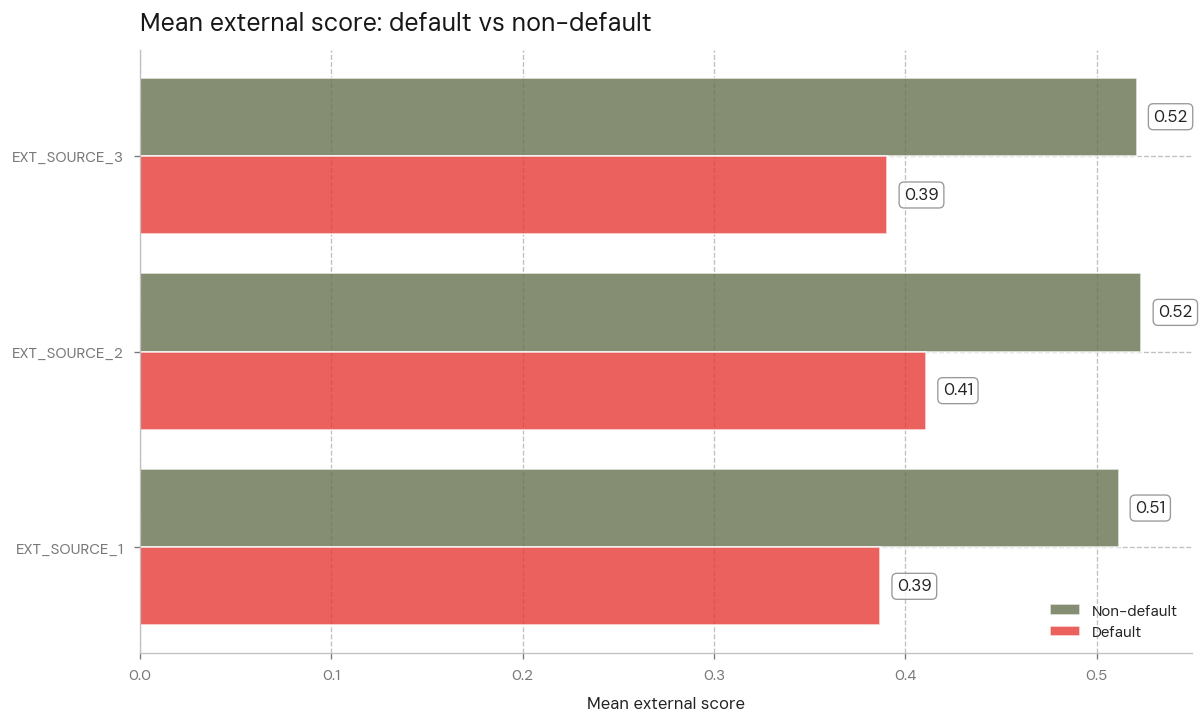

In [35]:
# External Scores Mean by Default Status

defaulters = df[cols_by_theme['external_scores']][df['TARGET'] == 1].mean()
non_defaulters = df[cols_by_theme['external_scores']][df['TARGET'] == 0].mean()

means = pd.DataFrame({'Default': defaulters, 'Non-default': non_defaulters})

x = np.arange(len(means))
w = 0.4

fig, ax = plt.subplots(figsize=(10,6))

bars_2 = ax.barh(x + w/2, means['Non-default'], w, label='Non-default', edgecolor='white', color=C.tertiary, alpha=0.8)
bars_1 = ax.barh(x - w/2, means['Default'],     w, label='Default', edgecolor='white', color=C.default, alpha=0.8)

ax.set_yticks(x)
ax.set_yticklabels(means.index, rotation=0)
ax.set_xlabel('Mean external score')
ax.set_title('Mean external score: default vs non-default')
ax.legend()

ax.bar_label(bars_1,
             padding=10,
             fmt='%.2f',
             bbox=dict(
                 boxstyle='round',
                 facecolor='white',
                 edgecolor='grey',
                 alpha = 0.8,
                 linewidth=0.8
             ))

ax.bar_label(bars_2,
             padding=10,
             fmt='%.2f',
             bbox=dict(
                 boxstyle='round',
                 facecolor='white',
                 edgecolor='grey',
                 alpha = 0.8,
                 linewidth=0.8
             ))

plt.show()


##### Histogram

Score distributions for defaulters and non-defaulters overlaid, to see where the two groups separate.

(0.0, 1.0)

(0.0, 1.0)

(0.0, 1.0)

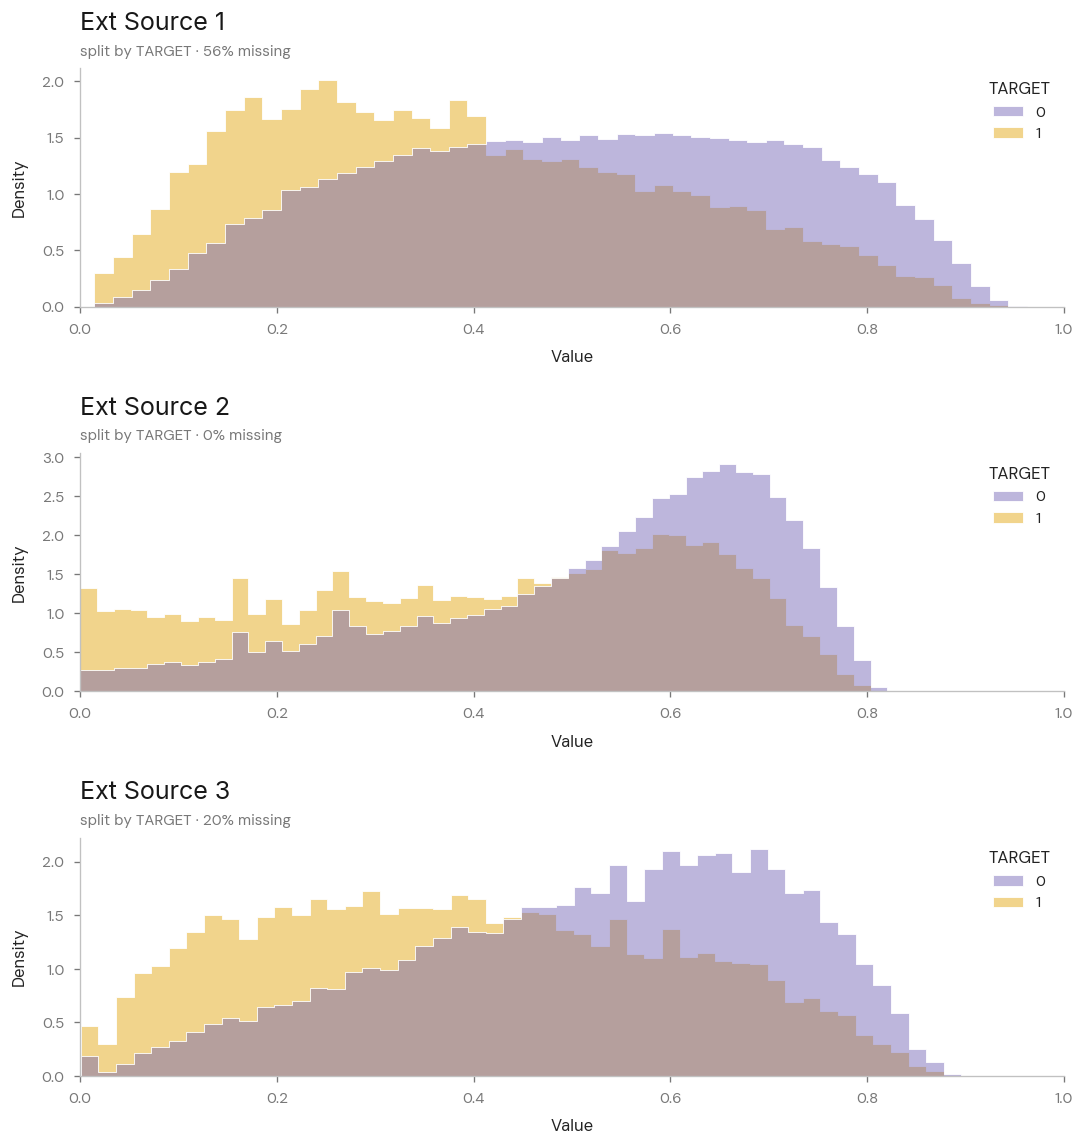

In [36]:
# External Scores Histograms

from credit_utils.eda import overlaid_histogram_per_group

fig, axes = overlaid_histogram_per_group(
    df, cols_by_theme['external_scores'], by='TARGET', ncols=1, edgecolor='white',
    palette={0: RISK_LOW, 1: RISK_HIGH}  # colour-blind-safe: non-default=purple, default=gold
)

# Axes Level Edits

for ax in axes:
    ax.set_xlim(0, 1)
    
# Figure Level Edits


plt.show()

##### Default Rate by Bin

The main bivariate plot. Each score is cut into 20 equal-population (quantile) bins, and the chart shows the **default rate in each bin**. This gives the shape of the risk relationship. Ideally it declines steadily (higher score, lower default rate), which is what justifies using the score in a scorecard. The dashed line is the base default rate, so bins above it are riskier than average. Binning a continuous feature this way is the same as default rate per category, so this one chart works for both continuous and categorical features.

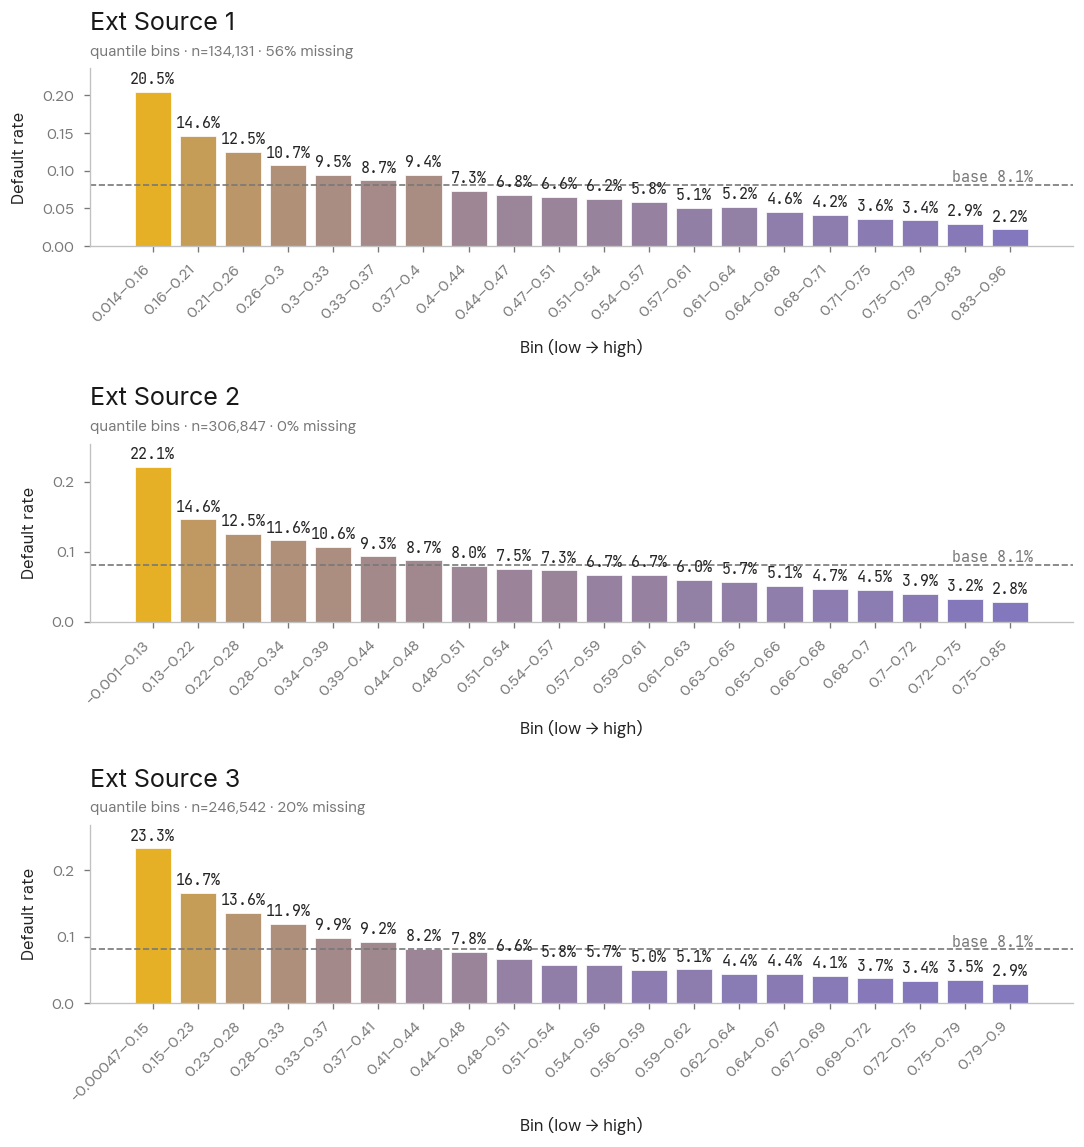

In [37]:
# External Scores Default Rate by Bin

# AI generated function for assessing default rate by bin

from credit_utils.eda import default_rate_by_bin

fig, axes = default_rate_by_bin(
    df, cols_by_theme['external_scores'], target='TARGET', ncols=1, bins=20, grade_scale=risk_cmap()
)

# Axes-level edits
# for ax in axes:
#     ax.set_ylim(0, 0.2)

plt.show()

##### Discrimination (AUC / Gini)

These features are credit scores themselves, so each one's ability to separate defaulters from non-defaulters can be measured on its own with ROC-AUC, and with Gini (2 × AUC − 1), the metric the industry ranks scores by. The score is negated so that a low score lines up with the default class. An AUC well above 0.5 means real signal. `coverage` is the non-missing share: a strong but sparse score may add less in practice.

_Why these metrics only appear here:_ AUC, Gini and KS measure how well an existing **score** ranks risk, so they suit the external scores, which are already risk scores. Raw features (income, age, etc.) are screened with **IV / WOE** instead, because a non-monotonic feature can have a low AUC but a high IV.

In [38]:
# Import

from sklearn.metrics import roc_auc_score

# The accumulator

auc_rows = []

# loop through column list

for c in cols_by_theme['external_scores']:
    
    m = df[c].notna()       # Mask for missing values 
    
    auc = roc_auc_score(df.loc[m, 'TARGET'], -df.loc[m, c])   # Calculate auc
    
    auc_rows.append({'feature' : c,             # Create dictionary to print scores for the column
                     'AUC': round(auc, 3),
                     'Gini': round(2 * auc -1, 3),
                     'coverage': round(m.mean(), 3)})
    
# Turn into a df for display 
    
auc_df = (pd.DataFrame(auc_rows)
          .sort_values('Gini', ascending=False)
          .reset_index(drop=True))

auc_df

,feature,AUC,Gini,coverage
0,EXT_SOURCE_3,0.68,0.36,0.80
1,EXT_SOURCE_1,0.67,0.33,0.44
2,EXT_SOURCE_2,0.66,0.31,1.00


##### Separation (KS & ECDF)

The Kolmogorov-Smirnov (KS) statistic is the standard separation measure in scoring. It is the largest vertical gap between the cumulative distributions (ECDFs) of the two classes. Plotting both ECDFs lets you read the separation straight off the chart: a bigger gap means the score pulls defaulters and non-defaulters further apart. KS and AUC usually rank the scores the same way.

##### KS Statistics

In [39]:
from scipy.stats import ks_2samp

#  Accumulator

ks_rows = []

# Loop through columns

for c in cols_by_theme['external_scores']:
    
    m = df[c].notna()  # mask out missing values
    
    d = df.loc[m & (df['TARGET'] == 1), c]  # Defaulter Scores
    n = df.loc[m & (df['TARGET'] == 0), c]  # Non Defaulter Scores
    
    stat, p = ks_2samp(d, n)  # KS Stat + P-value
    
    ks_rows.append({'feature': c,
                    'KS': round(stat, 3),
                    'p_value': round(p, 4),
                    'coverage': round (m.mean(), 3)})
    
    
ks_df = (pd.DataFrame(ks_rows).sort_values('KS', ascending=False).reset_index(drop=True))

ks_df

,feature,KS,p_value,coverage
0,EXT_SOURCE_3,0.27,0.00,0.80
1,EXT_SOURCE_1,0.24,0.00,0.44
2,EXT_SOURCE_2,0.22,0.00,1.00


##### ECDF Plot

Cumulative share of each group by score. The KS statistic is the widest vertical gap between the two lines.

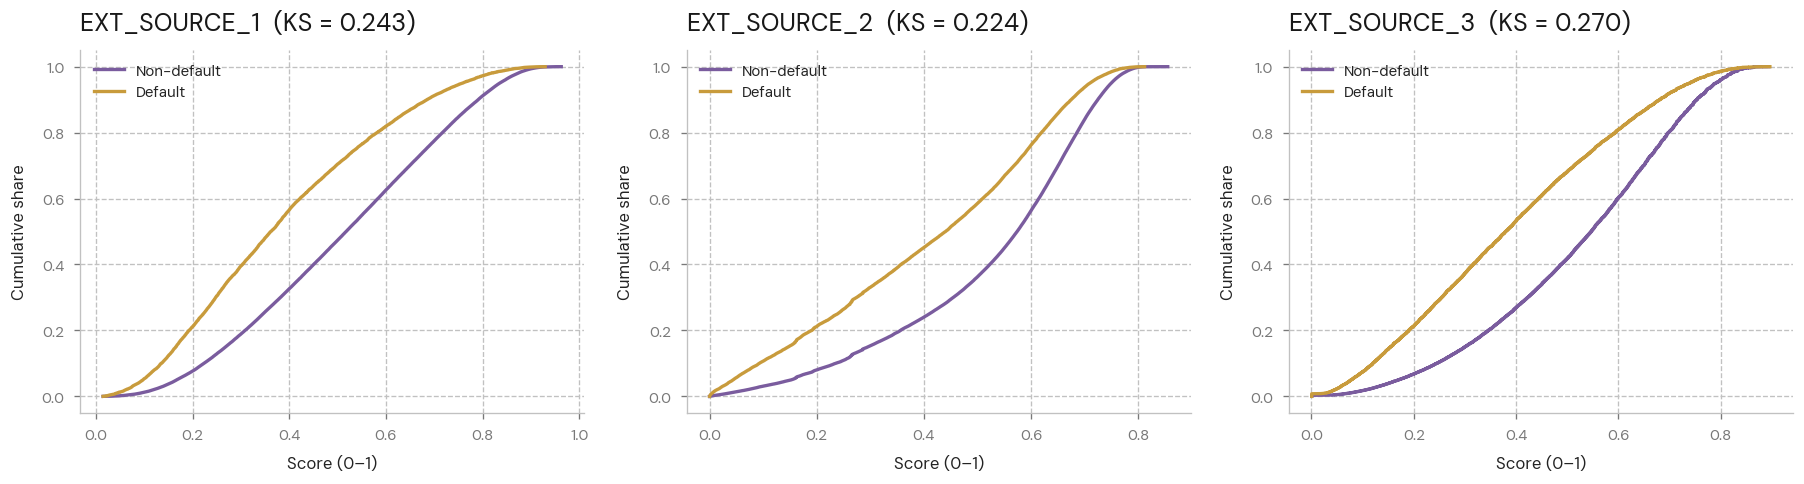

In [40]:
# External Scores ECDF by Default Status

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, c in zip(axes, cols_by_theme['external_scores']):
    
    m = df[c].notna()
    d = df.loc[m & (df['TARGET'] == 1), c]  # Defaulter Scores
    n = df.loc[m & (df['TARGET'] == 0), c]  # Non Defaulter Scores
    
    for grp, label in [(n, 'Non-default'), (d, 'Default')]:
        
        x = np.sort(grp)
        y = np.arange(1, len(x) + 1 )/ len(x)
        ax.plot(x, y, label=label)
        
    stat, _ = ks_2samp(d, n)
    
    ax.set_title(f'{c}  (KS = {stat:.3f})')              # KS in the title
    ax.set_xlabel('Score (0–1)')
    ax.set_ylabel('Cumulative share')
    ax.legend()
    
plt.show()

##### Score Intercorrelation

Not a target relationship, but useful context: with three scores, how much do they overlap? Highly correlated scores carry the same signal, so only some will survive feature selection. Weakly correlated scores are more likely to each add something to the model. Correlation is pairwise-complete, so each pair uses the rows where both scores are present and EXT_SOURCE_1's missing values don't blank out the matrix.

              EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3
EXT_SOURCE_1 1.00          0.21          0.19         
EXT_SOURCE_2 0.21          1.00          0.11         
EXT_SOURCE_3 0.19          0.11          1.00         


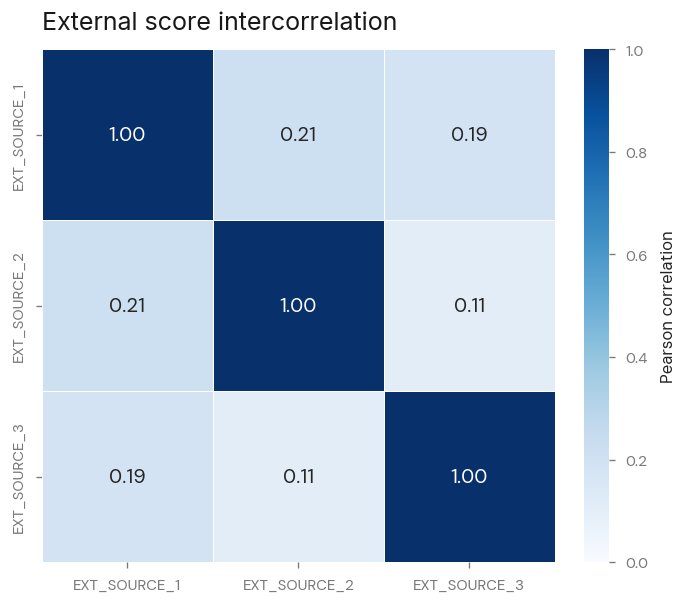

In [41]:
# External Score Intercorrelation

ext_cols = cols_by_theme['external_scores']

# Pairwise-complete correlation
ext_corr = df[ext_cols].corr()
print(ext_corr.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    ext_corr,
    cmap='Blues',              # neutral colour scale
    vmin=0, vmax=1,
    annot=True, fmt='.2f', annot_kws={'size': 12},
    square=True, linewidths=0.5,
    cbar_kws={'label': 'Pearson correlation'},
    ax=ax,
)
ax.set_title('External score intercorrelation',
             fontfamily=f('heading'), fontsize=s('title'))
plt.show()


**Observation / Decision.** All three scores separate defaulters from non-defaulters clearly and steadily: default rate falls from ~20-23% in the lowest quantile bin to ~2-3% in the highest, against the 8.1% base. Discrimination is solid and close between them (Gini 0.31-0.36, KS 0.22-0.27). EXT_SOURCE_3 is the strongest, and EXT_SOURCE_2 the most usable with full coverage.

**Decision:** carry all three into Section 5 as binned WOE features, with **missing as its own bin**, since missing values can carry signal of their own (EXT_SOURCE_1 is 56% missing). Keep all three unless the intercorrelation check above shows a pair is strongly redundant (|r| > ~0.7).

### 3.2 Loan Financials

**Explanation.** The loan amounts (`AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`) describe loan size and affordability. Expect heavy right skew and outliers. The question is whether to log-transform them or use quantile bins.

#### Univariate Analysis

Log-scale histograms of the four amounts, plus counts for contract type.

In [42]:
cols_by_theme.keys()

dict_keys(['id_target', 'external_scores', 'loan_financials', 'demographics', 'employment', 'assets', 'contact', 'client_timeline', 'application_timing', 'region', 'building_stats', 'social_circle', 'document_flags', 'bureau_enquiries'])

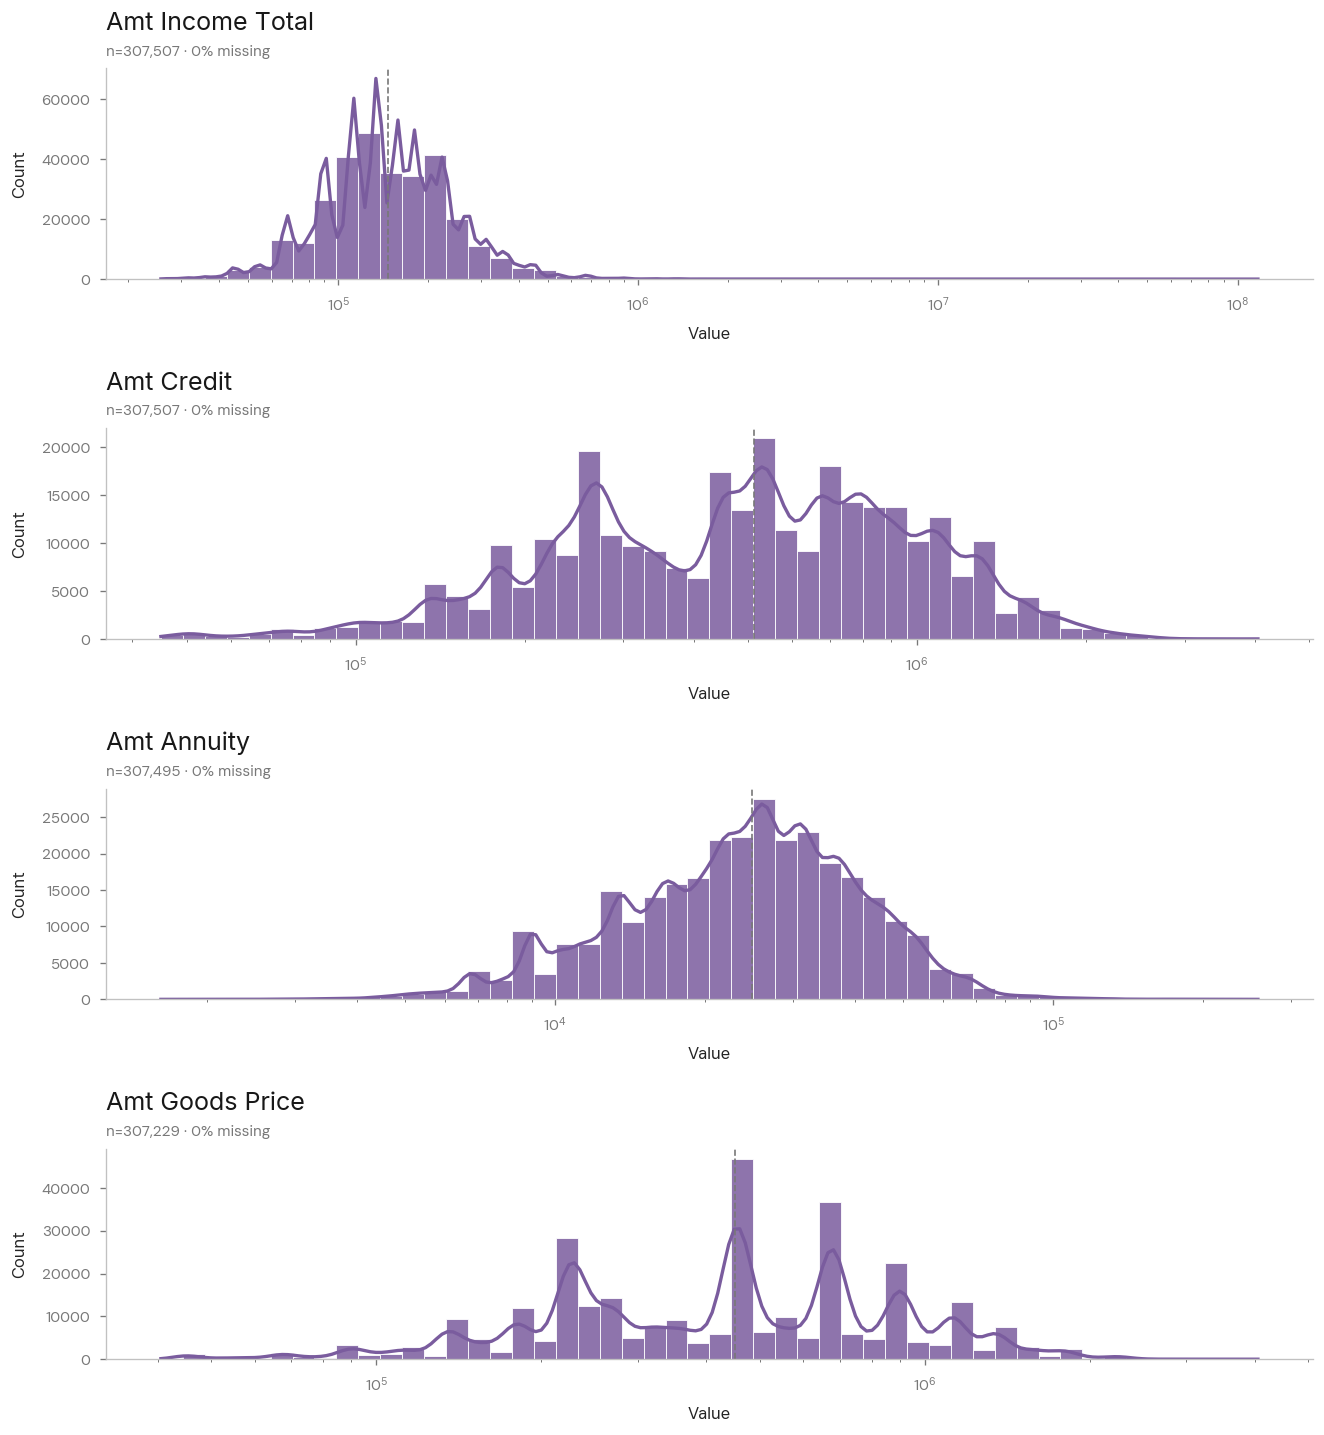

In [43]:
# Loan Financials Numeric Variables Histograms

fig, axes = eda.histogram_per_group(
    df, cols_by_theme['loan_financials'],
    ncols=1,                 # stacked vertically
    panel_w=11, panel_h=3, # wider + taller per panel
    sharex=False, kde=True, logx=True
)

# Axes Level Edits

for ax in axes:
    ax.set_xscale('log')


plt.show()

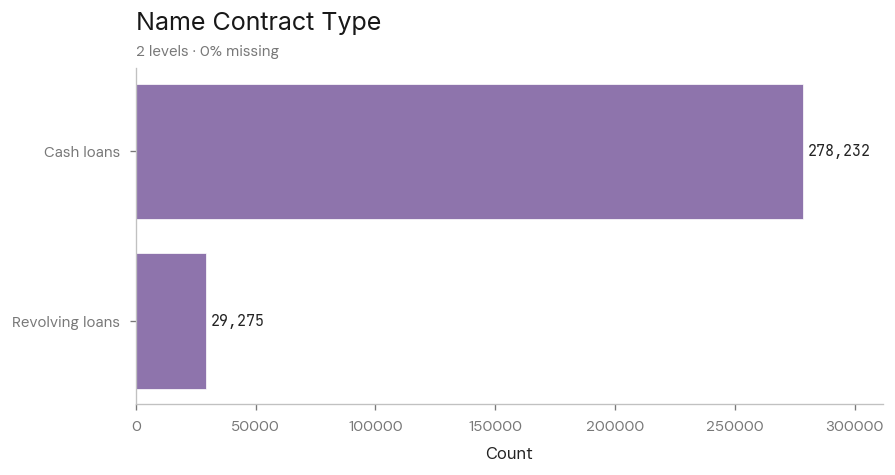

In [44]:
# Loan Financials Categorical Bar Counts

eda.frequency_per_group(df, cols_by_theme['loan_financials'])   # → only NAME_CONTRACT_TYPE
plt.show()

**Observation.** All four amounts are heavily right-skewed even on a log axis, with extreme upper tails. AMT_INCOME_TOTAL reaches ~$100M, a clear outlier. AMT_CREDIT and AMT_GOODS_PRICE have several peaks, with spikes at round product prices. AMT_ANNUITY is the smoothest (roughly log-normal). Coverage is effectively complete (~0% missing). NAME_CONTRACT_TYPE has two levels: Cash 90.5% and Revolving 9.5%.

Because of the skew and outliers, averages are misleading. Rank-based bins are robust to the tails, so no outlier trimming or log transform is needed for WOE. The log axis is only there to make the charts readable.

#### Bivariate Analysis

Mean amount by default status, default rate across quantile bins, then the contract type mix and default rate by contract type.

In [45]:
df[cols_by_theme['loan_financials']]

,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
0,Cash loans,202500.00,406597.50,24700.50,351000.00
1,Cash loans,270000.00,1293502.50,35698.50,1129500.00
2,Revolving loans,67500.00,135000.00,6750.00,135000.00
3,Cash loans,135000.00,312682.50,29686.50,297000.00
4,Cash loans,121500.00,513000.00,21865.50,513000.00
...,...,...,...,...,...
307506,Cash loans,157500.00,254700.00,27558.00,225000.00
307507,Cash loans,72000.00,269550.00,12001.50,225000.00
307508,Cash loans,153000.00,677664.00,29979.00,585000.00
307509,Cash loans,171000.00,370107.00,20205.00,319500.00


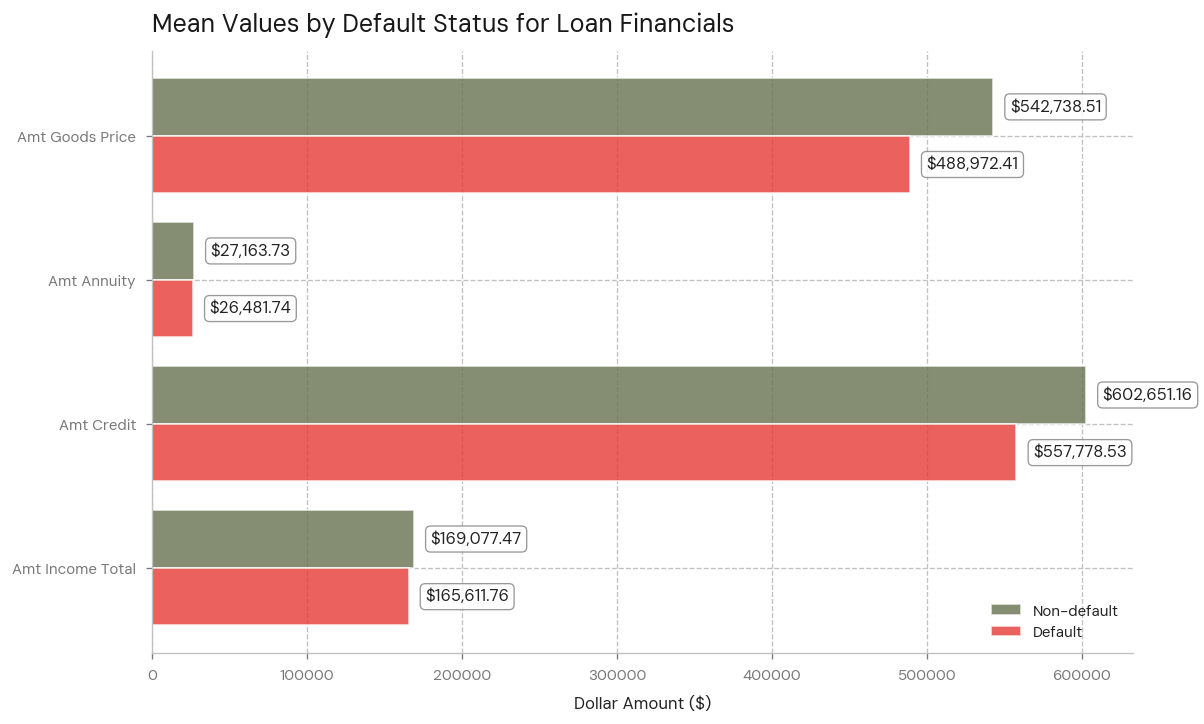

In [46]:
# Loan Financials Mean by Default Status

cols = [c for c in cols_by_theme['loan_financials'] if c != 'NAME_CONTRACT_TYPE']

defaulters = df[cols][df['TARGET'] == 1].mean()
non_defaulters = df[cols][df['TARGET'] == 0].mean()

means = pd.DataFrame({'Default': defaulters, 'Non-default': non_defaulters})

x = np.arange(len(means))
w = 0.4

fig, ax = plt.subplots(figsize=(10,6))

bars_2 = ax.barh(x + w/2, means['Non-default'], w, label='Non-default', edgecolor='white', color=C.tertiary, alpha=0.8)
bars_1 = ax.barh(x - w/2, means['Default'],     w, label='Default', edgecolor='white', color=C.default, alpha=0.8)

ax.set_yticks(x)
ax.set_yticklabels(means.index.str.replace('_', ' ').str.title(), rotation=0)
ax.set_xlabel('Dollar Amount ($)')
ax.set_title('Mean Values by Default Status for Loan Financials ')
ax.legend()

ax.bar_label(bars_1,
             padding=10,
             fmt='${:,.2f}',
             bbox=dict(
                 boxstyle='round',
                 facecolor='white',
                 edgecolor='grey',
                 alpha = 0.8,
                 linewidth=0.8
             ))

ax.bar_label(bars_2,
             padding=10,
             fmt='${:,.2f}',
             bbox=dict(
                 boxstyle='round',
                 facecolor='white',
                 edgecolor='grey',
                 alpha = 0.8,
                 linewidth=0.8
             ))

plt.show()


['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']


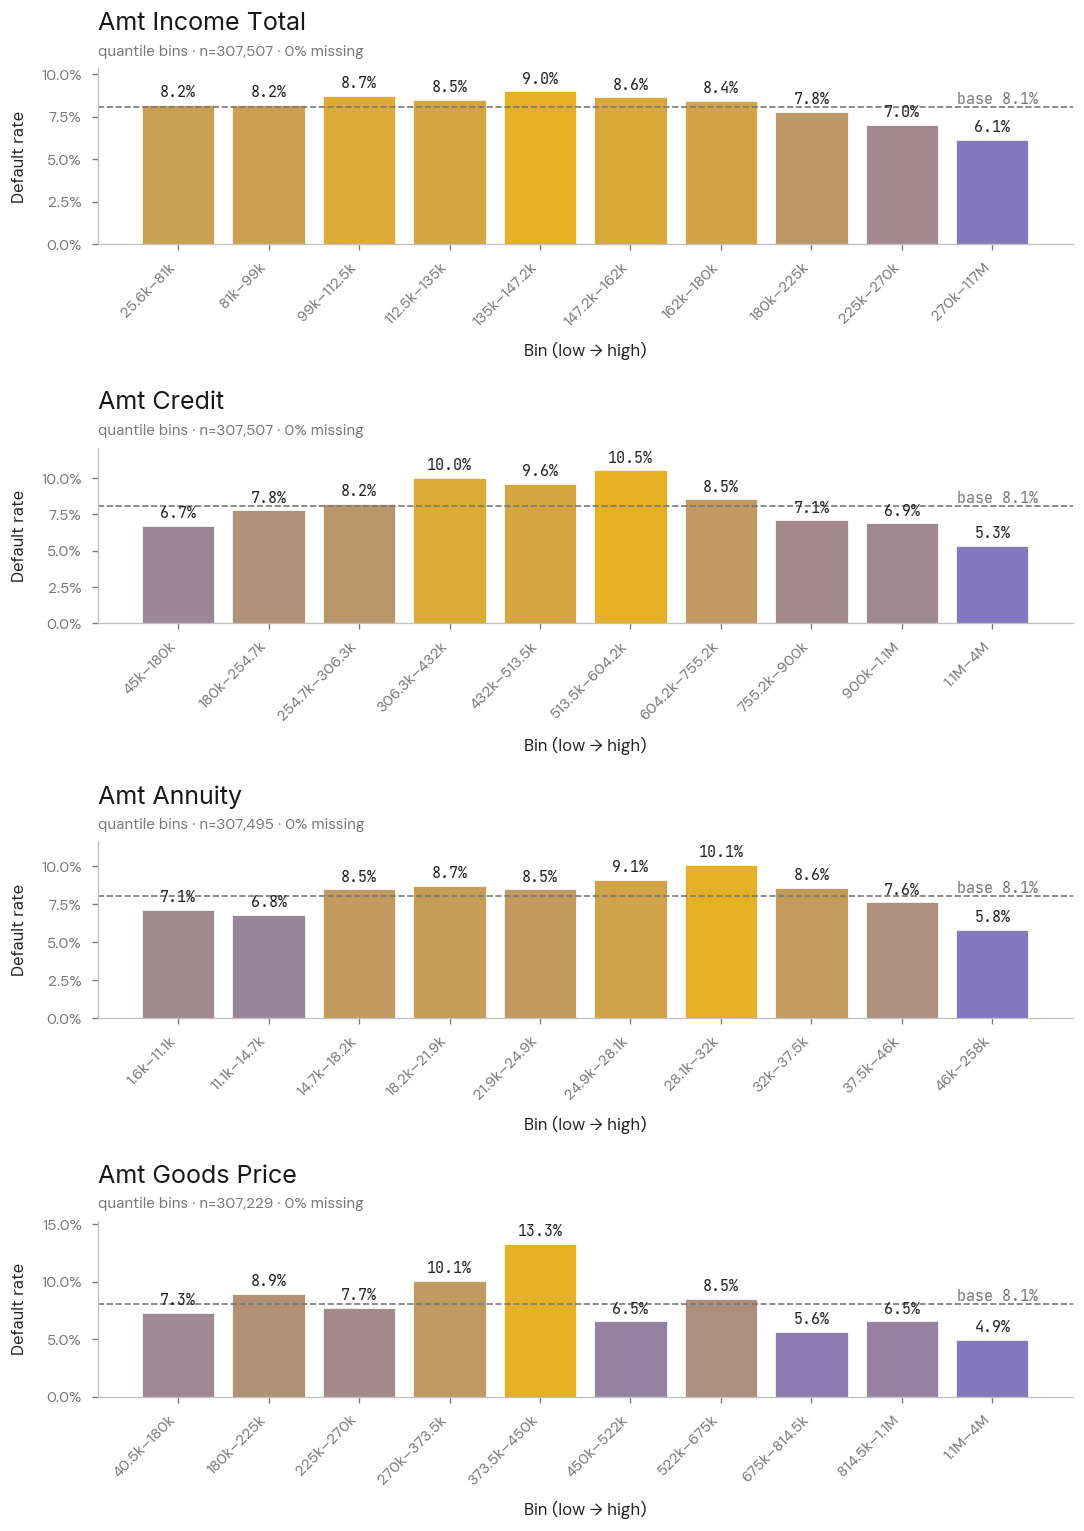

In [47]:
# Loan Financials Default Rate by Bin

numeric_cols = [c for c in df[cols_by_theme['loan_financials']] if c != 'NAME_CONTRACT_TYPE']

print(numeric_cols)

# AI generated function for assessing default rate by bin

from credit_utils.eda import default_rate_by_bin

fig, axes = default_rate_by_bin(
    df, numeric_cols, target='TARGET', ncols=1, bins=10, method = 'quantile', grade_scale=risk_cmap()
)

# Axes-level edits
for ax in axes:
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    # ax.set_xticks(range(len(rate)))

plt.show()

NAME_CONTRACT_TYPE
Cash loans        0.90
Revolving loans   0.10
Name: proportion, dtype: float64

(-0.6, 1.6)

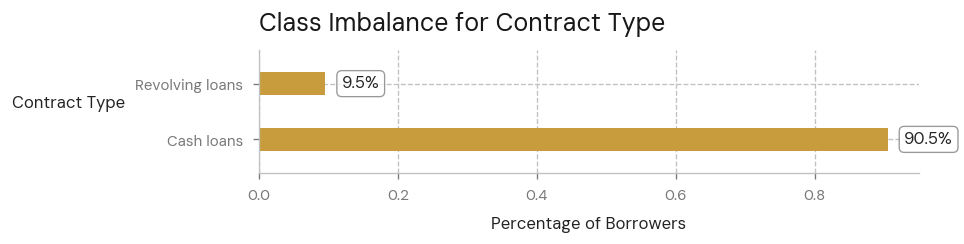

In [48]:
# Contract Type Class Imbalance

contract_type = df['NAME_CONTRACT_TYPE'].value_counts(normalize=True)

contract_type.head(5)

labels = ['Cash Loans', 'Revolving Loans']
y = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(8,2))

bars_1 = ax.barh(contract_type.index, contract_type.values, color=C.secondary, height = 0.4)

ax.bar_label(bars_1,
             padding=10,
             fmt='{:.1%}',
             bbox=dict(
                 boxstyle='round',
                 facecolor='white',
                 edgecolor='grey',
                 alpha = 0.8,
                 linewidth=0.8
             ))

ax.set_ylim(-0.6, 1.6)

ax.set_title('Class Imbalance for Contract Type')
ax.set_xlabel('Percentage of Borrowers')
ax.set_ylabel('Contract Type', rotation=0, labelpad=40)
plt.show()


NAME_CONTRACT_TYPE
Cash loans        0.08
Revolving loans   0.05
Name: TARGET, dtype: float64

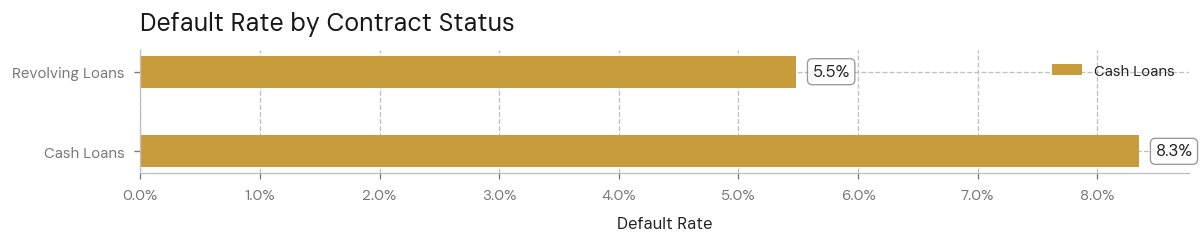

In [49]:
# Default Rate by Contract Type

default_rate = df.groupby('NAME_CONTRACT_TYPE', dropna=False)['TARGET'].mean()

default_rate.head(5)

fig, ax = plt.subplots(figsize=(10,2))

labels = ['Cash Loans', 'Revolving Loans']
y = np.arange(len(labels))
h = 0.4

bars_1 = ax.barh(y, default_rate, height = 0.4, label='Cash Loans', color = C.secondary)
ax.set_yticks(y, labels)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

ax.set_title('Default Rate by Contract Status')
ax.set_xlabel('Default Rate')
ax.legend()

ax.bar_label(bars_1,
             padding=10,
             fmt='{:.1%}',
             bbox=dict(
                 boxstyle='round',
                 facecolor='white',
                 edgecolor='grey',
                 alpha = 0.8,
                 linewidth=0.8
             ))

plt.show()

**Observation / Decision.** As raw amounts these are weak drivers, and not monotonic. Default rate across quantile bins is almost flat for AMT_INCOME_TOTAL, and an inverted U for AMT_CREDIT, AMT_ANNUITY and AMT_GOODS_PRICE: the mid-range is riskiest (borrowers stretched closest to their limit on an average income), tapering off at both ends. The mean-by-status chart (defaulters slightly lower on every amount) is misleading because it averages out that inverted U. Each bin holds ~30k applicants, so these shapes are stable signal, not noise from thin bins. Contract type is a mild driver (cash 8.3% vs revolving 5.5% default).

**Decision:** carry the raw amounts into Section 5 as binned WOE features, but expect **low IV**. The real signal should be in the affordability **ratios** built in Section 4:
- repayment-to-income (AMT_ANNUITY / AMT_INCOME), close to serviceability / NSR
- loan-to-income (AMT_CREDIT / AMT_INCOME), i.e. leverage
- loan-to-value (AMT_CREDIT / AMT_GOODS_PRICE), close to LVR; above 1 means financing beyond the asset's value

No log transform is needed for binning, since rank-based bins ignore scale and are robust to the income outlier. NAME_CONTRACT_TYPE is binned as is (2 levels).

### 3.3 Age and Employment

**Explanation.** Age and employment (`DAYS_BIRTH`, `DAYS_EMPLOYED`) are stored as negative days, so convert them to positive years (`/-365`). `DAYS_EMPLOYED` carries the sentinel value flagged in 2.3, so it needs bins plus a missing flag.

#### Univariate Analysis

`DAYS_BIRTH` and `DAYS_EMPLOYED` converted to positive years on a copy of the data (`df_age_years`), then counts for the employment categoricals.

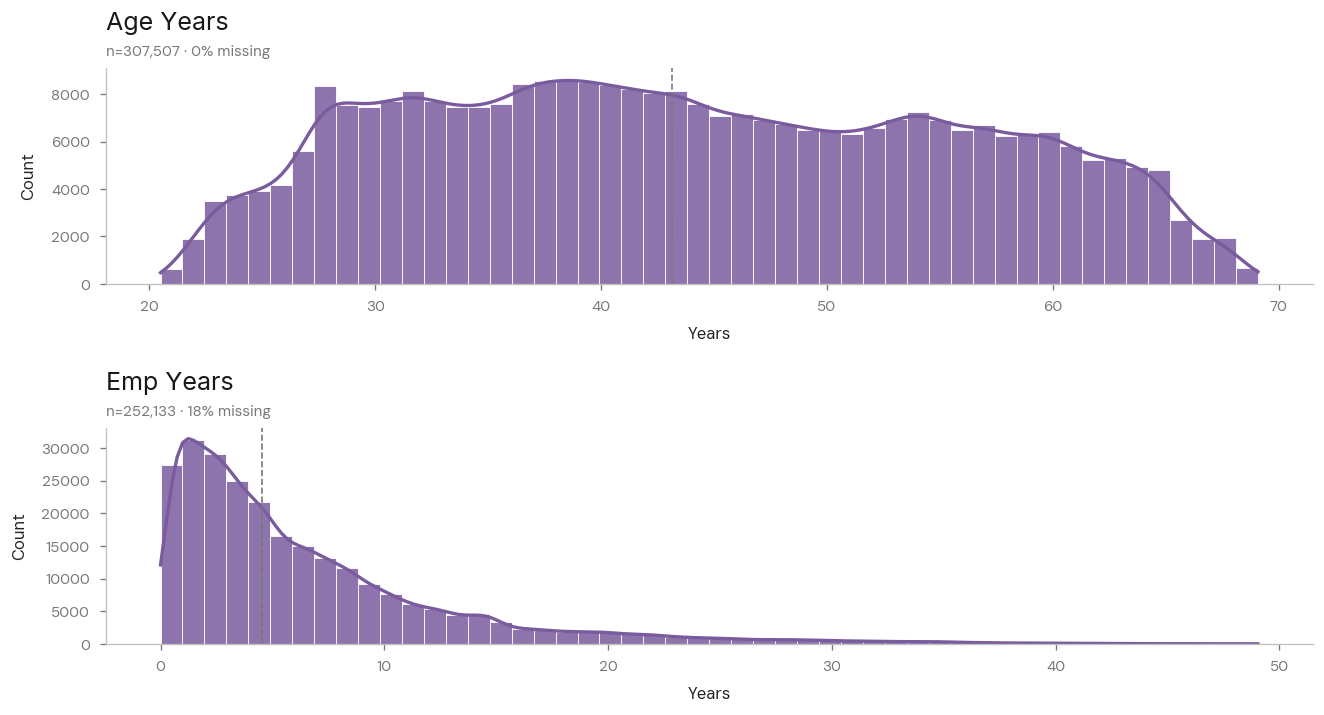

In [50]:

# Age and Employment Numeric Variables Histograms

df_age_years = df.copy()
df_age_years['AGE_YEARS'] = -df_age_years['DAYS_BIRTH']    / 365.25
df_age_years['EMP_YEARS'] =- df_age_years['DAYS_EMPLOYED'] / 365.25

cols_of_interest = ['AGE_YEARS', 'EMP_YEARS']

fig, axes = eda.histogram_per_group(
    df_age_years, cols_of_interest,
    ncols=1,                 # stacked vertically
    panel_w=11, panel_h=3, # wider + taller per panel
    sharex=False, kde=True, logx=False
)

# Axes Level Edits

for ax in axes:
    ax.set_xlabel("Years")

plt.show()

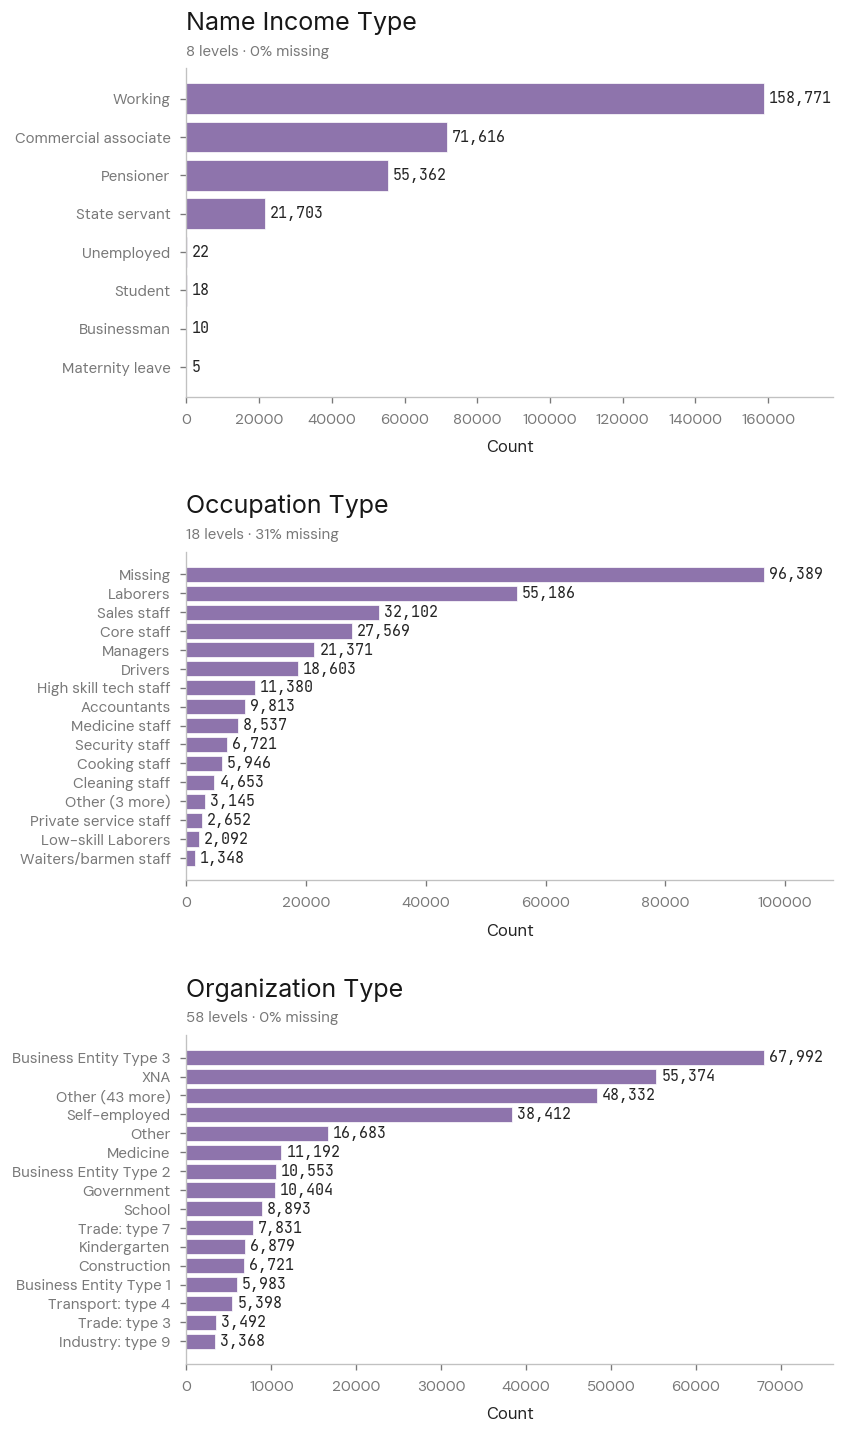

In [51]:
# Age and Employment Categorical Bar Counts

# Get 'CNT_FAM_MEMBERS' and 'CNT_CHILDREN' into separate df and convert to string

df_cat = df.copy()
convert_cat_cols = ['CNT_FAM_MEMBERS', 'CNT_CHILDREN']

df_cat[convert_cat_cols] = df[convert_cat_cols].astype(str)

cols_of_interest = cols_by_theme['employment']

eda.frequency_per_group(df_cat, cols_of_interest, color=C.primary, ncols=1)
plt.show()

**Observation.** Converted to years (`/-365.25`), AGE_YEARS spans ~21-69 and EMP_YEARS ~0-49, and both are smooth. EMP_YEARS is 18% missing: this is the DAYS_EMPLOYED sentinel group (pensioners and unemployed), correctly left out of the tenure distribution. The employment categoricals have many sparse levels (see 2.4). NAME_INCOME_TYPE has tiny levels with extreme risk (Maternity leave ~40%, Unemployed ~37%) and tiny levels with zero defaults (Student, Businessman). OCCUPATION_TYPE is ~31% missing. ORGANIZATION_TYPE is handled through ORG_BAND.

#### Bivariate Analysis

Default rate across fixed age bands (5-year) and tenure milestones (0, 1, 2, 3-4 ... 20+ years), then default rate per level for the employment categoricals.

In [52]:
# Max Values for Age in Years and Years Employed

print((df['DAYS_BIRTH'].min() / 365.25) - (df['DAYS_BIRTH'].max() / 365.25))

print((df['DAYS_EMPLOYED'].min() / 365.25) - (df['DAYS_EMPLOYED'].max() / 365.25))

-48.56947296372347
-49.040383299110196


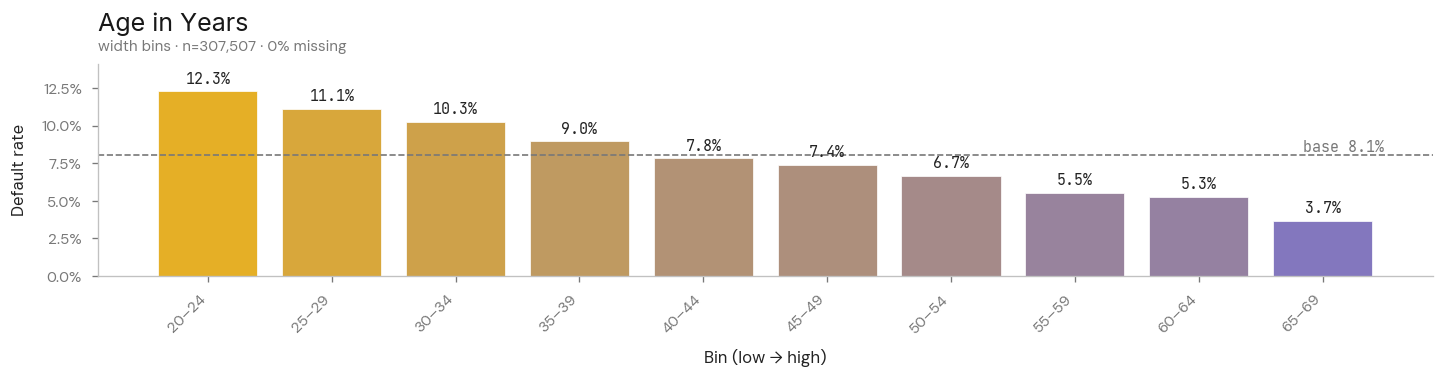

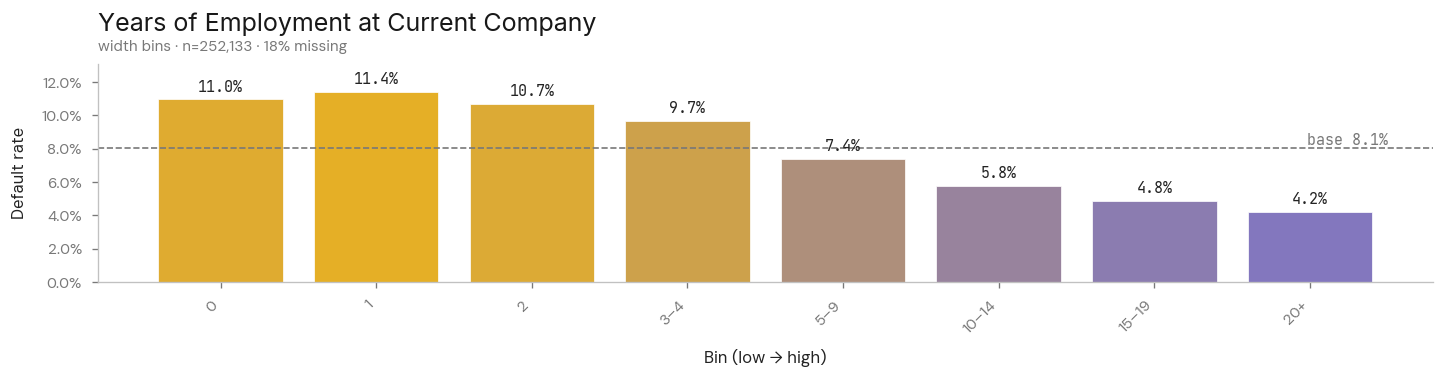

In [53]:


# AI generated function for assessing default rate by bin

from credit_utils.eda import default_rate_by_bin

# Age - 5-year bands
fig, ax = default_rate_by_bin(
    df_age_years, ['AGE_YEARS'], target='TARGET', ncols=1,
    bins=list(range(20, 75, 5)), method='width', right=False,   # left-closed [a, b)
    bin_label='band', bin_num_fmt=lambda v: f"{v:.0f}",
    titles={'AGE_YEARS': 'Age in Years'}, panel_w=12, title_pad=20, grade_scale=risk_cmap()
)
ax[0].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
plt.show()

# Tenure - milestone bands, open top
fig, ax = default_rate_by_bin(
    df_age_years, ['EMP_YEARS'], target='TARGET', ncols=1,
    bins=[0, 1, 2, 3, 5, 10, 15, 20, 50], method='width', right=False,
    bin_label='band', open_top=True, bin_num_fmt=lambda v: f"{v:.0f}",
    titles={'EMP_YEARS': 'Years of Employment at Current Company'},
    panel_w=12, title_pad=20, grade_scale=risk_cmap()
)
ax[0].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
plt.show()

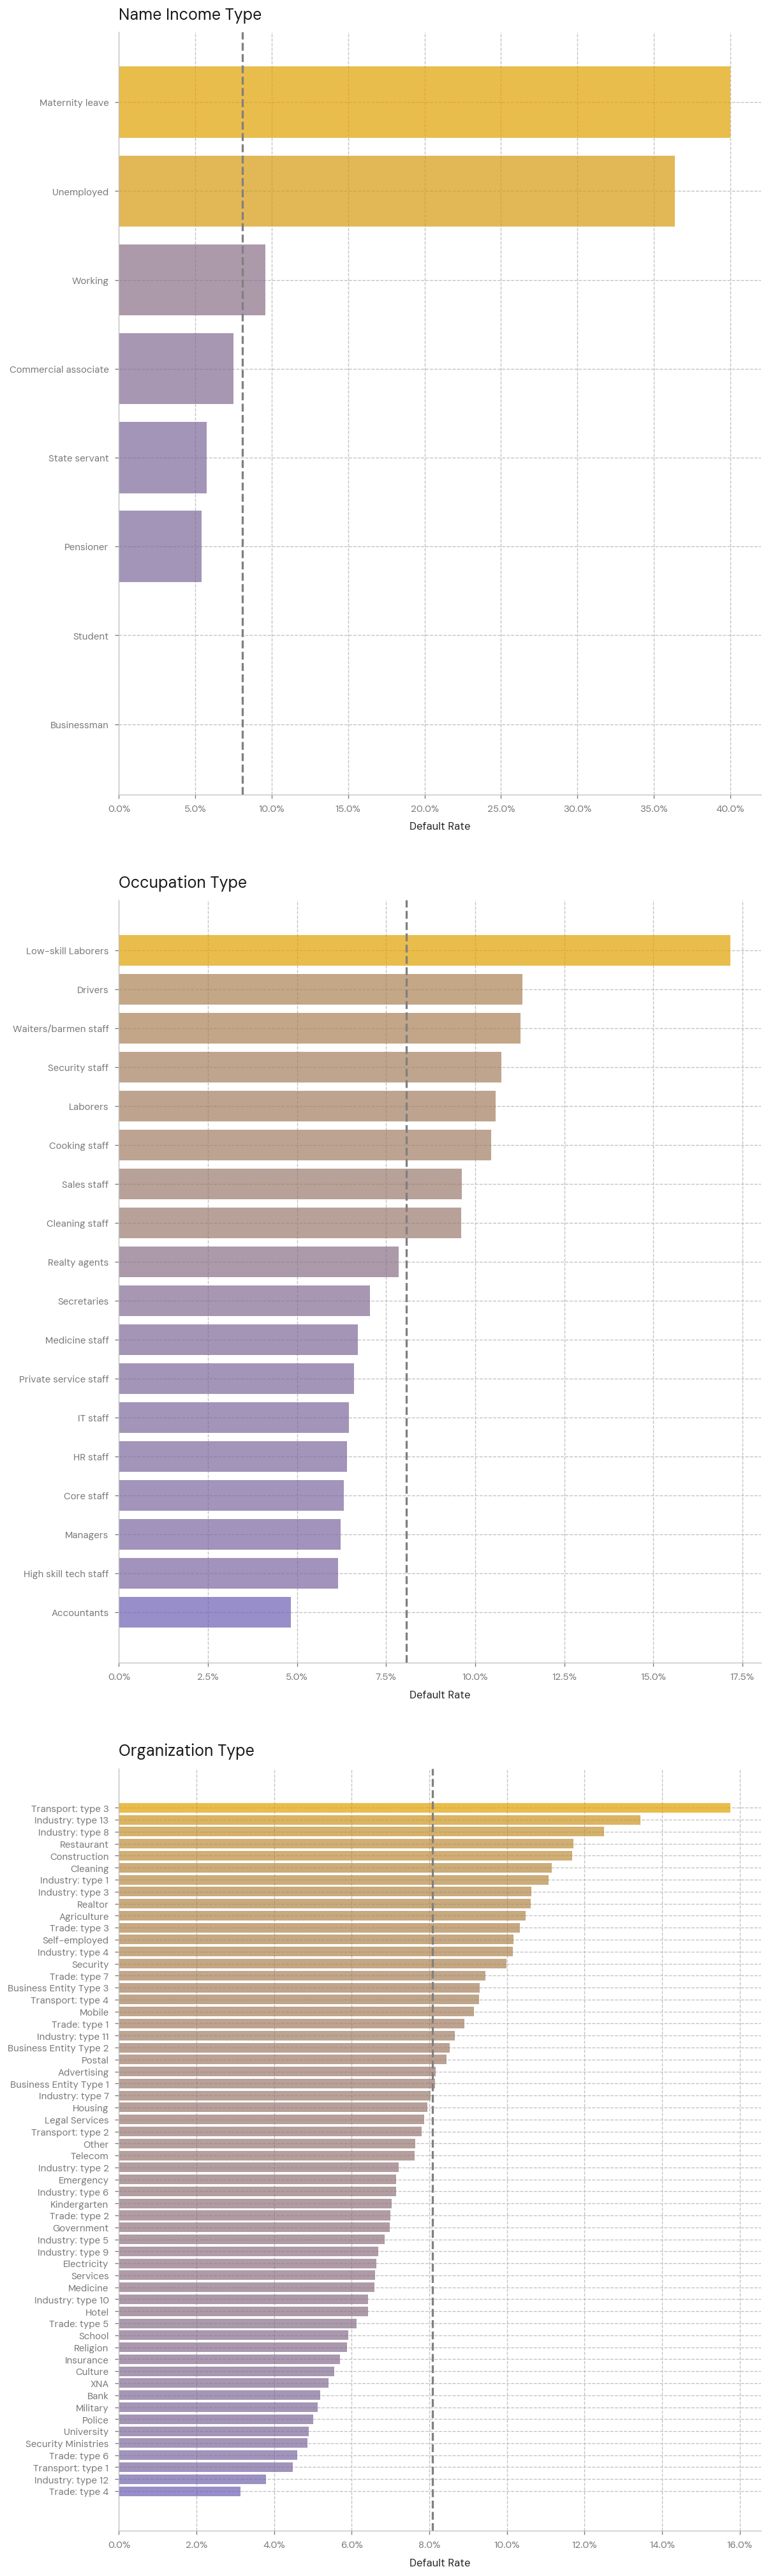

In [54]:
# Employment Default Rate by Category

cols_of_interest = cols_by_theme['employment']
cols_of_interest = [c for c in cols_of_interest if c != 'DAYS_EMPLOYED']

base = df['TARGET'].mean()

length = sum(df[col].nunique() for col in cols_of_interest)

fig, axes = plt.subplots(nrows=len(cols_of_interest), ncols=1,
                         figsize=(10, 0.4 * length))
axes = np.atleast_1d(axes).flatten()

cmap_occupation = risk_cmap()

for ax, col in zip(axes, cols_of_interest):
    rate = df.groupby(col, observed=True)['TARGET'].mean().sort_values()

    norm = colors.Normalize(vmin=rate.min(), vmax=rate.max())
    rgba = cmap_occupation(norm(rate.values))
    rgba[:, 3] = 0.8

    bars_1 = ax.barh(rate.index.astype(str), rate.values, color=rgba, alpha=0.7)
    ax.axvline(base, ls='--', color='grey')
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('Default Rate')
    
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    
    # ax.bar_label(bars_1,
    #          padding=10,
    #          fmt='{:.1%}',
    #          bbox=dict(
    #              boxstyle='round',
    #              facecolor='white',
    #              edgecolor='grey',
    #              alpha = 0.8,
    #              linewidth=0.8
    #          ))

plt.show()

**Observation / Decision.** Age and tenure are strong drivers, close to monotonic. Default falls from 12.3% at age 20-24 to 3.7% at 65-69, and from ~11% at 0-1 years' tenure to 4.2% at 20+ years. Both are proxies for experience and stability, so expect solid IV, well above the loan amounts. NAME_INCOME_TYPE separates sharply (Maternity leave ~40%, Unemployed ~37%, Pensioner ~5%, Student and Businessman 0%). OCCUPATION_TYPE runs from low-skill roles (~17%) to professional (~4.5%). ORGANIZATION_TYPE is covered by ORG_BAND.

One nuance: the DAYS_EMPLOYED sentinel group mixes two very different borrowers, mostly low-risk pensioners plus some high-risk unemployed. Overall, DAYS_EMPLOYED_SENTINEL works as a **low-risk** flag because pensioners dominate it, and NAME_INCOME_TYPE is what tells the two apart.

**Decision:**
- Age and tenure: fixed domain bands (5-year age bands, tenure milestones) for readable, monotonic WOE. Check counts in the thin end bands (65-69, 20+) and merge them if sparse.
- DAYS_EMPLOYED: bin tenure and keep the sentinel/missing group as its own bin (informative, mostly pensioners). Rely on NAME_INCOME_TYPE to split pensioners from unemployed.
- Sparse categorical levels (Student, Businessman, Maternity leave, Unemployed): pool before WOE, since zero defaults gives infinite WOE and tiny levels give unstable IV. Pool with a level of similar default rate, set a minimum count per bin, and fit the grouping on the train split to avoid leakage. Carry to Section 5.

### 3.4 Key Demographic Variables

**Explanation.** Key categoricals (education, family status, income type, contract type). Look at the frequency and default rate of each level, and note sparse levels, which links back to the 2.4 cardinality work.

#### Univariate Analysis

Counts per level for each demographic variable (child and family counts treated as categories).

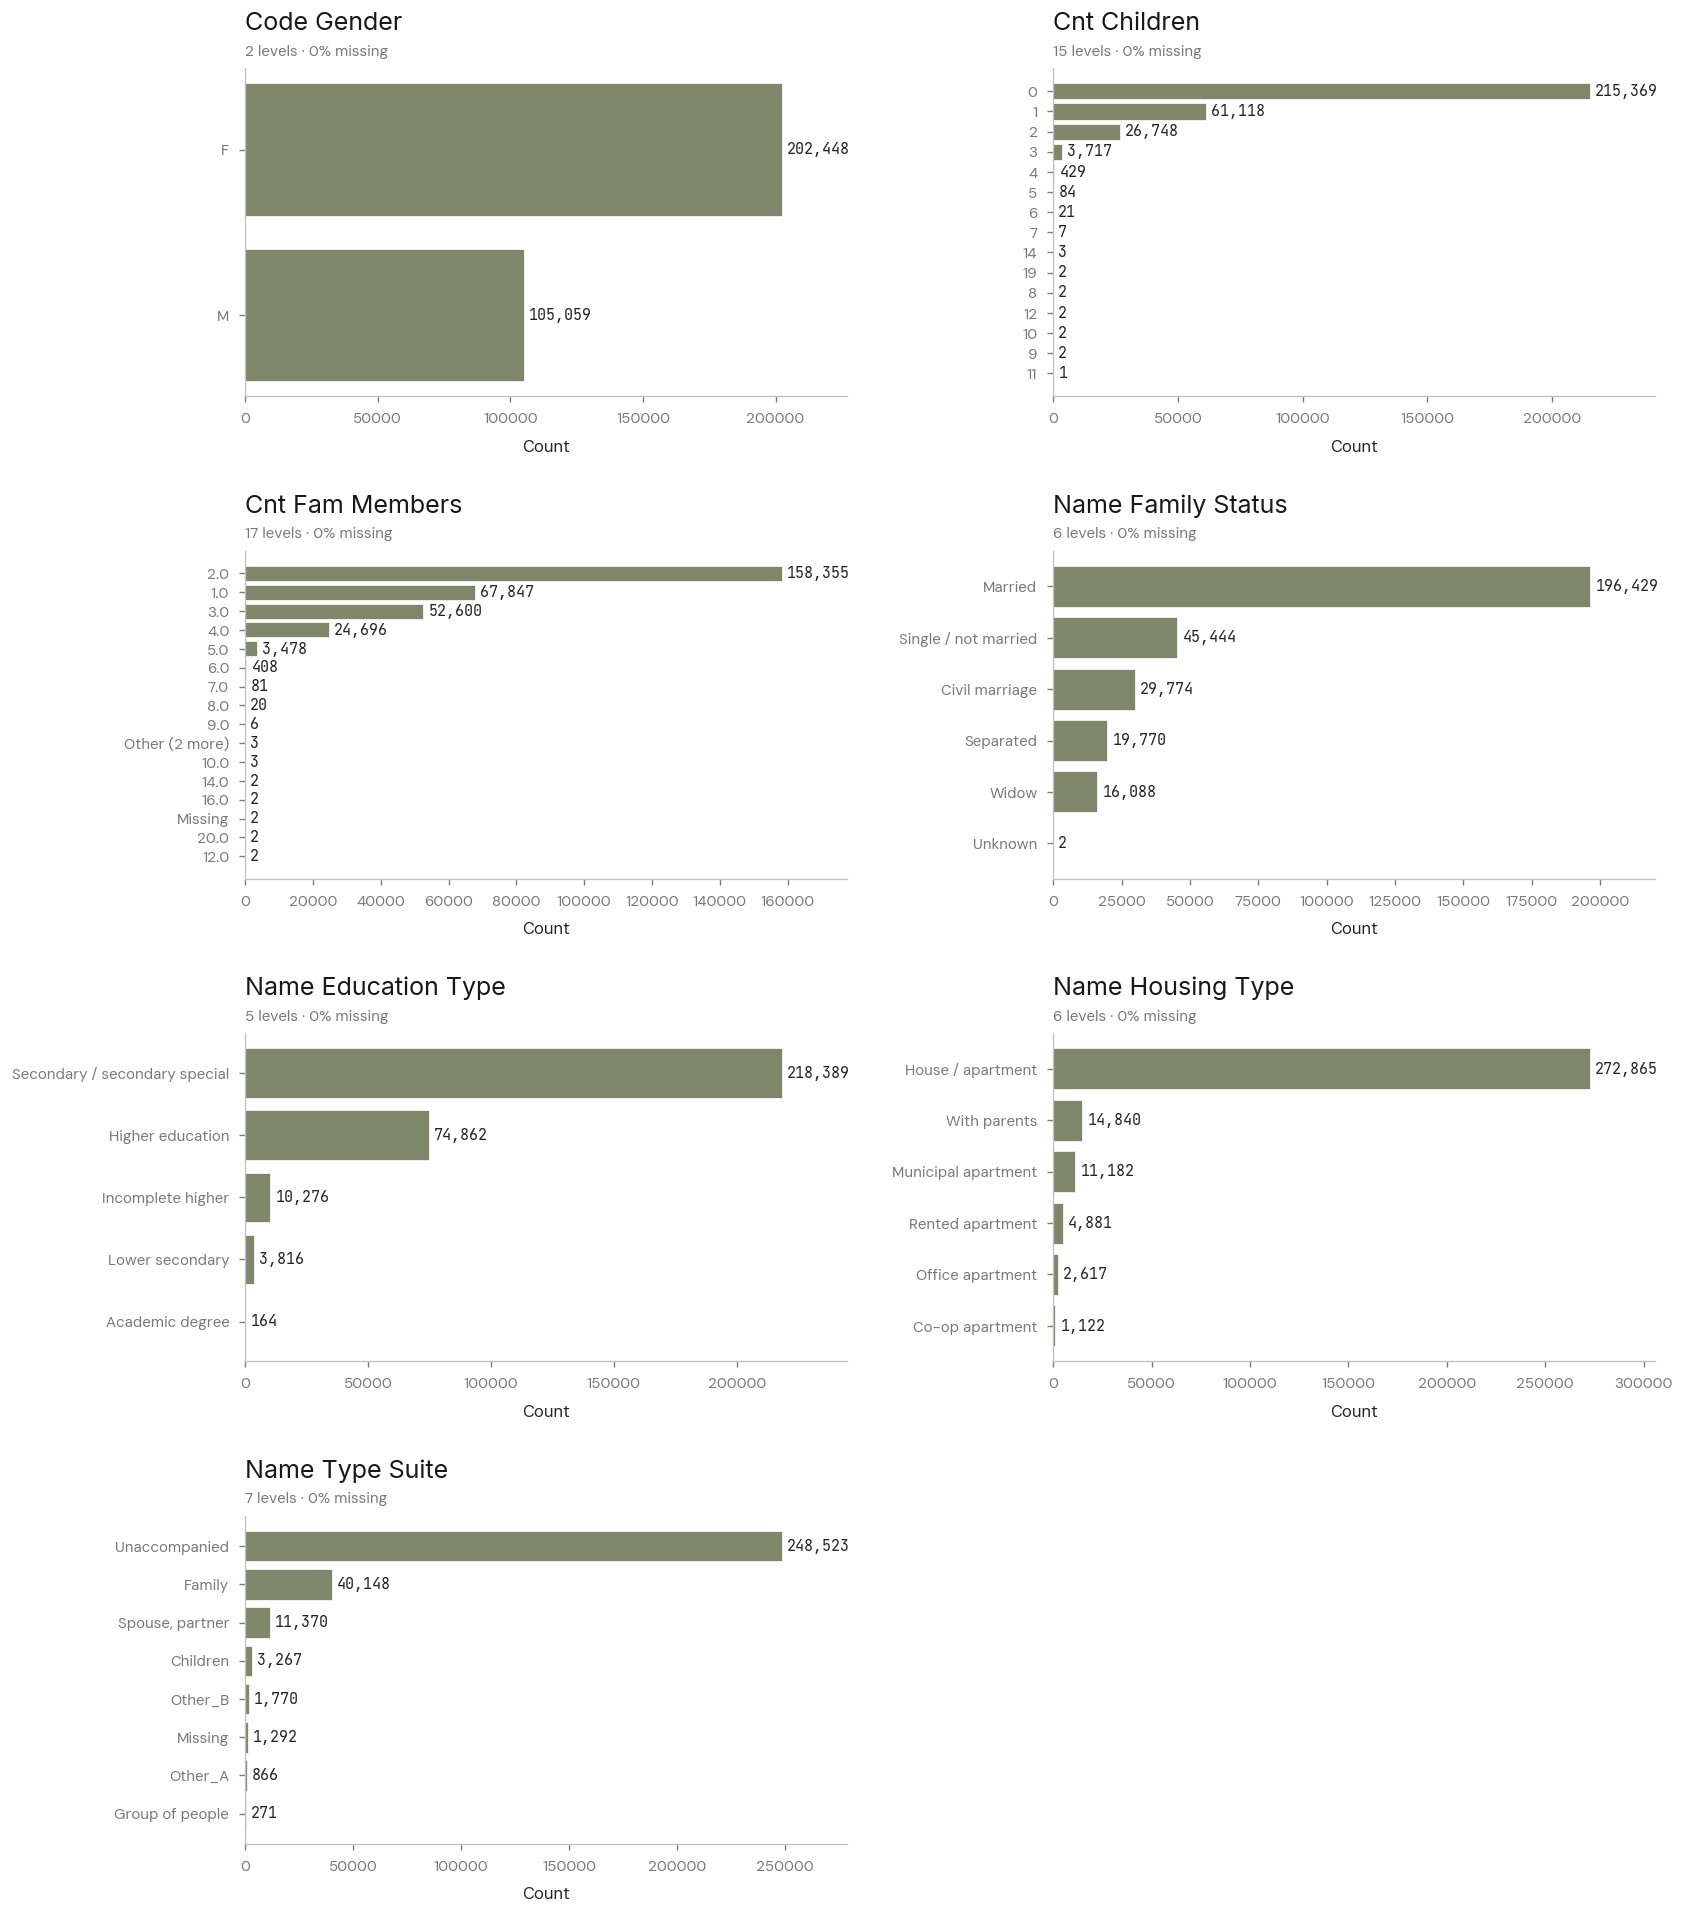

In [55]:
# Key Demographic Categorical Bar Counts

# Get 'CNT_FAM_MEMBERS' and 'CNT_CHILDREN' into separate df and convert to string

df_cat = df.copy()

convert_cat_cols = ['CNT_FAM_MEMBERS', 'CNT_CHILDREN']

df_cat[convert_cat_cols] = df[convert_cat_cols].astype(str)

cols_of_interest = cols_by_theme['demographics']

eda.frequency_per_group(df_cat, cols_of_interest, color=C.tertiary)

plt.show()

**Observation.** Most demographic categoricals have low to moderate cardinality. CODE_GENDER is binary (F ~66%, M ~34% after dropping XNA). NAME_EDUCATION_TYPE has 5 ordered levels, NAME_FAMILY_STATUS 6 (including a single 'Unknown'), NAME_HOUSING_TYPE 6, and NAME_TYPE_SUITE 7 (some sparse, ~0.4% missing). CNT_CHILDREN and CNT_FAM_MEMBERS are counts with long thin tails (rare high counts). The rest are effectively complete.

#### Bivariate Analysis

Default rate per level for each demographic variable, against the base rate (dashed line).

In [56]:
cols_by_theme['demographics']

['CODE_GENDER',
 'DAYS_BIRTH',
 'CNT_CHILDREN',
 'CNT_FAM_MEMBERS',
 'NAME_FAMILY_STATUS',
 'NAME_EDUCATION_TYPE',
 'NAME_HOUSING_TYPE',
 'NAME_TYPE_SUITE']

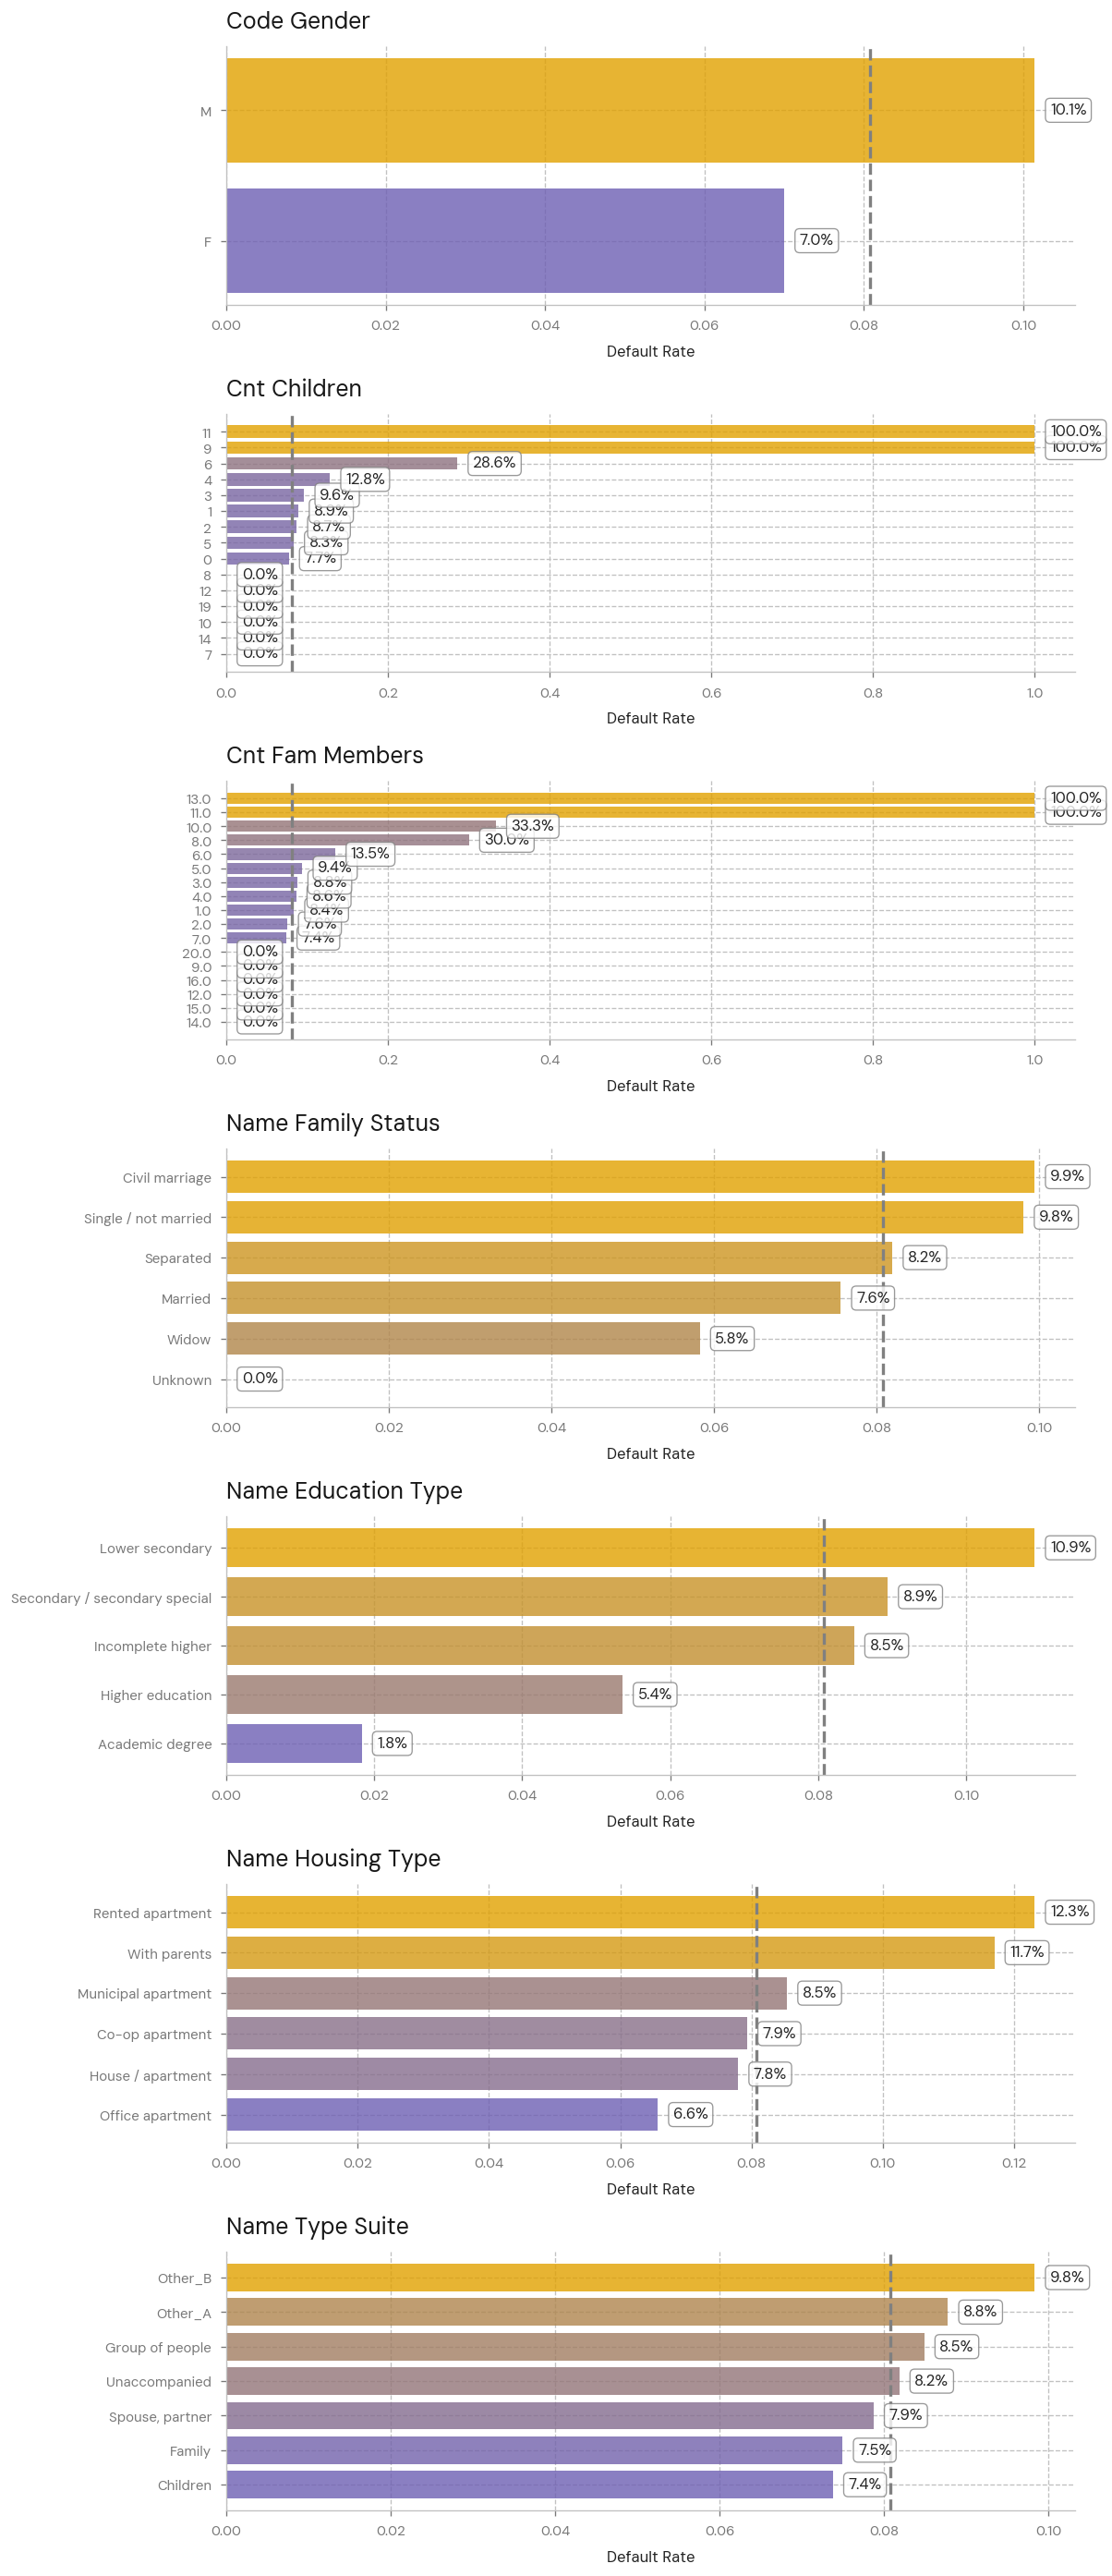

In [57]:
# Key Demographics Default Rate by Category

cols_of_interest = cols_by_theme['demographics']
cols_of_interest = [c for c in cols_of_interest if c != 'DAYS_BIRTH']


base = df['TARGET'].mean()

length = sum(df[col].nunique() for col in cols_of_interest)

fig, axes = plt.subplots(nrows=len(cols_of_interest), ncols=1,
                         figsize=(10, 0.4 * length))
axes = np.atleast_1d(axes).flatten()

cmap_occupation = risk_cmap()

for ax, col in zip(axes, cols_of_interest):
    rate = df.groupby(col, observed=True)['TARGET'].mean().sort_values()

    norm = colors.Normalize(vmin=rate.min(), vmax=rate.max())
    rgba = cmap_occupation(norm(rate.values))
    rgba[:, 3] = 0.8

    bars_1 = ax.barh(rate.index.astype(str), rate.values, color=rgba)
    ax.axvline(base, ls='--', color='grey')
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('Default Rate')
    
    ax.bar_label(bars_1,
             padding=10,
             fmt='{:.1%}',
             bbox=dict(
                 boxstyle='round',
                 facecolor='white',
                 edgecolor='grey',
                 alpha = 0.8,
                 linewidth=0.8
             ))

plt.show()

**Observation / Decision.** Default rate per level:
- CODE_GENDER: F 7.0%, M 10.1%
- NAME_EDUCATION_TYPE: a clean ordered gradient, from Academic degree 1.8% to Lower secondary 10.9%
- NAME_FAMILY_STATUS: Widow ~5.8% up to Single / Civil marriage ~9.9%
- NAME_HOUSING_TYPE: ~6.6% up to ~12.3% (with parents and rented highest)
- NAME_TYPE_SUITE: narrow range (7.4-9.8%), weak
- CNT_CHILDREN / CNT_FAM_MEMBERS: rise gently, then a noisy 100% / 0% tail from levels with only 1-2 applicants

**Decision:**
- CODE_GENDER: **exclude from the model**. It is a protected attribute (responsible lending and anti-discrimination). Document the exclusion, check retained drivers for gender proxies, and keep it as EDA context only.
- NAME_EDUCATION_TYPE: **ordinal** WOE in education order (expect monotonic WOE). Merge the sparse Academic degree level up if needed. Expected to be a strong driver.
- NAME_FAMILY_STATUS / NAME_HOUSING_TYPE: nominal WOE, pooling sparse levels (e.g. the single 'Unknown').
- CNT_CHILDREN / CNT_FAM_MEMBERS: cap the tail into a '5+' band. The two overlap (children are counted in family members), so keep one and drop the other at feature selection.
- NAME_TYPE_SUITE: weak and likely low IV, so a candidate to drop. Carry to Section 5.

### 3.5 Other Numericals

**Explanation.** The remaining numeric families (`client_timeline`, `social_circle`, `bureau_enquiries`) get a lighter touch: confirm their shape and flag anything odd, given the block-wise missing values already found in 2.3.

#### Univariate Analysis

Summary stats and histograms for the client timeline, social circle and bureau enquiry columns.

,count,mean,std,min,50%,max
DAYS_REGISTRATION,307507.00,-4986.13,3522.88,-24672.00,-4504.00,0.00
DAYS_ID_PUBLISH,307507.00,-2994.20,1509.45,-7197.00,-3254.00,0.00
DAYS_LAST_PHONE_CHANGE,307506.00,-962.86,826.81,-4292.00,-757.00,0.00
OBS_30_CNT_SOCIAL_CIRCLE,306486.00,1.42,2.40,0.00,0.00,348.00
DEF_30_CNT_SOCIAL_CIRCLE,306486.00,0.14,0.45,0.00,0.00,34.00
OBS_60_CNT_SOCIAL_CIRCLE,306486.00,1.41,2.38,0.00,0.00,344.00
DEF_60_CNT_SOCIAL_CIRCLE,306486.00,0.10,0.36,0.00,0.00,24.00
AMT_REQ_CREDIT_BUREAU_HOUR,265988.00,0.01,0.08,0.00,0.00,4.00
AMT_REQ_CREDIT_BUREAU_DAY,265988.00,0.01,0.11,0.00,0.00,9.00
AMT_REQ_CREDIT_BUREAU_WEEK,265988.00,0.03,0.20,0.00,0.00,8.00


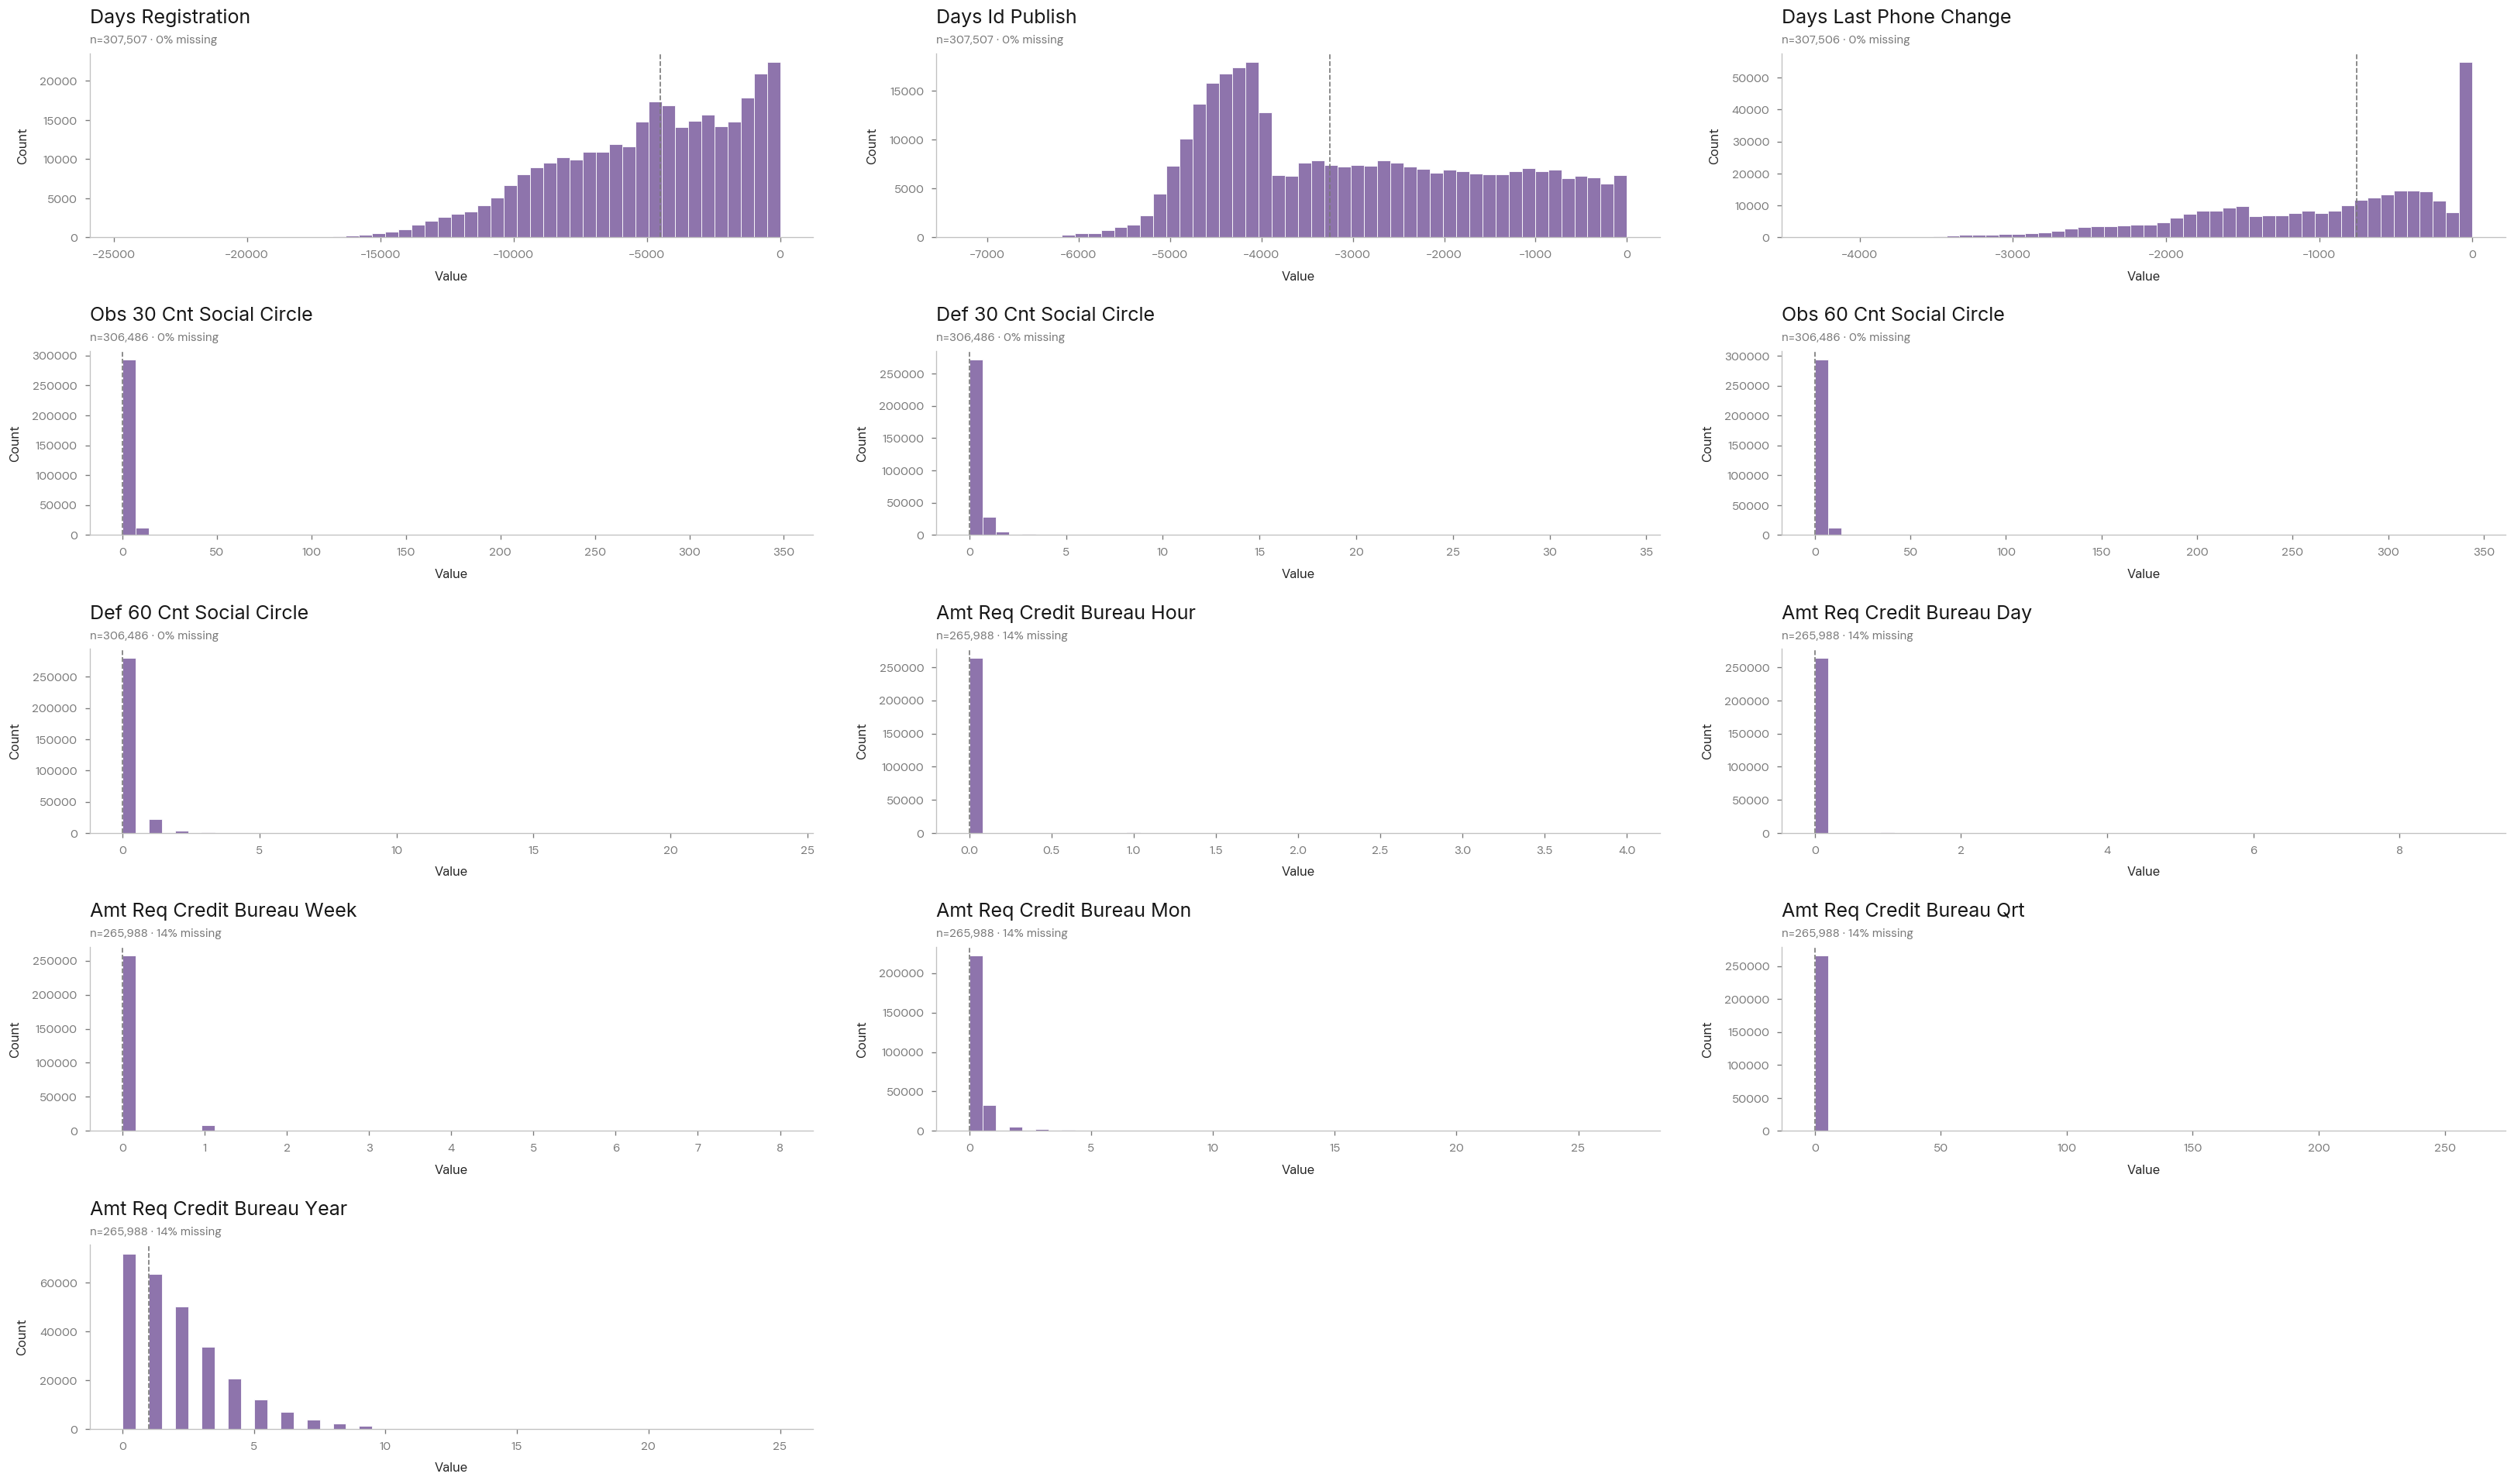

In [58]:
# Remaining numeric families
other_num = (cols_by_theme['client_timeline']
             + cols_by_theme['social_circle']
             + cols_by_theme['bureau_enquiries'])

# Shape and missingness
display(df[other_num].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

fig, axes = eda.histogram_per_group(df, other_num, ncols=3, bins=50)
plt.show()

**Observation.** The three families have distinct shapes:
- `client_timeline` (`DAYS_REGISTRATION`, `DAYS_ID_PUBLISH`, `DAYS_LAST_PHONE_CHANGE`): smooth, fully populated, and skewed toward recent events with a long tail into the past.
- `social_circle` (`OBS/DEF_30/60_CNT_SOCIAL_CIRCLE`): mostly zeros (most applicants have no defaulters in their circle), ~0.3% missing.
- `bureau_enquiries` (`AMT_REQ_CREDIT_BUREAU_*`): also mostly zeros, with all six columns missing together in one ~14% block (see 2.3).

#### Bivariate Analysis

Default rate across decile bins for each column, with missing values as their own bin.

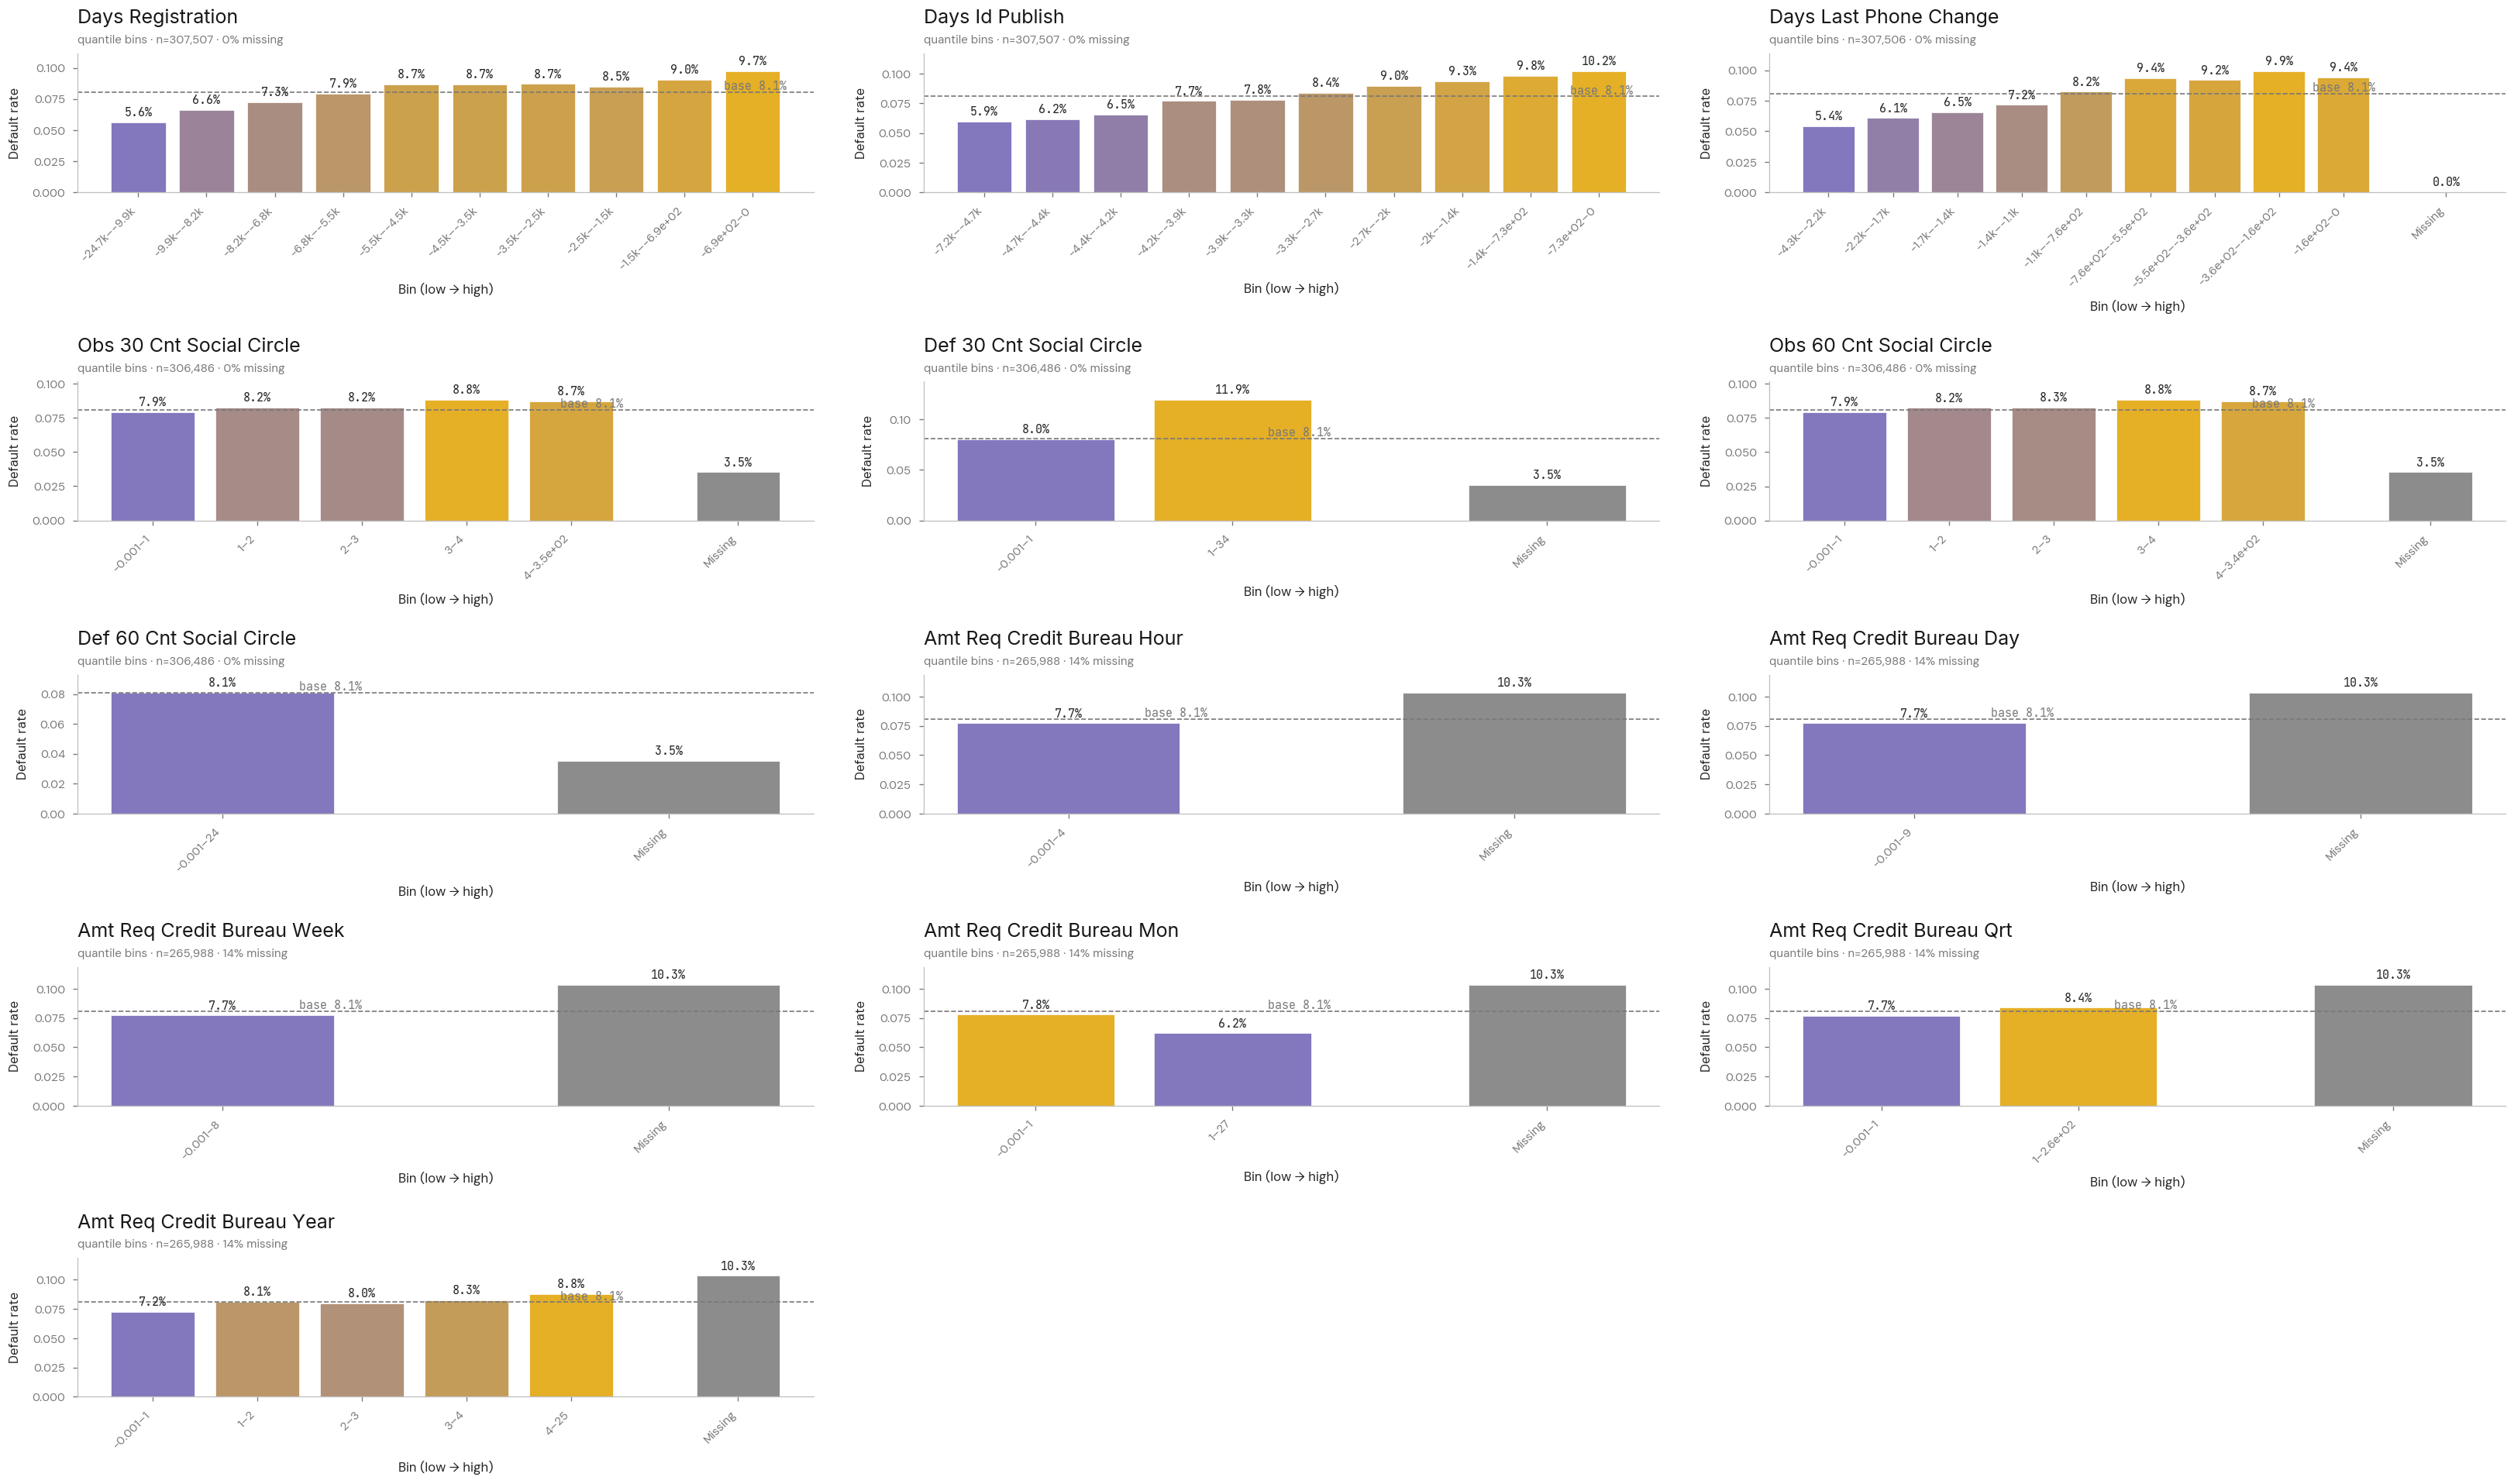

In [59]:
# Default rate by bin (missing as own bin)
from credit_utils.eda import default_rate_by_bin

fig, axes = default_rate_by_bin(
    df, other_num, target='TARGET', ncols=3, bins=10, na_as_bin=True, grade_scale=risk_cmap()
)
plt.show()

**Observation.** Only `client_timeline` shows a usable gradient. Default rises almost steadily across the bins for all three columns (e.g. `DAYS_LAST_PHONE_CHANGE` goes from 5.4% to 9.9%, so a more recent phone change reads as higher risk), and all three are fully populated. `social_circle` is essentially flat around the 8.1% base (the coarse `DEF_30` split reaches 11.9%, but on very few applicants). `bureau_enquiries` also sits near the base rate. The one interesting effect is the **missing block**: the ~14% with no bureau enquiry record default at ~10.3% vs 8.1%, so the fact that the data is missing says more than the counts do.

**Decision.**
- **Keep and bin (baseline):** the three `client_timeline` columns. Weak but real signal (indicative IV ≈ 0.03-0.04), fully populated, binned in §5.
- **Park (left out of the baseline, logged in §7):** all `social_circle` and `bureau_enquiries` columns. Indicative IV is below 0.02, under the Siddiqi keep threshold. This is reversible with a one-line change to the §5 feature list.
- **Idea for tuning:** a `has_bureau_enquiry_data` missing flag. The missing block (10.3% default) predicts better than the raw counts, so a flag may earn a place where the counts don't.

## 4. Feature Engineering

**Purpose.** Build a small set of credit ratios that pull together signal the raw `AMT_*` and `DAYS_*` columns only carry loosely, so they can enter the Section 5 WOE/IV screen as candidates in their own right. The scope is deliberately tight: a handful of ratios, each with a clear reason, not a search through every possible ratio.

**Why before the screen.** WOE/IV can only rank features that exist when it runs. Building the ratios here lets the Section 5 IV table compare them with the raw features on the same footing.

**Leakage note.** These are row-by-row calculations on existing columns, so creating them on the full data is not leakage. The train-only rule still applies later: bins and WOE are fit on the training split in Section 5, not here.

### 4.1 Candidate Ratios

**Explanation.** Five ratios, each with a standard credit reason:

| Feature | Definition | Reads as |
|---|---|---|
| `DTI` | `AMT_ANNUITY / AMT_INCOME_TOTAL` | debt service to income: can they afford the repayment |
| `CREDIT_INCOME` | `AMT_CREDIT / AMT_INCOME_TOTAL` | loan size relative to income (leverage) |
| `ANNUITY_CREDIT` | `AMT_ANNUITY / AMT_CREDIT` | payment intensity, a proxy for term / burden |
| `CREDIT_GOODS` | `AMT_CREDIT / AMT_GOODS_PRICE` | loan-to-value proxy: how much is financed above the good's price |
| `EMPLOYED_AGE` | `DAYS_EMPLOYED / DAYS_BIRTH` | share of life employed (job stability) |

`DAYS_EMPLOYED` already has the `365243` sentinel replaced with `NaN` (§2.3), so `EMPLOYED_AGE` is `NaN` for pensioners and unemployed. That group is kept as its own bin in Section 5 rather than imputed.

In [60]:
import numpy as np

# Division that returns NaN on a zero denominator
def _safe_div(num, den):
    return num / den.replace(0, np.nan)

engineered_ratios = {
    'DTI'            : _safe_div(df['AMT_ANNUITY'],   df['AMT_INCOME_TOTAL']),
    'CREDIT_INCOME'  : _safe_div(df['AMT_CREDIT'],    df['AMT_INCOME_TOTAL']),
    'ANNUITY_CREDIT' : _safe_div(df['AMT_ANNUITY'],   df['AMT_CREDIT']),
    'CREDIT_GOODS'   : _safe_div(df['AMT_CREDIT'],    df['AMT_GOODS_PRICE']),
    'EMPLOYED_AGE'   : _safe_div(df['DAYS_EMPLOYED'], df['DAYS_BIRTH']),
}

# Add ratios to df
for _name, _series in engineered_ratios.items():
    df[_name] = _series

ratio_cols = list(engineered_ratios)          # feeds the Section 5 screen
df[ratio_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
DTI,307495.00,0.18,0.09,0.00,0.11,0.16,0.23,1.88
CREDIT_INCOME,307507.00,3.96,2.69,0.00,2.02,3.27,5.16,84.74
ANNUITY_CREDIT,307495.00,0.05,0.02,0.02,0.04,0.05,0.06,0.12
CREDIT_GOODS,307229.00,1.12,0.12,0.15,1.00,1.12,1.20,6.00
EMPLOYED_AGE,252133.00,0.16,0.13,-0.00,0.06,0.12,0.22,0.73


**Observation.** The five ratios behave as their definitions suggest:
- `DTI`: median ~0.16, thin tail to ~1.9.
- `CREDIT_INCOME`: median ~3.3, long right tail to ~85 (a few very high-leverage applications).
- `ANNUITY_CREDIT`: tight range (0.02-0.12), a term / burden band.
- `CREDIT_GOODS`: median 1.12, so most loans finance at or slightly above the good's price, with a tail to ~6.
- `EMPLOYED_AGE`: spans 0-0.73 and is **18% NaN**, the pensioner / unemployed sentinel group (§2.3), kept as its own bin rather than imputed.

`CREDIT_GOODS` is only ~0.1% NaN, and the income and annuity ratios are effectively fully populated.

**Decision.** Screen all five. The long right tails (`CREDIT_INCOME`, `CREDIT_GOODS`) don't need clipping for the screen, because extreme values just land in the top bin (see 4.3). `EMPLOYED_AGE`'s NaN carries information, so it stays as its own bin (see 4.4).

### 4.2 Bivariate Sanity Check

**Task.** Default rate by bin for each engineered ratio, to confirm each one separates defaulters before it goes into the Section 5 WOE/IV screen. Read each bin's rate against the ~8% base rate.

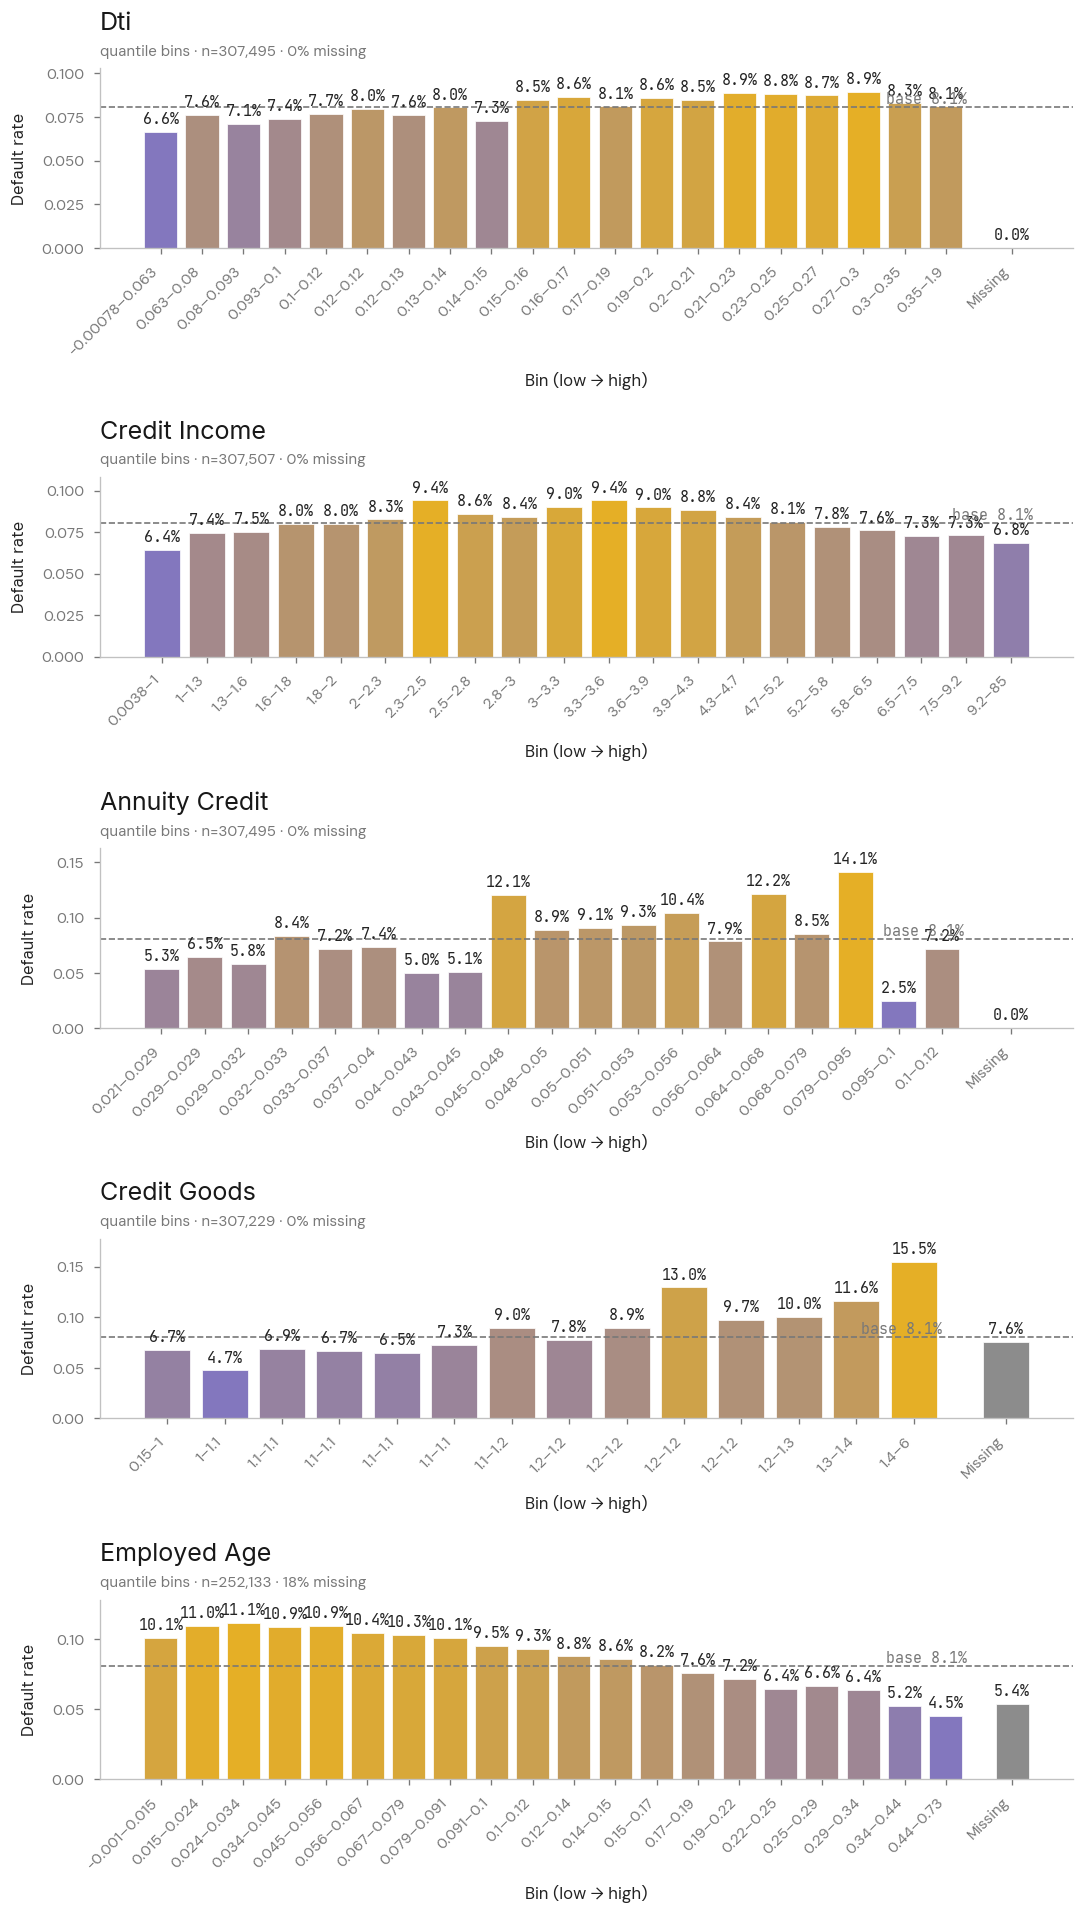

In [61]:
# Default rate by bin for each ratio
from credit_utils.eda import default_rate_by_bin

fig, axes = default_rate_by_bin(
    df, ratio_cols, target='TARGET', ncols=1, bins=20, na_as_bin=True, grade_scale=risk_cmap()
)
plt.show()

**Observation.** Two ratios show clean gradients, close to monotonic. `EMPLOYED_AGE` falls from 11% to 4.5% as the share of life employed rises (job stability), and its NaN / pensioner bin is low risk at 5.4%. `CREDIT_GOODS` rises from 6.5% to 15.5% once the loan-to-value proxy passes ~1.2. `ANNUITY_CREDIT` has real signal but isn't monotonic: it spikes to 12-14% in the highest payment-intensity bins. The two **income-based** ratios are flat: `DTI` and `CREDIT_INCOME` stay near the 8.1% base in every bin.

**Decision.**
- **Screen all five**, binned in §5. `EMPLOYED_AGE`, `CREDIT_GOODS` and `ANNUITY_CREDIT` are the expected keepers (indicative IV ≈ 0.07-0.09). `DTI` and `CREDIT_INCOME` stay in **on purpose despite weak signal**, so the IV table records that income-based affordability ratios underperform here.
- **A real finding.** `DTI`, the textbook serviceability / NSR measure, is the *weakest* ratio. The likely cause is that `AMT_INCOME_TOTAL` is self-reported and noisy in this dataset, so any ratio divided by income picks up that noise. The affordability signal sits instead in the credit-based ratios (`ANNUITY_CREDIT` for term / burden, `CREDIT_GOODS` for LTV) and in tenure (`EMPLOYED_AGE`). Worth raising in §6 and on the caveats slide.
- **Overlap to resolve at selection.** `CREDIT_GOODS` (IV ≈ 0.07) doesn't beat raw `AMT_GOODS_PRICE` (IV ≈ 0.09), and `AMT_CREDIT` ≈ `AMT_GOODS_PRICE`. Send **both** `CREDIT_GOODS` and raw `AMT_GOODS_PRICE` into the §5 screen and let feature selection drop the redundant one.

### 4.3 Outlier & Skew Treatment

**Decision: no winsorising for the screen.** The engineered ratios have long right tails (`CREDIT_INCOME` to ~85, `CREDIT_GOODS` to ~6, `DTI` to ~1.9). But Section 5 bins every feature using cut-points, so an extreme value just lands in the top bin. Clipping would move a few rows between bins at the edges without really changing the WOE/IV screen.

**Parked for later tuning.** If a later model uses the ratios as *raw continuous* inputs (e.g. a gradient-boosted model without WOE, or a scorecard variant), revisit capping at the 1st-99th percentile, because the tails would matter there.

### 4.4 Missing-Values Handling

No imputation for the screen. Missing values either carry information (kept as their own bin) or are negligible.

| Feature | Missing | Treatment |
|---|---|---|
| `EMPLOYED_AGE` | 18% | Own bin. The NaN group is the pensioner / unemployed sentinel (§2.3) and is low risk (5.4% default), so it carries information and isn't imputed. |
| `CREDIT_GOODS` | ~0.1% | Own bin (tiny group where `AMT_GOODS_PRICE` is missing). |
| `DTI`, `CREDIT_INCOME`, `ANNUITY_CREDIT` | 0% | None needed. |

WOE encoding in §5 treats each Missing bin like any other bin, so a feature with informative missing values keeps that signal instead of being dropped or mean-imputed.

## 5. WOE/IV Computation

**Purpose.** Turn the Section 3 binning decisions into two things: a ranking of *which* features drive default (**Information Value**), and model-ready **Weight of Evidence** encodings of those features. IV answers "how predictive is it?"; WOE is the form a scorecard or logistic regression uses.

**Approach.** Use `optbinning`, the standard Python library for scorecard binning. Learn it on single features first (5.2), then scale up to the full feature set with `BinningProcess` (5.3-5.5). Bins and WOE values are fit on the **training split only** and applied to the held-out split, because fitting on the full data leaks the target.

**Leakage guards.**
- Exclude ID columns (`SK_ID_CURR`) before ranking. A unique key gives a fake, near-infinite IV.
- Carry the Section 3 Decisions (transforms, missing as its own bin) into the binning here rather than deciding again.

Rhythm: **Predict, Task, Decision**, with each Decision pointing forward to preprocessing and modelling.

### 5.1 Split & Binning Inputs

**Task.** Split the data 80/20 into train and test, stratified on `TARGET` so both keep the ~8.1% default rate. Everything after this is fit on train and applied to test.

In [62]:
from sklearn.model_selection import train_test_split

# Stratified 80/20 split
train, test = train_test_split(df, test_size=0.2, train_size=0.8, random_state=42, stratify=df["TARGET"])

#### ORG_BAND

**Explanation.** Rebuilds the organisation-type banding from 2.4, this time learning the bands from the train split only. Each organisation type is banded by its train default rate (<6%, 6-8%, 8-10%, >10%), large high-risk types (over 10% default and at least 500 applicants) keep their own level, and the map is then applied to both splits. Any organisation type not seen in train falls into the base 8-10% band. Learning the bands on train means the test split's outcomes never shape the feature.

In [63]:
# ORG_BAND

def fit_org_bands(train_df, col='ORGANIZATION_TYPE', target='TARGET',
                  edges=(0, 0.06, 0.08, 0.10, 1.0),
                  labels=('<6%', '6-8%', '8-10%', '>10%'),
                  keep_solo_min_count=500, solo_rate=0.10):
    """Learn an org -> band map from the train split."""
    rate   = train_df.groupby(col)[target].mean()
    counts = train_df[col].value_counts()
    band = pd.cut(rate, bins=list(edges), labels=list(labels)).astype('object')
    hi = (rate > solo_rate) & (counts >= keep_solo_min_count)   # big high-risk levels stay solo
    band[hi] = rate.index[hi]
    return band.to_dict()

org_band_map = fit_org_bands(train)

# Apply to both splits (unseen orgs -> base band)
BASE_BAND = '8-10%'
train['ORG_BAND'] = train['ORGANIZATION_TYPE'].map(org_band_map).fillna(BASE_BAND)
test['ORG_BAND']  = test['ORGANIZATION_TYPE'].map(org_band_map).fillna(BASE_BAND)

print("ORG_BAND levels (train):", train['ORG_BAND'].nunique())
train['ORG_BAND'].value_counts()

ORG_BAND levels (train): 13


ORG_BAND
8-10%                84802
<6%                  61965
6-8%                 49195
Self-employed        30771
Construction          5408
Trade: type 3         2786
Industry: type 3      2603
Security              2595
Agriculture           1997
Restaurant            1480
Transport: type 3      951
Industry: type 1       844
>10%                   608
Name: count, dtype: int64

### 5.2 Testing `optbinning`: Single-Feature Binning

**Task.** Get comfortable with `OptimalBinning` on one feature at a time before scaling up. Fit on train only.

1. **Numeric feature**: `EXT_SOURCE_3`: fit, build the binning table, plot WoE. Read every column (Count, Event rate, WoE, IV).
2. **Parameters**: change one at a time (`monotonic_trend`, `min_bin_size`, `max_n_bins`) and note how the bins and IV move.
3. **Categorical feature**: `NAME_INCOME_TYPE` (`dtype='categorical'`): see how levels are grouped by default rate.

**Sign check.** WoE = ln(%non-events / %events) so negative WoE = riskier than average. The row with the highest event rate should carry the most negative WoE.

IV rule of thumb (Siddiqi): <0.02 unpredictive · 0.02–0.1 weak · 0.1–0.3 medium · 0.3–0.5 strong · >0.5 suspiciously strong, check for leakage.

**Predict:** _ There should be <20 bins given that there cannot be less tha, by nature of the scroe should be monotonic, and the missing bin would be riskier as it would indicate that person has not taken out credit or no one was willing to lend to them and the diddnt generate a score._

**Observation:** _<fill after running>_

**Decision:** _<binning settings to carry into BinningProcess in 5.3>_

,name,'EXT_SOURCE_3'
,dtype,'numerical'
,prebinning_method,'cart'
,solver,'cp'
,divergence,'iv'
,max_n_prebins,20
,min_prebin_size,0.05
,min_n_bins,None
,max_n_bins,None
,min_bin_size,None
,max_bin_size,None


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.18)",12395,0.05,9676,2719,0.22,-1.16,0.11,0.01
1,"[0.18, 0.32)",23905,0.10,20515,3390,0.14,-0.63,0.05,0.01
2,"[0.32, 0.37)",12344,0.05,11099,1245,0.10,-0.24,0.00,0.00
3,"[0.37, 0.41)",12511,0.05,11320,1191,0.10,-0.18,0.00,0.00
4,"[0.41, 0.46)",13014,0.05,11984,1030,0.08,0.02,0.00,0.00
5,"[0.46, 0.50)",13806,0.06,12827,979,0.07,0.14,0.00,0.00
6,"[0.50, 0.57)",23458,0.10,22085,1373,0.06,0.35,0.01,0.00
7,"[0.57, 0.61)",13695,0.06,13034,661,0.05,0.55,0.01,0.00
8,"[0.61, 0.65)",14970,0.06,14280,690,0.05,0.60,0.02,0.00
9,"[0.65, 0.70)",20971,0.09,20117,854,0.04,0.73,0.03,0.00


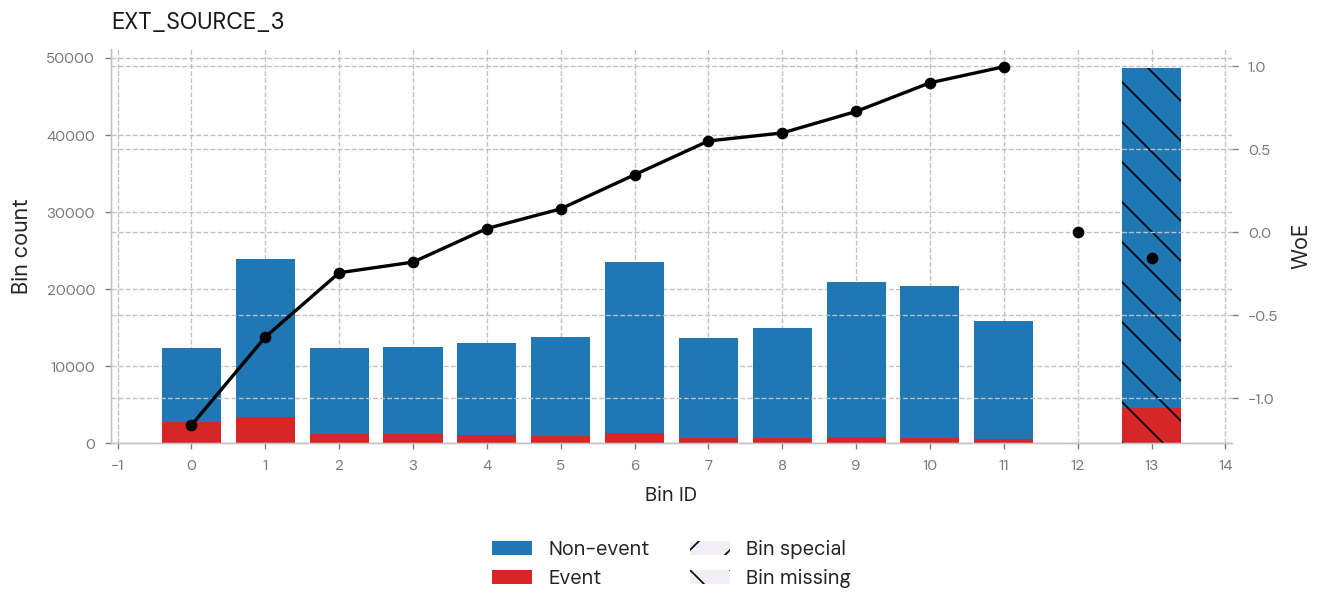

In [64]:
# 5.2 Step 1 — OptimalBinning on EXT_SOURCE_3

from optbinning import OptimalBinning

col = 'EXT_SOURCE_3'
ob = OptimalBinning(name=col, dtype='numerical')   # 'categorical' for string features
ob.fit(train[col], train['TARGET'])                # fit on train only

tbl = ob.binning_table.build()                     # the row-by-row WOE/IV table
display(tbl)
ob.binning_table.plot(metric='woe')                # bars = counts, line = WoE per bin

### 5.3 IV Across All Features

**Task.** Fit `BinningProcess` on train across all candidate features and use `.summary()` to build an IV table sorted from high to low. The feature list below sets out what goes in. This is the cross-feature ranking that used to live in the old "Target Relationship Scan".

**Observation:** The IV ranking drops off sharply after the top two features (EXT_SOURCE_2, EXT_SOURCE_3), and again after the fifth-ranked engineered ratio into the weak Siddiqi band. No feature exceeds an IV of 0.5, so there is no signal of gross leakage or an artefact by that threshold alone. That said, no dedicated train-vs-test IV/Gini stability check has been run to confirm this further; flagged as a follow-up for model tuning.

#### Feature List

**Explanation.** Rather than dropping columns from `train`, build a list of the columns to bin. The data stays whole, and every exclusion is logged with a reason for §8.

| Step | Columns | Reason |
|---|---|---|
| Exclude | `SK_ID_CURR`, `TARGET` | ID and target, not features |
| Exclude | `ORGANIZATION_TYPE` | Replaced by `ORG_BAND` (§5.1) |
| Exclude | `CODE_GENDER` | Protected attribute (§3.4) |
| Exclude | building_stats `_MEDI` / `_MODE` | Same information as the `_AVG` version (§2.3). Only dropped when an `_AVG` twin exists, so MODE-only columns like `HOUSETYPE_MODE` are kept |
| Exclude | `social_circle`, `bureau_enquiries` | Parked in §3.5 (indicative IV below 0.02). Remove this line to add them back |
| Categorical | strings, bools, codes typed 'categorical' in §2.1 | e.g. `ORG_BAND`, `DAYS_EMPLOYED_SENTINEL`, `HOUR_APPR_PROCESS_START` |
| Check | `ratio_cols`, `ORG_BAND` | Created after the §2.1 index, so confirm they are in the list |

Expected: 129 columns in train, 42 excluded, 87 features.

In [65]:
# 5.3 Feature list

exclusions = {
    'SK_ID_CURR':        'ID, not a feature',
    'TARGET':            'Target',
    'ORGANIZATION_TYPE': 'Replaced by ORG_BAND (5.1)',
    'CODE_GENDER':       'Protected attribute (3.4)',
}

# Building stats - keep _AVG, drop _MEDI/_MODE twins
for col in cols_by_theme['building_stats']:
    for suffix in ('_MEDI', '_MODE'):
        twin = col.removesuffix(suffix) + '_AVG'
        if col.endswith(suffix) and twin in train.columns:
            exclusions[col] = f'Duplicate of {twin} (2.3)'

# Parked in 3.5 - weak signal
for col in cols_by_theme['social_circle'] + cols_by_theme['bureau_enquiries']:
    exclusions[col] = 'Parked, weak signal (3.5)'

features = [c for c in train.columns if c not in exclusions]

# Categorical features
categorical_features = [
    c for c in features
    if not pd.api.types.is_numeric_dtype(train[c])
    or pd.api.types.is_bool_dtype(train[c])
    or statistical_type_index.get(c) == 'categorical'
]

# Check engineered features are included
assert set(ratio_cols) <= set(features)
assert 'ORG_BAND' in categorical_features

print(f"{train.shape[1]} columns -> {len(exclusions)} excluded -> {len(features)} features "
      f"({len(categorical_features)} categorical, {len(features) - len(categorical_features)} numerical)")

exclusion_log = pd.Series(exclusions, name='reason').rename_axis('column').to_frame()
exclusion_log

129 columns -> 42 excluded -> 87 features (17 categorical, 70 numerical)


,reason
column,
SK_ID_CURR,"ID, not a feature"
TARGET,Target
ORGANIZATION_TYPE,Replaced by ORG_BAND (5.1)
CODE_GENDER,Protected attribute (3.4)
APARTMENTS_MODE,Duplicate of APARTMENTS_AVG (2.3)
BASEMENTAREA_MODE,Duplicate of BASEMENTAREA_AVG (2.3)
YEARS_BEGINEXPLUATATION_MODE,Duplicate of YEARS_BEGINEXPLUATATION_AVG (2.3)
YEARS_BUILD_MODE,Duplicate of YEARS_BUILD_AVG (2.3)
COMMONAREA_MODE,Duplicate of COMMONAREA_AVG (2.3)


In [66]:
from optbinning import BinningProcess

bp = BinningProcess(
    variable_names=features,                     # which columns to bin
    categorical_variables=categorical_features,  # which of those are categorical
)
bp.fit(train[features], train['TARGET'])         # fit on train only

feature_table = bp.summary()   

feature_table.sample(5)

,variable_names,"['NAME_CONTRACT_TYPE', 'FLAG_OWN_CAR', ...]"
,max_n_prebins,20
,min_prebin_size,0.05
,min_n_bins,None
,max_n_bins,None
,min_bin_size,None
,max_bin_size,None
,max_pvalue,None
,max_pvalue_policy,'consecutive'
,selection_criteria,None
,fixed_variables,None


,name,dtype,status,selected,n_bins,iv,js,gini,quality_score
41,BASEMENTAREA_AVG,numerical,OPTIMAL,True,4,0.02,0.00,0.07,0.07
19,FLAG_MOBIL,numerical,OPTIMAL,True,1,0.00,0.00,0,0.00
8,NAME_TYPE_SUITE,categorical,OPTIMAL,True,2,0.00,0.00,0.01,0.00
0,NAME_CONTRACT_TYPE,categorical,OPTIMAL,True,2,0.02,0.00,0.03,0.02
9,NAME_INCOME_TYPE,categorical,OPTIMAL,True,4,0.06,0.01,0.12,0.20


### 5.4 Top 15 Drivers

**Task.** The payoff table: the top 15 features by IV, styled. Feeds the narrative in Section 6.

**Observation:** The top drivers are dominated by the external scores (EXT_SOURCE_1/2/3), DAYS_EMPLOYED, the engineered ratios (ANNUITY_CREDIT, EMPLOYED_AGE, CREDIT_GOODS), and a handful of demographic/organisational features (DAYS_BIRTH, OCCUPATION_TYPE, ORG_BAND, NAME_INCOME_TYPE, REGION_RATING_CLIENT_W_CITY, NAME_EDUCATION_TYPE). This agrees with the Section 3 bivariate reads: the external scores and age/employment were expected top drivers, and the affordability ratios outrank the raw loan amounts as anticipated. Within the top 20 (not carried forward), DAYS_LAST_PHONE_CHANGE and DAYS_ID_PUBLISH stand out as weaker behavioural proxies, worth a look if the feature set expands later.

**Decision:** Carry the top 15 features forward, but drop AMT_CREDIT instead of CREDIT_GOODS. AMT_CREDIT and AMT_GOODS_PRICE are near-duplicates, and both AMT_GOODS_PRICE and CREDIT_GOODS (loan amount relative to the goods price) carry more signal on their own than the raw credit amount does. This reverses the draft exclusion below; the `dropped` dict in the next cell has been updated accordingly and must be re-run so the WOE frames reflect it.

,name,dtype,status,selected,n_bins,iv,js,gini,quality_score,band
0,EXT_SOURCE_3,numerical,OPTIMAL,True,12,0.33,0.04,0.32,0.44,Strong
1,EXT_SOURCE_2,numerical,OPTIMAL,True,15,0.32,0.04,0.31,0.25,Strong
2,EXT_SOURCE_1,numerical,OPTIMAL,True,6,0.15,0.02,0.18,0.44,Medium
3,DAYS_EMPLOYED,numerical,OPTIMAL,True,9,0.12,0.01,0.19,0.32,Medium
4,ANNUITY_CREDIT,numerical,OPTIMAL,True,6,0.11,0.01,0.18,0.39,Medium
5,EMPLOYED_AGE,numerical,OPTIMAL,True,8,0.09,0.01,0.17,0.12,Weak
6,AMT_GOODS_PRICE,numerical,OPTIMAL,True,9,0.09,0.01,0.16,0.24,Weak
7,DAYS_BIRTH,numerical,OPTIMAL,True,13,0.09,0.01,0.17,0.07,Weak
8,OCCUPATION_TYPE,categorical,OPTIMAL,True,5,0.08,0.01,0.15,0.31,Weak
9,CREDIT_GOODS,numerical,OPTIMAL,True,6,0.07,0.01,0.15,0.03,Weak


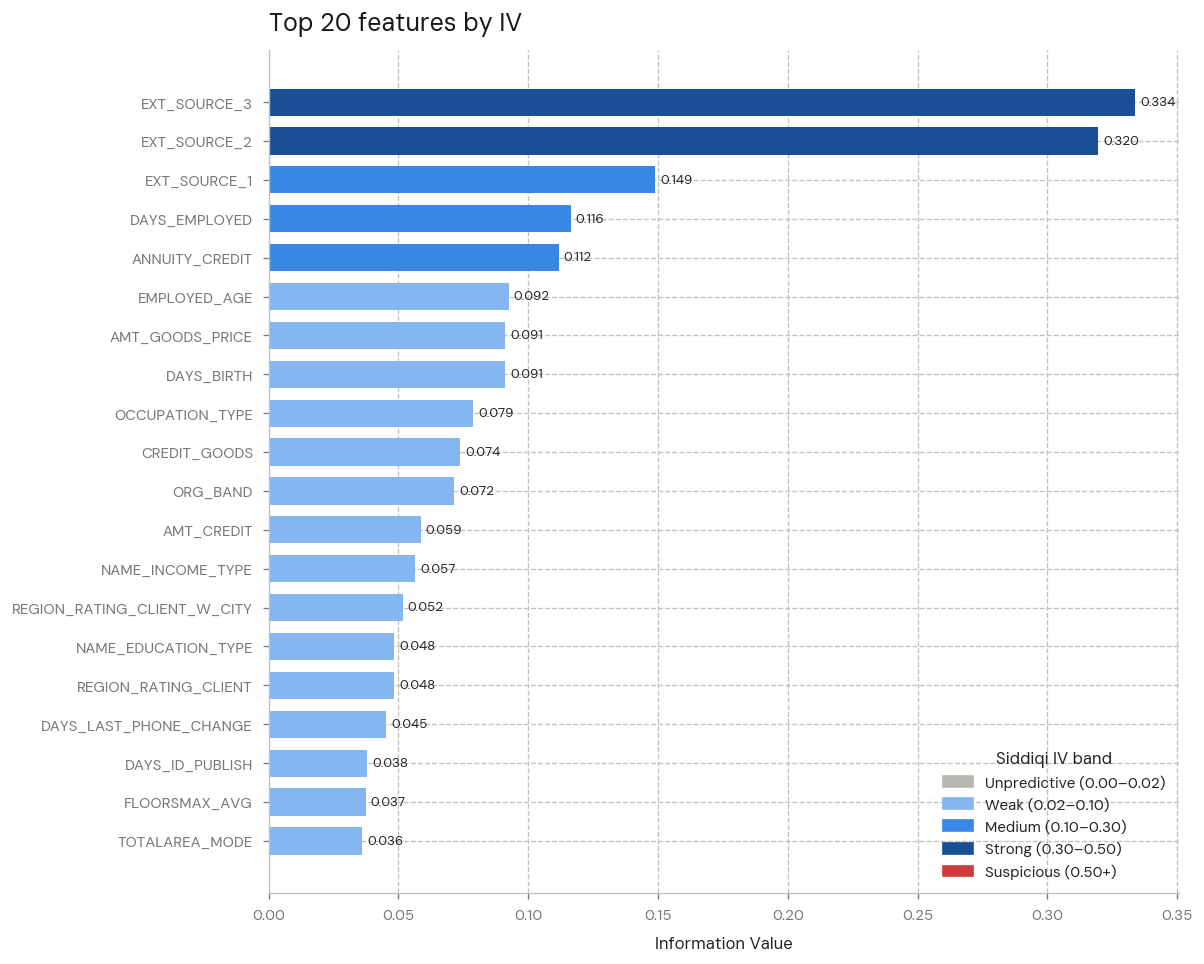

In [ ]:
from matplotlib.patches import Patch
from python_style_util import style_df

# Siddiqi IV bands - (lower, upper, colour)
IV_BANDS = {
    'Unpredictive': (0.00, 0.02,   '#b8b6b0'),
    'Weak':         (0.02, 0.10,   '#86b6ef'),
    'Medium':       (0.10, 0.30,   '#3987e5'),
    'Strong':       (0.30, 0.50,   '#184f95'),
    'Suspicious':   (0.50, np.inf, '#d03b3b'),
}
band_colours = {band: c for band, (lo, hi, c) in IV_BANDS.items()}

# Sort, then assign each feature its band
feature_table = feature_table.sort_values('iv', ascending=False).reset_index(drop=True)
edges = [lo for lo, hi, c in IV_BANDS.values()] + [np.inf]
feature_table['band'] = pd.cut(feature_table['iv'], bins=edges,
                               labels=list(IV_BANDS), right=False).astype(str)

# Top 15 table
style_df(feature_table.head(15), gradient_cols=['iv'], gradient_cmap='Purples')

# Bar chart - top 20, coloured by band
top = feature_table.head(20)

fig, ax = plt.subplots(figsize=(10, 0.35 * len(top) + 1))
bars = ax.barh(top['name'], top['iv'], color=top['band'].map(band_colours), height=0.7)
ax.invert_yaxis()                                   # highest IV on top
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)

# Legend - one entry per band, with its range
handles = [
    Patch(color=c, label=f'{band} ({lo:.2f}+)' if hi == np.inf else f'{band} ({lo:.2f}–{hi:.2f})')
    for band, (lo, hi, c) in IV_BANDS.items()
]
ax.legend(handles=handles, title='Siddiqi IV band', loc='lower right')

ax.set_xlabel('Information Value')
ax.set_title('Top 20 features by IV')
plt.show()

feature_table[['name', 'iv']].rename(columns={'name': 'feature'}).to_csv('iv_screen.csv', index=False)

In [68]:
top_feature_cols = feature_table.head(15)['name'].tolist()

print(top_feature_cols)

['EXT_SOURCE_3', 'EXT_SOURCE_2', 'EXT_SOURCE_1', 'DAYS_EMPLOYED', 'ANNUITY_CREDIT', 'EMPLOYED_AGE', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'OCCUPATION_TYPE', 'CREDIT_GOODS', 'ORG_BAND', 'AMT_CREDIT', 'NAME_INCOME_TYPE', 'REGION_RATING_CLIENT_W_CITY', 'NAME_EDUCATION_TYPE']


### 5.5 WOE Encoding

**Task.** Use the train-fit `BinningProcess` to `.transform(..., metric='woe')` both splits into WOE-encoded frames for modelling. Same rule as imputation: fit on train, then transform the held-out split without refitting.

**Decision:** Confirmed: the WOE-encoded train/test frames are the modelling input. The split is a stratified 80/20 with `random_state=42` for reproducibility. The fitted `BinningProcess` (`bp`) is the artefact that must be saved and carried into modelling and scoring, since it holds the bin edges and WOE maps fit on train only, not the WOE frames alone.

In [69]:
# Final feature set
dropped = {'AMT_CREDIT': 'Near-duplicate of AMT_GOODS_PRICE; CREDIT_GOODS (loan-to-price ratio) '
                          'and AMT_GOODS_PRICE both carry more signal alone than the raw credit amount'}
model_features = [c for c in top_feature_cols if c not in dropped]

# Transform both splits with the train-fit bp (never refit)
X_train_woe = bp.transform(train[features], metric='woe', metric_missing='empirical')[model_features]
X_test_woe  = bp.transform(test[features],  metric='woe', metric_missing='empirical')[model_features]

# Keep the original row index so X and y line up
X_train_woe.index = train.index
X_test_woe.index  = test.index

# Targets
y_train = train['TARGET']
y_test  = test['TARGET']

# Checks
X_train_woe.shape, X_test_woe.shape       # same columns, ~246k / ~61.5k rows
X_train_woe.isna().sum().sum()            # expect 0 - Missing has its own WoE
X_train_woe.nunique()                     # a handful of values per column (one per bin)


((246005, 14), (61502, 14))

np.int64(0)

EXT_SOURCE_3                   13
EXT_SOURCE_2                   16
EXT_SOURCE_1                    7
DAYS_EMPLOYED                  10
ANNUITY_CREDIT                  7
EMPLOYED_AGE                    9
AMT_GOODS_PRICE                10
DAYS_BIRTH                     13
OCCUPATION_TYPE                 6
CREDIT_GOODS                    7
ORG_BAND                        5
NAME_INCOME_TYPE                4
REGION_RATING_CLIENT_W_CITY     3
NAME_EDUCATION_TYPE             2
dtype: int64

## 6. Findings Summary

**Headline drivers.** The IV ranking drops off sharply after the top two features, then again after the engineered ratio at rank five, into the weak Siddiqi band. A significant share of the model's predictive power sits with EXT_SOURCE_2 and EXT_SOURCE_3 (IV 0.320 and 0.334), with EXT_SOURCE_1 (IV 0.149) contributing further but likely overlapping given the intercorrelation among the three scores (§3.1).

The top five drivers show a consistent pattern. The external scores and DAYS_EMPLOYED are negatively monotonic with default, so a higher score or longer tenure means lower default, though DAYS_EMPLOYED is only monotonic once the sentinel bin is set aside (see data-quality conclusions below). ANNUITY_CREDIT is positively monotonic: default risk rises as the ratio increases. This fits a serviceability read - customers taking on higher repayments relative to the credit amount they applied for are more likely to default, likely reflecting a lower NSR once those repayments are accounted for.

No feature outside the expected drivers appears in the top 15 carried into modelling. Within the top 20, DAYS_LAST_PHONE_CHANGE and DAYS_ID_PUBLISH stand out as weaker behavioural proxies: a more recent change to phone or ID details shows a mild association with higher default risk, worth revisiting if the feature set is expanded in later iterations.

No feature exceeds an IV of 0.5, which would normally be the trigger to suspect leakage or an artefact. This is consistent with correct preprocessing discipline (bins fit on train only, ORG_BAND refit on train in §5.1), though it does not on its own confirm there is no leakage. No dedicated leakage check has been run at this stage, such as comparing train vs test IV/Gini stability for the top features, or re-deriving DAYS_EMPLOYED's IV with the sentinel bin isolated to see how much of its signal is really a pensioner effect. Flagged as a follow-up for model tuning.

**Data-quality conclusions.** The DAYS_EMPLOYED sentinel (365243) was recoded to missing and treated as its own bin. This reflects a structural, informative missingness mechanism: a missing value here plausibly indicates either unemployment or retirement, and is a likely contributor to DAYS_EMPLOYED's high rank among the top drivers - part of its IV may be attributable to a pensioner effect rather than tenure itself. NAME_INCOME_TYPE is what separates the two groups within the sentinel: Pensioner defaults at around 5% while Unemployed defaults at around 37%.

Building-stats missingness is MAR, tied to dwelling type. Freestanding houses, for example, don't typically have elevators, so the missing values follow a logical pattern rather than a random one.

The bureau-enquiries and social-circle missing blocks were confirmed independent of each other (§2.3), so they have separate origins. Social circle's missingness (around 0.3% of rows) sits flat against the base rate and looks close to MCAR, not worth much narrative weight. Bureau enquiries is different: the roughly 14% of applicants with no bureau enquiry record default at around 10.3% versus the 8.1% base rate, so that missingness looks informative, closer to MNAR. However, the whole bureau_enquiries family (along with social_circle) was excluded from the §5.3 feature list as "parked, weak signal" based on the indicative IV of the raw enquiry counts - a standalone missingness indicator for bureau enquiries was never tested for IV in its own right. **Flagged for future model tuning:** build a `BUREAU_ENQUIRY_MISSING` flag and screen it directly, rather than relying on the parked count columns to carry that signal.

The four CODE_GENDER = XNA rows, out of roughly 307,000 total, were dropped in §2.3 due to their negligible sample size.

**Segment insights.** Applicant segments carrying an elevated default rate relative to the ~8.1% base rate: Maternity leave (income type, ~40% default, though on a very small sample), Unemployed (income type, ~37%, also small), 20-24 year olds (age band, 12.3%), Lower Secondary (education, 10.9%), and low-skill labourers (occupation type, ~17%).

Segments sitting well below the base rate, large enough to matter: Higher education (NAME_EDUCATION_TYPE, ~74,000 applicants, about 25% of the data, defaulting at 5.4%) and the ORG_BAND "<6%" band (61,965 applicants in the train split alone, about 25% of train). Both are large enough to be a genuine finding rather than noise, unlike the high-risk income-type segments above, which are directionally important but numerically thin.

**Modelling implications.** The final model feature set carries forward 14 features from the top 15 by IV: EXT_SOURCE_1/2/3, DAYS_EMPLOYED, ANNUITY_CREDIT, EMPLOYED_AGE, AMT_GOODS_PRICE, DAYS_BIRTH, OCCUPATION_TYPE, CREDIT_GOODS, ORG_BAND, NAME_INCOME_TYPE, REGION_RATING_CLIENT_W_CITY, and NAME_EDUCATION_TYPE. AMT_CREDIT is dropped rather than CREDIT_GOODS: AMT_CREDIT and AMT_GOODS_PRICE are near-duplicates (§5.3), and both AMT_GOODS_PRICE and CREDIT_GOODS carry more signal on their own than the raw credit amount does (see §5.4 decision, updated accordingly).

CODE_GENDER is excluded from the model. No lending or policy decision can be made on the basis of a protected attribute such as gender, in the same way ethnicity could not be used; this is a hard exclusion on responsible-lending and anti-discrimination grounds, not a weak-signal judgement call. No formal proxy check has been run against the retained features; flagged in Section 7 as a limitation.

social_circle and bureau_enquiries were parked rather than dropped outright. Their indicative IV was below the 0.02 threshold in raw form, and revisiting them in isolation is unlikely to change that; the opportunity, if pursued, is in feature engineering (for example, the bureau-enquiries missingness flag noted above) rather than in the existing columns.

Locked in for modelling: an 80/20 train/test split with `random_state=42` for reproducibility, and the fitted `BinningProcess` (`bp`) as the single source of the bin edges and WOE maps, since it must be carried into modelling and re-used for scoring rather than refit.

## 7. Assumptions, Limitations & Data Lineage

**Key assumptions.** `application_train` is treated as representative of the through-the-door population for this stage of the assessment. `TARGET` is closer to a payment-difficulty indicator than a strict default flag: it captures customers who had payment difficulties, not exclusively those who defaulted outright, so some flagged customers may be in arrears rather than in default. This EDA is scoped to the single `application_train` table only.

**Limitations & caveats.** This analysis is blind to everything outside `application_train`: it does not use the applicant's installment history, other bureau credit data, or previous application records, which may carry additional signal. This was a deliberate scope decision for a first-pass base model as a learning exercise, not an oversight, and is a clear candidate for scope expansion if the model is tuned further. No formal check has been run for proxy discrimination against the excluded CODE_GENDER attribute among the retained features. No train-vs-test IV/Gini stability check has been run to further support the leakage read in Section 6. The bureau-enquiries missingness signal was not tested for IV as a standalone flag; noted in Section 6 as a follow-up.

**Data lineage.** Source: `application_train` from the Home Credit Default Risk dataset, loaded as a single table of approximately 307,511 rows. Four rows with `CODE_GENDER` = 'XNA' were dropped in §2.3. Engineered ratio features (DTI, CREDIT_INCOME, ANNUITY_CREDIT, CREDIT_GOODS, EMPLOYED_AGE) were derived in §4.1. `ORG_BAND` and the categorical-pooling treatments were fit on the train split only (§5.1), after an 80/20 stratified split with `random_state=42`.

**Scope boundary.** This EDA stage covers screening and WOE/IV ranking only. Deferred to later stages: model fitting (logistic-regression scorecard), calibration, and out-of-time / out-of-sample validation beyond the held-out test split used here.

## 8. Handoff to Modelling

**Task.** Persist everything the modelling notebook needs so it never has to re-run this one: the WOE-encoded frames, the fitted `BinningProcess` (the source of truth for bin edges and WOE maps), the `ORGANIZATION_TYPE` → `ORG_BAND` lookup (needed to re-derive `ORG_BAND` on any new data before it can be WOE-transformed), and a small metadata record of the decisions this notebook locked in.

**Note.** `application_test` (Kaggle's unlabeled test set) is not used anywhere in this project - it has no `TARGET`, so it can't serve as a validation set. The 80/20 split below is the only labeled holdout available and is what the modelling notebook should keep using.

In [70]:
import json
import pickle
from pathlib import Path

output_dir = Path('../02_PD_Model_Development/inputs')
output_dir.mkdir(parents=True, exist_ok=True)

# 1. WOE-encoded frames (features + target together, one file per split)
train_export = X_train_woe.copy()
train_export['TARGET'] = y_train
test_export = X_test_woe.copy()
test_export['TARGET'] = y_test

train_export.to_parquet(output_dir / 'train_woe.parquet')
test_export.to_parquet(output_dir / 'test_woe.parquet')

# 2. Fitted BinningProcess - the source of the bin edges and WOE maps.
#    Must be reused (never refit) to score any new data.
with open(output_dir / 'binning_process.pkl', 'wb') as f:
    pickle.dump(bp, f)

# 3. ORGANIZATION_TYPE -> ORG_BAND lookup (bp only knows ORG_BAND's own WOE,
#    not how to derive ORG_BAND from a raw ORGANIZATION_TYPE value).
with open(output_dir / 'org_band_map.json', 'w') as f:
    json.dump(org_band_map, f, indent=2)

# 4. Metadata: the decisions this notebook locked in, so modelling doesn't
#    need to reopen this notebook to know what it inherited.
metadata = {
    'model_features': model_features,
    'train_test_split': {'test_size': 0.2, 'random_state': 42, 'stratify': 'TARGET'},
    'excluded_features': {
        'CODE_GENDER': 'Protected attribute - excluded on responsible-lending / '
                        'anti-discrimination grounds. No formal proxy check has been run '
                        'against the retained features (see Section 7).',
    },
    'known_gaps_for_future_tuning': [
        'No train-vs-test IV/Gini stability check has been run to confirm no leakage '
        'beyond the IV < 0.5 threshold.',
        'Bureau-enquiries missingness (~14% of rows, ~10.3% default vs ~8.1% base) was '
        'never tested for IV as a standalone flag - the family was parked on raw-count '
        'IV alone.',
        'application_test (Kaggle unlabeled set) is unused; not usable for validation '
        'since it has no TARGET.',
    ],
    'source_notebook': 'default_rate_driver_scan_notebook.ipynb',
}
with open(output_dir / 'metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print(f"Exported to {output_dir.resolve()}:")
for p in sorted(output_dir.iterdir()):
    print(' -', p.name)


Exported to E:\Dev\CreditRiskLearning\Projects\Flagship PD Model Project\02_PD_Model_Development\inputs:
 - binning_process.pkl
 - metadata.json
 - org_band_map.json
 - raw_metadata.json
 - test_raw.parquet
 - test_woe.parquet
 - train_raw.parquet
 - train_woe.parquet


#### Raw Handoff for Challenger Models

**Task.** Export the cleaned, pre-WOE train/test frames so challenger models (e.g. LightGBM) can be trained on exactly the same rows as the WOE logistic baseline, with the same cleaning and engineered features. This way a difference in results comes from the model, not the data prep.

What's in it:
- `train_raw.parquet` / `test_raw.parquet` - `SK_ID_CURR`, `TARGET` and all 87 candidate features from 5.3 (not just the 14 model features, so challengers can do their own selection). Same row index as the WOE frames.
- `raw_metadata.json` - candidate and categorical feature lists, the exclusion log, and the prep already applied (sentinel, ratios, ORG_BAND, no capping or imputation).

Challengers bin or encode for themselves. Tree models can take the raw values and NaN directly; a logistic challenger should reuse `binning_process.pkl` rather than refit.

In [71]:
# Written by AI

# Raw (pre-WOE) frames - same split, same rows as the WOE export
raw_cols = ['SK_ID_CURR', 'TARGET'] + features

train_raw = train[raw_cols].copy()
test_raw = test[raw_cols].copy()

# Check rows line up with the WOE frames
assert train_raw.index.equals(X_train_woe.index)
assert test_raw.index.equals(X_test_woe.index)
assert 'CODE_GENDER' not in train_raw.columns

train_raw.to_parquet(output_dir / 'train_raw.parquet')
test_raw.to_parquet(output_dir / 'test_raw.parquet')

# What was done to the data before export
raw_metadata = {
    'candidate_features': features,
    'categorical_features': categorical_features,
    'model_features_lr_baseline': model_features,
    'excluded_columns': exclusions,
    'id_column': 'SK_ID_CURR',
    'target': 'TARGET',
    'train_test_split': {'test_size': 0.2, 'random_state': 42, 'stratify': 'TARGET'},
    'prep_applied': {
        'DAYS_EMPLOYED': '365243 sentinel replaced with NaN, flagged in DAYS_EMPLOYED_SENTINEL (2.3)',
        'CODE_GENDER': '4 XNA rows dropped (2.3); column excluded as protected attribute',
        'engineered_ratios': {
            'DTI': 'AMT_ANNUITY / AMT_INCOME_TOTAL',
            'CREDIT_INCOME': 'AMT_CREDIT / AMT_INCOME_TOTAL',
            'ANNUITY_CREDIT': 'AMT_ANNUITY / AMT_CREDIT',
            'CREDIT_GOODS': 'AMT_CREDIT / AMT_GOODS_PRICE',
            'EMPLOYED_AGE': 'DAYS_EMPLOYED / DAYS_BIRTH',
        },
        'ratio_zero_denominator': 'NaN',
        'ORG_BAND': 'Fit on train via org_band_map.json; unseen orgs -> ' + BASE_BAND,
        'capping': 'None - revisit 1st-99th percentile capping for models using raw continuous inputs (4.3)',
        'imputation': 'None - NaN left in place (4.4)',
        'OCCUPATION_TYPE': 'Not pooled in the raw frame - pooling was handled inside optbinning',
    },
    'source_notebook': 'default_rate_driver_scan_notebook.ipynb',
}
with open(output_dir / 'raw_metadata.json', 'w') as f:
    json.dump(raw_metadata, f, indent=2)

print(f"train_raw {train_raw.shape}, test_raw {test_raw.shape}")
for p in sorted(output_dir.iterdir()):
    print(' -', p.name)

train_raw (246005, 89), test_raw (61502, 89)
 - binning_process.pkl
 - metadata.json
 - org_band_map.json
 - raw_metadata.json
 - test_raw.parquet
 - test_woe.parquet
 - train_raw.parquet
 - train_woe.parquet
